In [1]:
#pyscenic_stable

In [31]:
# import dependencies
import os
import numpy as np
import pandas as pd
import scanpy as sc
#import loompy as lp
from MulticoreTSNE import MulticoreTSNE as TSNE
from multiprocessing import cpu_count
from ctxcore.genesig import GeneSignature

from sklearn.metrics import silhouette_samples, silhouette_score

import warnings
warnings.filterwarnings('ignore')

In [32]:
cpu_cnt = cpu_count()
cpu_cnt

64

In [33]:
# set variables for file paths to read from and write to:

# set a working directory
wdir = "/groups/aea004-lab-aplinlab/Data/Aplin/scRNAseq/temp/Haley_scRNAseq_Ensembl98"
os.chdir( wdir )

# path to anndata object, which will be updated to store Scanpy results as they are generated below
f_anndata_path = "Haley_scRNAseq_anndata_MEL.h5ad"
f_anndata_hvg_path = "Haley_scRNAseq_anndata_hvg_MEL.h5ad"

In [34]:
sc.settings.verbosity = 3 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)

-----
anndata     0.8.0
scanpy      1.9.3
-----
MulticoreTSNE       NA
PIL                 9.5.0
attr                24.2.0
backcall            0.2.0
beta_ufunc          NA
binom_ufunc         NA
bottleneck          1.3.5
cairo               1.21.0
cffi                1.15.1
cloudpickle         2.2.1
colorama            0.4.6
ctxcore             0.2.0
cycler              0.10.0
cython_runtime      NA
cytoolz             0.12.3
dask                2022.02.0
dateutil            2.9.0.post0
debugpy             1.6.3
decorator           5.1.1
defusedxml          0.7.1
entrypoints         0.4
frozendict          2.4.7
fsspec              2023.1.0
h5py                3.8.0
igraph              0.7.1
ipykernel           6.16.2
ipython_genutils    0.2.0
jedi                0.19.1
jinja2              3.1.6
joblib              1.3.2
kiwisolver          1.4.4
leidenalg           0.8.3
llvmlite            0.39.1
louvain             0.7.0
markupsafe          2.1.5
matplotlib          3.5.3
matplotli

In [35]:
# Set maximum number of jobs for Scanpy.
sc.settings.njobs = cpu_cnt

# Expression data import

### Reading in expression data: 10x Genomics h5ad file

In [36]:
f_mtx_dir = 'linear_Rosalind/cellRanger_aggregate/count/filtered_feature_bc_matrix'

adata = sc.read_10x_mtx(
    f_mtx_dir ,                 # the directory with the `.mtx` file
    var_names='gene_symbols',   # use gene symbols for the variable names (variables-axis index)
    cache=True) 

... reading from cache file cache/linear_Rosalind-cellRanger_aggregate-count-filtered_feature_bc_matrix-matrix.h5ad


In [37]:
adata

AnnData object with n_obs × n_vars = 106199 × 36601
    var: 'gene_ids', 'feature_types'

In [38]:
adata.obs['sample_ID'] = [i.split("-")[1] for i in list(adata.obs.index)]

In [39]:
adata.obs

,sample_ID
AAACCCAAGCGGGTAT-1,1
AAACCCAAGCTCATAC-1,1
AAACCCAAGTACTCGT-1,1
AAACCCAAGTCCCGGT-1,1
AAACCCACAACGACTT-1,1
...,...
TTTGTTGCATACAGCT-7,7
TTTGTTGCATTGAAAG-7,7
TTTGTTGGTCGGCACT-7,7
TTTGTTGGTGGTAACG-7,7


Convert numerical sample_IDs to cell line IDs

In [40]:
adata.obs = adata.obs.replace("1", 'MM150325')
adata.obs = adata.obs.replace("2", 'MM150604')
adata.obs = adata.obs.replace("3", 'MM150616')
adata.obs = adata.obs.replace("4", 'MM150619')
adata.obs = adata.obs.replace("5", 'MM150672')
adata.obs = adata.obs.replace("6", 'MM150849')
adata.obs = adata.obs.replace("7", 'MM150859')

In [41]:
adata.obs

,sample_ID
AAACCCAAGCGGGTAT-1,MM150325
AAACCCAAGCTCATAC-1,MM150325
AAACCCAAGTACTCGT-1,MM150325
AAACCCAAGTCCCGGT-1,MM150325
AAACCCACAACGACTT-1,MM150325
...,...
TTTGTTGCATACAGCT-7,MM150859
TTTGTTGCATTGAAAG-7,MM150859
TTTGTTGGTCGGCACT-7,MM150859
TTTGTTGGTGGTAACG-7,MM150859


# Initial/basic filtering

In [42]:
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D

In [43]:
nCountsPerGene = np.sum(adata.X, axis=0)
nCellsPerGene = np.sum(adata.X>0, axis=0)

# Show info
print("Number of counts (in the dataset units) per gene:", nCountsPerGene.min(), " - " ,nCountsPerGene.max())
print("Number of cells in which each gene is detected:", nCellsPerGene.min(), " - " ,nCellsPerGene.max())

Number of counts (in the dataset units) per gene: 0.0  -  17046028.0
Number of cells in which each gene is detected: 0  -  105696


In [44]:
nCells=adata.X.shape[0]

# pySCENIC thresholds
minCountsPerGene=3*.01*nCells # 3 counts in 1% of cells
print("minCountsPerGene: ", minCountsPerGene)

minSamples=.01*nCells # 1% of cells
print("minSamples: ", minSamples)

minCountsPerGene:  3185.97
minSamples:  1061.99


In [45]:
# simply compute the number of genes per cell (computers 'n_genes' column)
sc.pp.filter_cells(adata, min_genes=0)
# mito and genes/counts cuts
mito_genes = adata.var_names.str.startswith('MT-')
# for each cell compute fraction of counts in mito genes vs. all genes
adata.obs['percent_mito'] = np.sum(
    adata[:, mito_genes].X, axis=1).A1 / np.sum(adata.X, axis=1).A1
# add the total counts per cell as observations-annotation to adata
adata.obs['n_counts'] = adata.X.sum(axis=1).A1

# Diagnostic Plots, pre-filtering

### Number of genes expressed per cell

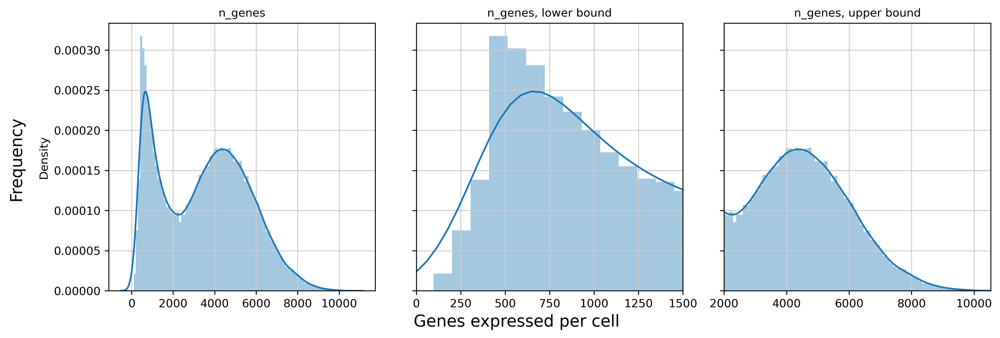

In [46]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['n_genes']
x_lowerbound = 1500
x_upperbound = 2000
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax3, norm_hist=True, bins=nbins)

ax2.set_xlim(0,x_lowerbound)
ax3.set_xlim(x_upperbound, adata.obs['n_genes'].max() )

for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('n_genes')
ax2.title.set_text('n_genes, lower bound')
ax3.title.set_text('n_genes, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Genes expressed per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Percentage of mitochondrial reads per cell

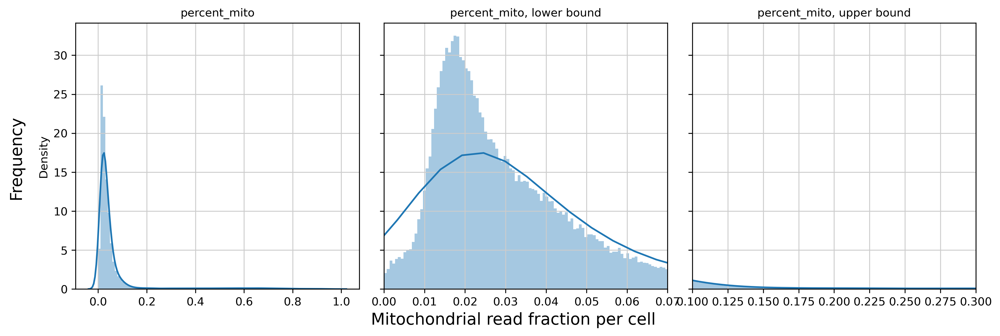

In [47]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['percent_mito']
x_lowerbound = [0.0, 0.07 ]
x_upperbound = [ 0.10, 0.3 ]
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=int(nbins/(x_lowerbound[1]-x_lowerbound[0])) )
sns.distplot(x, ax=ax3, norm_hist=True, bins=int(nbins/(x_upperbound[1]-x_upperbound[0])) )

ax2.set_xlim(x_lowerbound[0], x_lowerbound[1])
ax3.set_xlim(x_upperbound[0], x_upperbound[1] )
for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('percent_mito')
ax2.title.set_text('percent_mito, lower bound')
ax3.title.set_text('percent_mito, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Mitochondrial read fraction per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Three panel plot summary

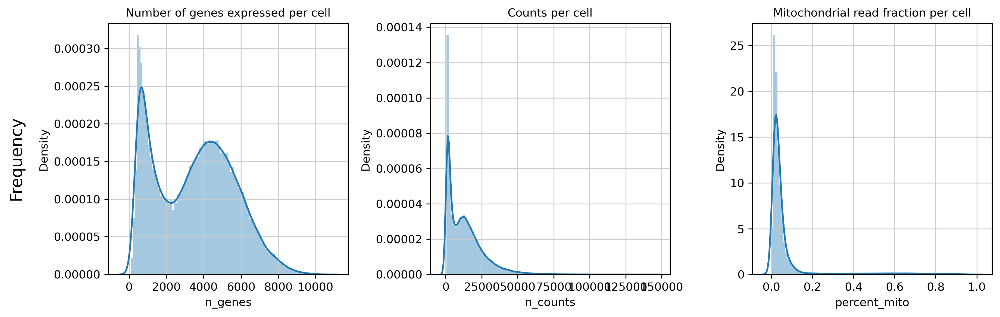

In [48]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel_prefilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

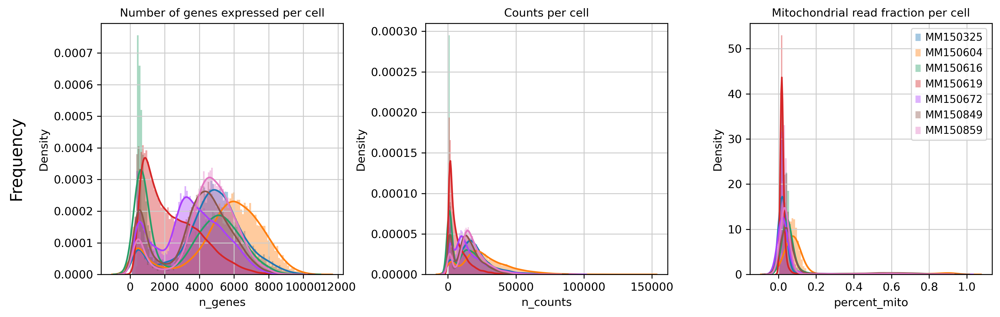

In [49]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.sample_ID): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel_prefilter_individual.pdf', dpi=600, bbox_inches='tight')

In [50]:
print(adata.var.index.is_unique)
adata.var_names_make_unique()
print(adata.var.index.is_unique)

True
True


In [51]:
adata.raw = adata
print(adata.raw.var.index.is_unique)

True


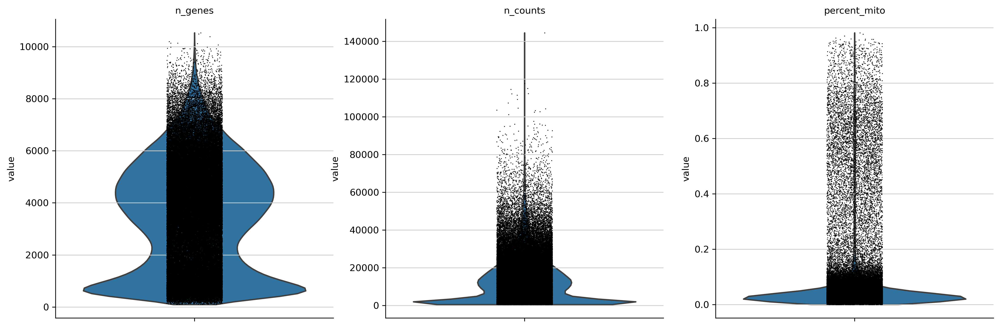

In [52]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts

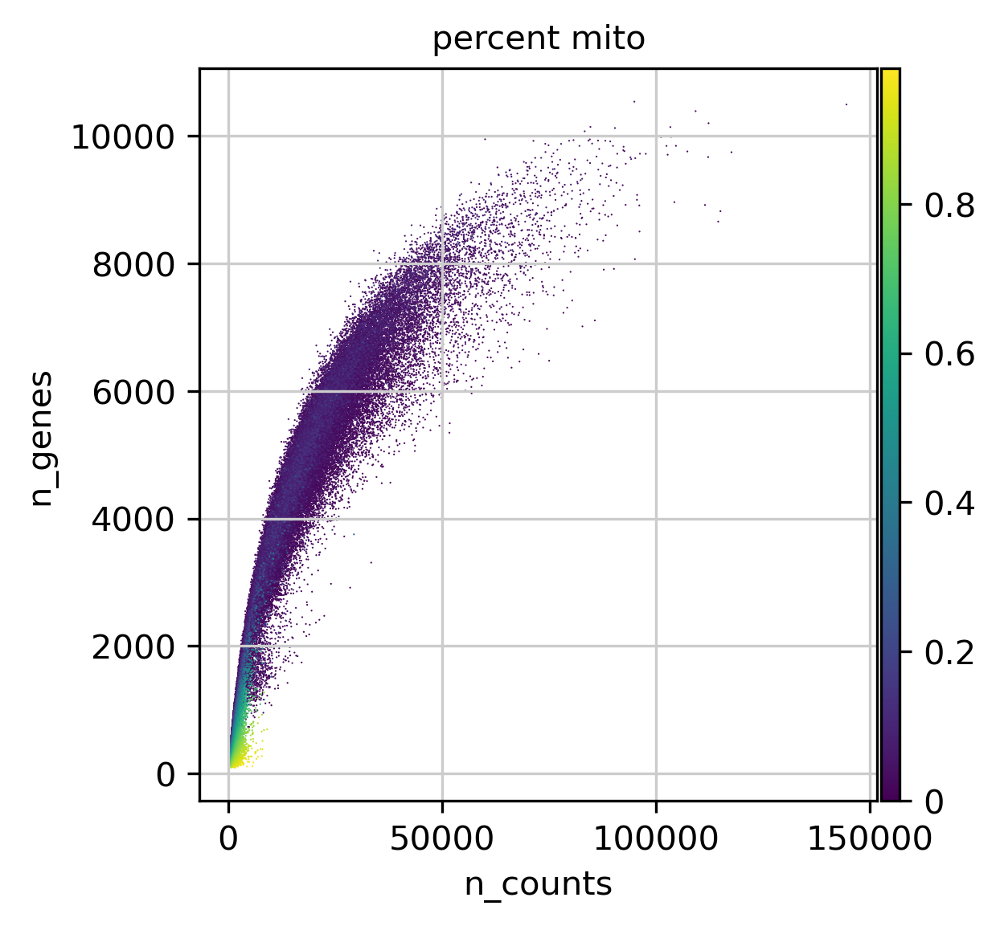

In [53]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

# Carry out filtering steps:

In [54]:
# initial cuts
sc.pp.filter_cells(adata, min_genes=200 )
sc.pp.filter_genes(adata, min_cells=3 )

filtered out 236 cells that have less than 200 genes expressed
filtered out 5040 genes that are detected in less than 3 cells


In [55]:
adata = adata[adata.obs['n_genes'] < 7000, :]
adata = adata[adata.obs['percent_mito'] < 0.15, :]

# Diagnostic plots, post filtering

### Three-panel summary plots 

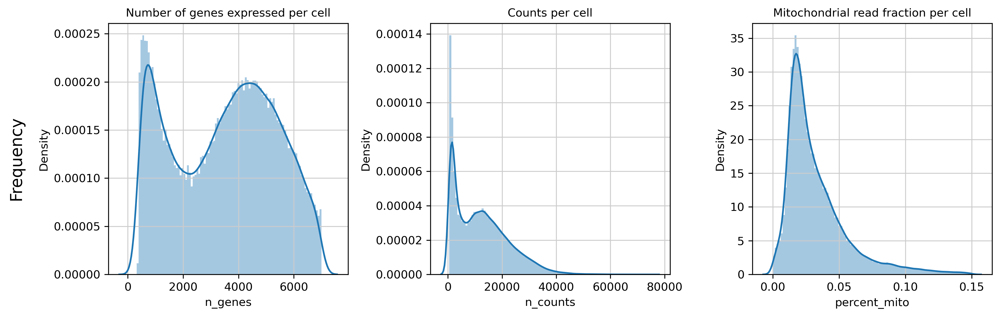

In [56]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

adata.obs['n_genes']

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel_postfilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

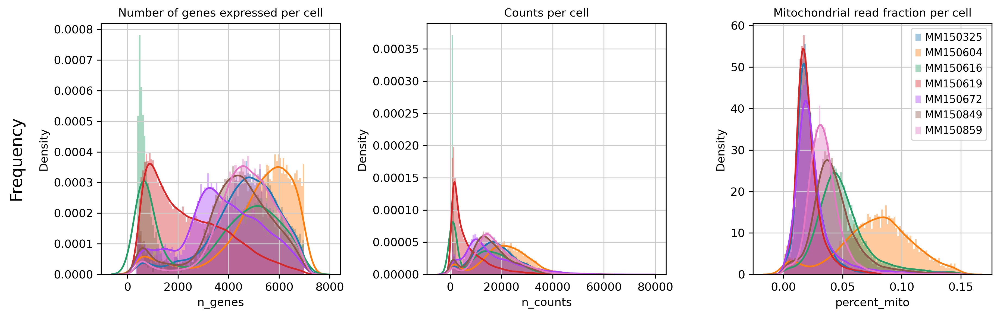

In [57]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.sample_ID): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.sample_ID == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel_postfilter_individual.pdf', dpi=600, bbox_inches='tight')

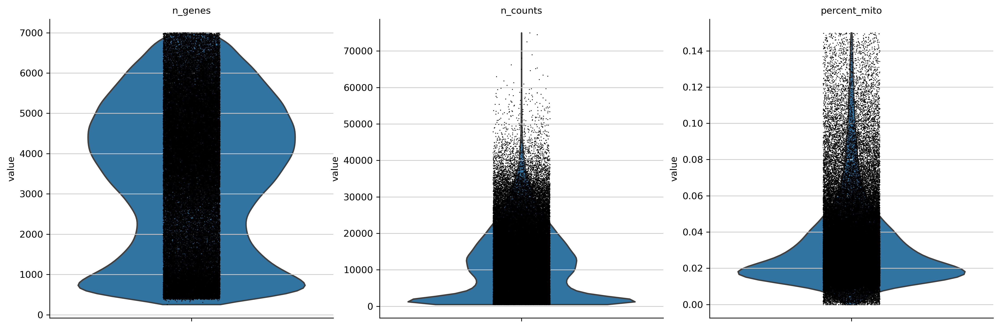

In [58]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts 

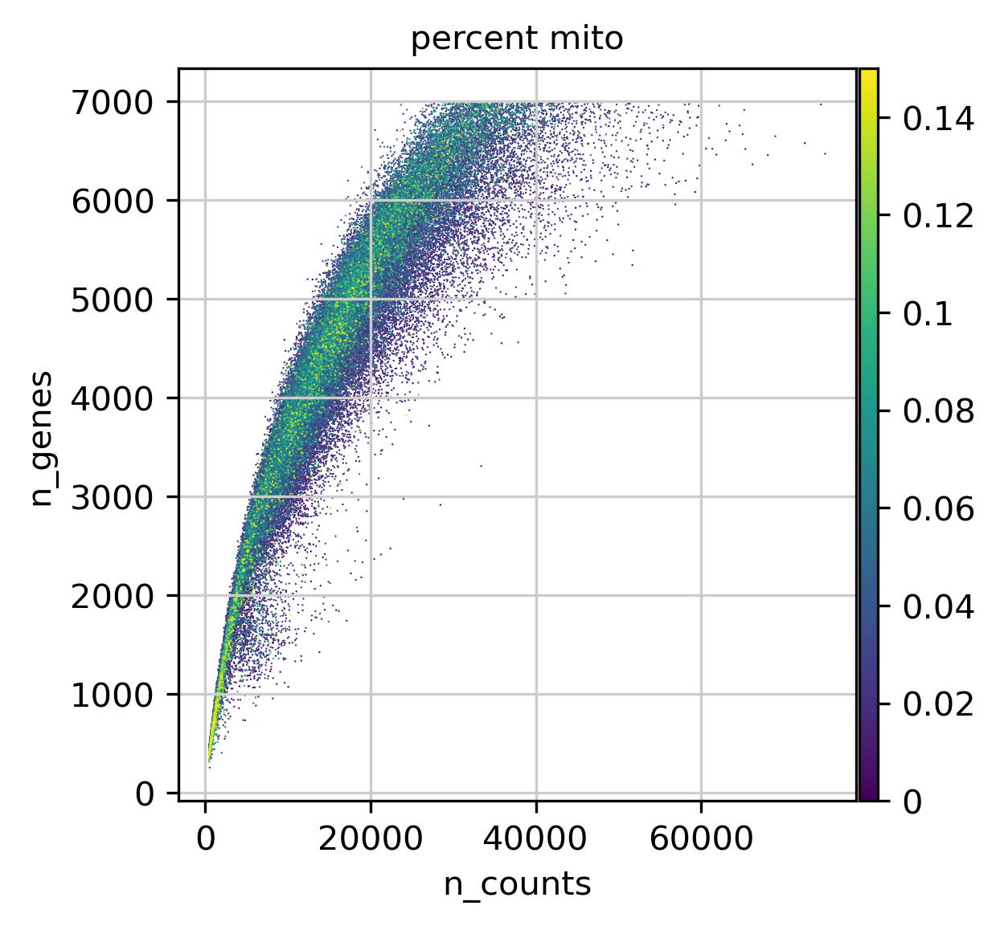

In [59]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

In [60]:
adata

View of AnnData object with n_obs × n_vars = 94012 × 31561
    obs: 'sample_ID', 'n_genes', 'percent_mito', 'n_counts'
    var: 'gene_ids', 'feature_types', 'n_cells'

In [74]:
adata.obs['n_counts'].sum()

1107913900.0

# Read in scATOMIC data to filter out all non-melanoma cells

In [61]:
scATOMIC_MM150325_f = "scATOMIC_files/RE_V600E Mutants/20260604.0857.MM150325.scATOMIC_pred.tsv"
scATOMIC_MM150604_f = "scATOMIC_files/RE_V600E Mutants/20260604.0903.MM150604.scATOMIC_pred.tsv"
scATOMIC_MM150616_f = "scATOMIC_files/RE_V600E Mutants/20260604.0906.MM150616.scATOMIC_pred.tsv"
scATOMIC_MM150619_f = "scATOMIC_files/RE_V600E Mutants/20260604.1019.MM150619.scATOMIC_pred.tsv"
scATOMIC_MM150672_f = "scATOMIC_files/RE_V600E Mutants/20260604.1217.MM150672.scATOMIC_pred.tsv"
scATOMIC_MM150849_f ="scATOMIC_files/RE_V600E Mutants/20260604.1228.MM150849.scATOMIC_pred.tsv"
scATOMIC_MM150859_f ="scATOMIC_files/RE_V600E Mutants/20260604.1237.MM150859.scATOMIC_pred.tsv"

scATOMIC_MM150325_df = pd.read_csv(scATOMIC_MM150325_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150604_df = pd.read_csv(scATOMIC_MM150604_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150616_df = pd.read_csv(scATOMIC_MM150616_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150619_df = pd.read_csv(scATOMIC_MM150619_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150672_df = pd.read_csv(scATOMIC_MM150672_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150849_df = pd.read_csv(scATOMIC_MM150849_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")
scATOMIC_MM150859_df = pd.read_csv(scATOMIC_MM150859_f, sep='\t', usecols=['cell_names', 'sample', 'scATOMIC_pred'], index_col = "cell_names")

In [63]:
adata.obs['scATOMIC_pred'] = ''

adata.obs.loc[scATOMIC_MM150325_df.index, "scATOMIC_pred"] = scATOMIC_MM150325_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150604_df.index, "scATOMIC_pred"] = scATOMIC_MM150604_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150616_df.index, "scATOMIC_pred"] = scATOMIC_MM150616_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150619_df.index, "scATOMIC_pred"] = scATOMIC_MM150619_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150672_df.index, "scATOMIC_pred"] = scATOMIC_MM150672_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150849_df.index, "scATOMIC_pred"] = scATOMIC_MM150849_df['scATOMIC_pred']
adata.obs.loc[scATOMIC_MM150859_df.index, "scATOMIC_pred"] = scATOMIC_MM150859_df['scATOMIC_pred']

# replace melanoma_known_cancer_type to melanoma
melanoma_rename_dict = {"melanoma_known_cancer_type": "Melanoma",
                        "CAFadi": "CAF",
                        "CAFinfla": "CAF",
                        "Cancer Associated Fibroblasts": "CAF"}
adata.obs['scATOMIC_pred'] = adata.obs['scATOMIC_pred'].replace(melanoma_rename_dict)

In [64]:
adata

AnnData object with n_obs × n_vars = 94012 × 31561
    obs: 'sample_ID', 'n_genes', 'percent_mito', 'n_counts', 'scATOMIC_pred'
    var: 'gene_ids', 'feature_types', 'n_cells'

In [65]:
np.unique(adata.obs.scATOMIC_pred)

array(['CAF', 'Melanoma', 'Non Blood Cell', 'Non Stromal Cell',
       'Normal Fibroblast'], dtype=object)

In [66]:
adata.obs

,sample_ID,n_genes,percent_mito,n_counts,scATOMIC_pred
AAACCCAAGCTCATAC-1,MM150325,6279,0.016898,28288.0,Melanoma
AAACCCAAGTCCCGGT-1,MM150325,5447,0.015108,24623.0,Melanoma
AAACCCACAACGACTT-1,MM150325,4999,0.009816,18440.0,Melanoma
AAACCCACAATGTCTG-1,MM150325,5730,0.014399,23890.0,Melanoma
AAACCCACATAGATGA-1,MM150325,2698,0.000111,8983.0,Melanoma
...,...,...,...,...,...
TTTGTTGCATACAGCT-7,MM150859,4726,0.024879,16560.0,Melanoma
TTTGTTGCATTGAAAG-7,MM150859,3776,0.045615,11926.0,Melanoma
TTTGTTGGTCGGCACT-7,MM150859,3431,0.041059,9182.0,Melanoma
TTTGTTGGTGGTAACG-7,MM150859,4578,0.021570,20770.0,Melanoma


In [69]:
# Percentage breakdown by STMC
adata.obs.groupby("sample_ID")['scATOMIC_pred'].value_counts(normalize=True).unstack(fill_value=0) * 100

scATOMIC_pred,CAF,Melanoma,Non Blood Cell,Non Stromal Cell,Normal Fibroblast
sample_ID,,,,,
MM150325,0.026734,99.852961,0.120305,0.000000,0.000000
MM150604,0.000000,100.000000,0.000000,0.000000,0.000000
MM150616,0.000000,98.859346,1.140654,0.000000,0.000000
MM150619,0.588499,99.007732,0.000000,0.184731,0.219038
MM150672,38.548614,58.213408,1.930502,0.000000,1.307476
MM150849,0.000000,100.000000,0.000000,0.000000,0.000000
MM150859,0.000000,99.662554,0.337446,0.000000,0.000000


In [70]:
# Filter out cells that are non-melanoma
adata = adata[adata.obs['scATOMIC_pred'] == 'Melanoma', :].copy()
adata

AnnData object with n_obs × n_vars = 88689 × 31561
    obs: 'sample_ID', 'n_genes', 'percent_mito', 'n_counts', 'scATOMIC_pred'
    var: 'gene_ids', 'feature_types', 'n_cells'

In [71]:
adata

AnnData object with n_obs × n_vars = 88689 × 31561
    obs: 'sample_ID', 'n_genes', 'percent_mito', 'n_counts', 'scATOMIC_pred'
    var: 'gene_ids', 'feature_types', 'n_cells'

In [72]:
np.unique(adata.obs.scATOMIC_pred)

array(['Melanoma'], dtype=object)

# Finalize the selected filters

Update the anndata file, to be used for further processing, clustering, visualization, etc..

In [200]:
adata.write( f_anndata_path )

# Further preprocessing of expression data

### Add in Treatment column to adata.obs

In [201]:
treat_dict = {'MM150325': 'tx_naive',
              'MM150604': 'After_Ipi',
              'MM150616': 'BRAF/MEKi', 
              'MM150619': 'BRAF/MEKi',
              'MM150672': 'BRAF/MEKi',
              'MM150849': 'BRAK/MEKi+CDK4/6i', 
              'MM150859': 'BRAK/MEKi+CDK4/6i'}

adata.obs["Treatment"] = adata.obs["sample_ID"].map(treat_dict)

### Add in Site column to adata.obs

In [202]:
site_dict = {'MM150325': 'Breast',
              'MM150604': 'Breast',
              'MM150616': 'Breast', 
              'MM150619': 'Breast',
              'MM150672': 'Breast',
              'MM150849': 'Bone', 
              'MM150859': 'Brain'}

adata.obs["Site"] = adata.obs["sample_ID"].map(site_dict)

### Add in Sensitivity column to adata.obs

In [203]:
sensitivity_dict = {'MM150325': 'Resistant',
              'MM150604': 'Sensitive',
              'MM150616': 'Intermediate', 
              'MM150619': 'Resistant',
              'MM150672': 'Intermediate',
              'MM150849': 'Intermediate', 
              'MM150859': 'Sensitive'}

adata.obs["Sensitivity"] = adata.obs["sample_ID"].map(sensitivity_dict)

normalizing by total count per cell
    finished (0:00:06): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
normalizing by total count per cell
    finished (0:00:01): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
extracting highly variable genes
    finished (0:00:07)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


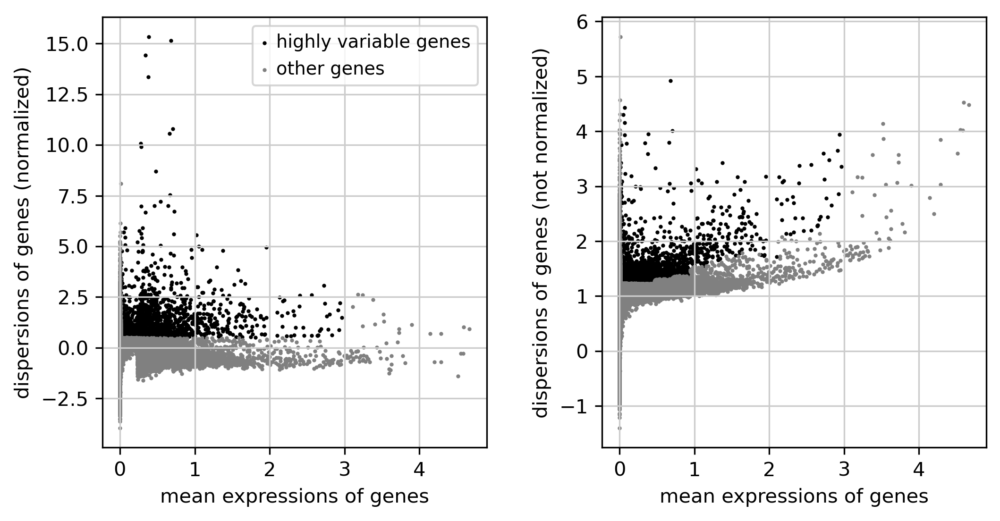

extracting highly variable genes
    finished (0:00:01)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


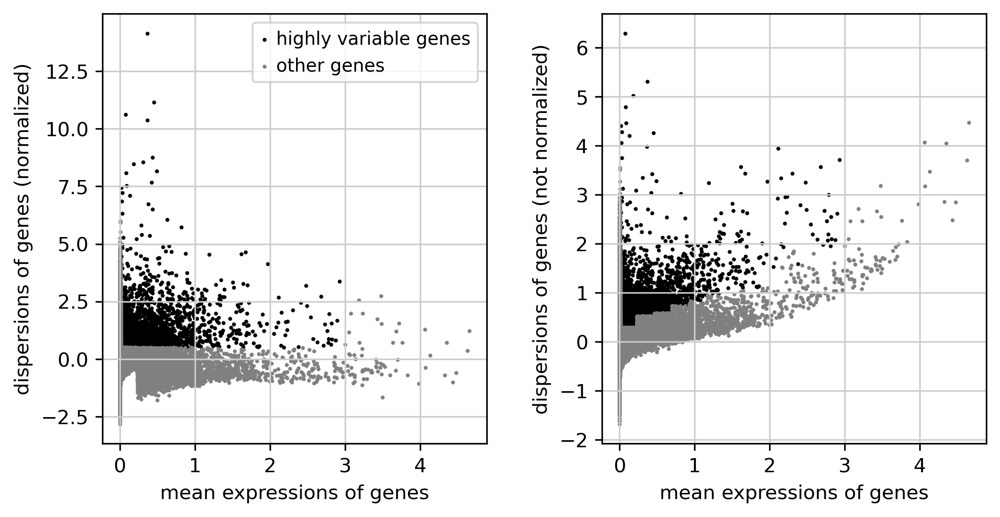

regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (0:03:16)
regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (0:53:06)
regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (0:00:25)
regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (0:02:59)


In [204]:
# save a copy of the raw data
adata.raw = adata

# 325 subset
adata_325 = adata[adata.obs.sample_ID == "MM150325"]

# Total-count normalize (library-size correct) to 10,000 reads/cell
sc.pp.normalize_per_cell(adata, counts_per_cell_after=1e4)
sc.pp.normalize_per_cell(adata_325, counts_per_cell_after=1e4)

# log transform the data.
sc.pp.log1p(adata)
sc.pp.log1p(adata_325)

# identify highly variable genes.
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)

sc.pp.highly_variable_genes(adata_325, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata_325)

# keep only highly variable genes:
adata_hvg = adata[:, adata.var['highly_variable']].copy()
adata_325_hvg = adata_325[:, adata_325.var['highly_variable']].copy()

# regress out total counts per cell and the percentage of mitochondrial genes expressed
sc.pp.regress_out(adata_hvg, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)
sc.pp.regress_out(adata, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)

sc.pp.regress_out(adata_325_hvg, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)
sc.pp.regress_out(adata_325, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)

# scale each gene to unit variance, clip values exceeding SD 10.
sc.pp.scale(adata_hvg, max_value=10)
sc.pp.scale(adata, max_value=10)

sc.pp.scale(adata_325_hvg, max_value=10)
sc.pp.scale(adata_325, max_value=10)

In [205]:
adata

AnnData object with n_obs × n_vars = 88689 × 31159
    obs: 'sample_ID', 'scATOMIC_pred', 'n_genes', 'percent_mito', 'n_counts', 'Treatment', 'Site', 'Sensitivity'
    var: 'gene_ids', 'feature_types', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [206]:
adata_hvg

AnnData object with n_obs × n_vars = 88689 × 2718
    obs: 'sample_ID', 'scATOMIC_pred', 'n_genes', 'percent_mito', 'n_counts', 'Treatment', 'Site', 'Sensitivity'
    var: 'gene_ids', 'feature_types', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [207]:
adata_325

AnnData object with n_obs × n_vars = 7470 × 31159
    obs: 'sample_ID', 'scATOMIC_pred', 'n_genes', 'percent_mito', 'n_counts', 'Treatment', 'Site', 'Sensitivity'
    var: 'gene_ids', 'feature_types', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [208]:
adata_325_hvg

AnnData object with n_obs × n_vars = 7470 × 4890
    obs: 'sample_ID', 'scATOMIC_pred', 'n_genes', 'percent_mito', 'n_counts', 'Treatment', 'Site', 'Sensitivity'
    var: 'gene_ids', 'feature_types', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [209]:
# update the anndata file:
adata.write( f_anndata_path )
adata_hvg.write( f_anndata_hvg_path )

### 1 PCA

computing PCA
    on highly variable genes
    with n_comps=500
    finished (0:01:01)


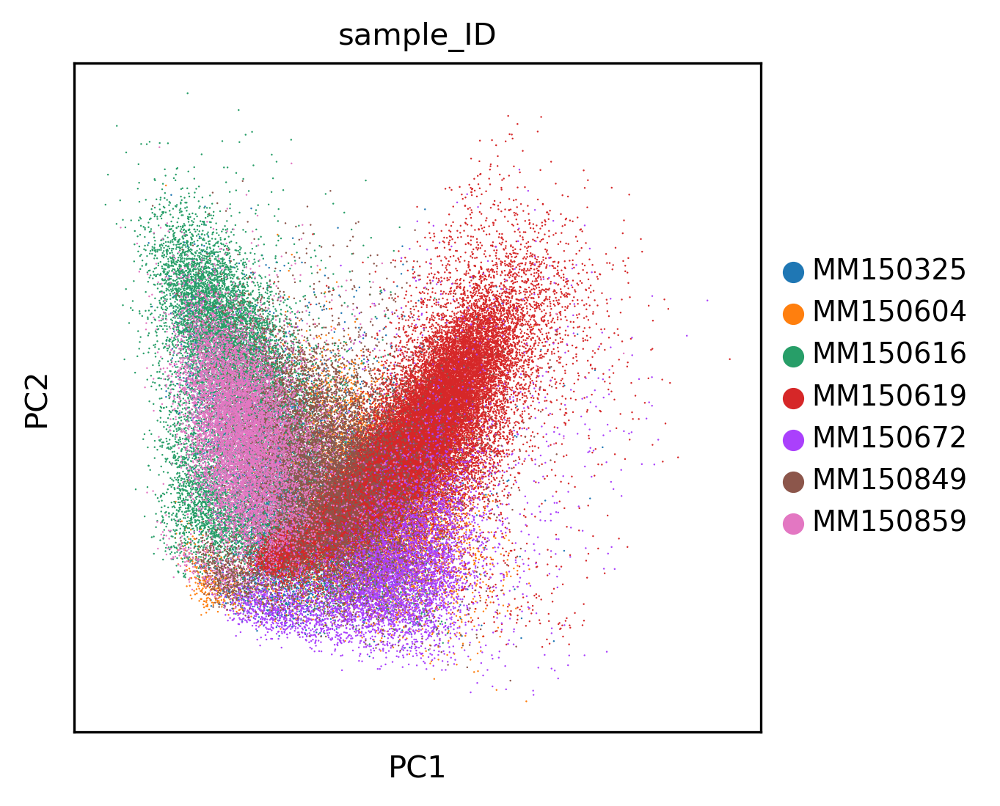

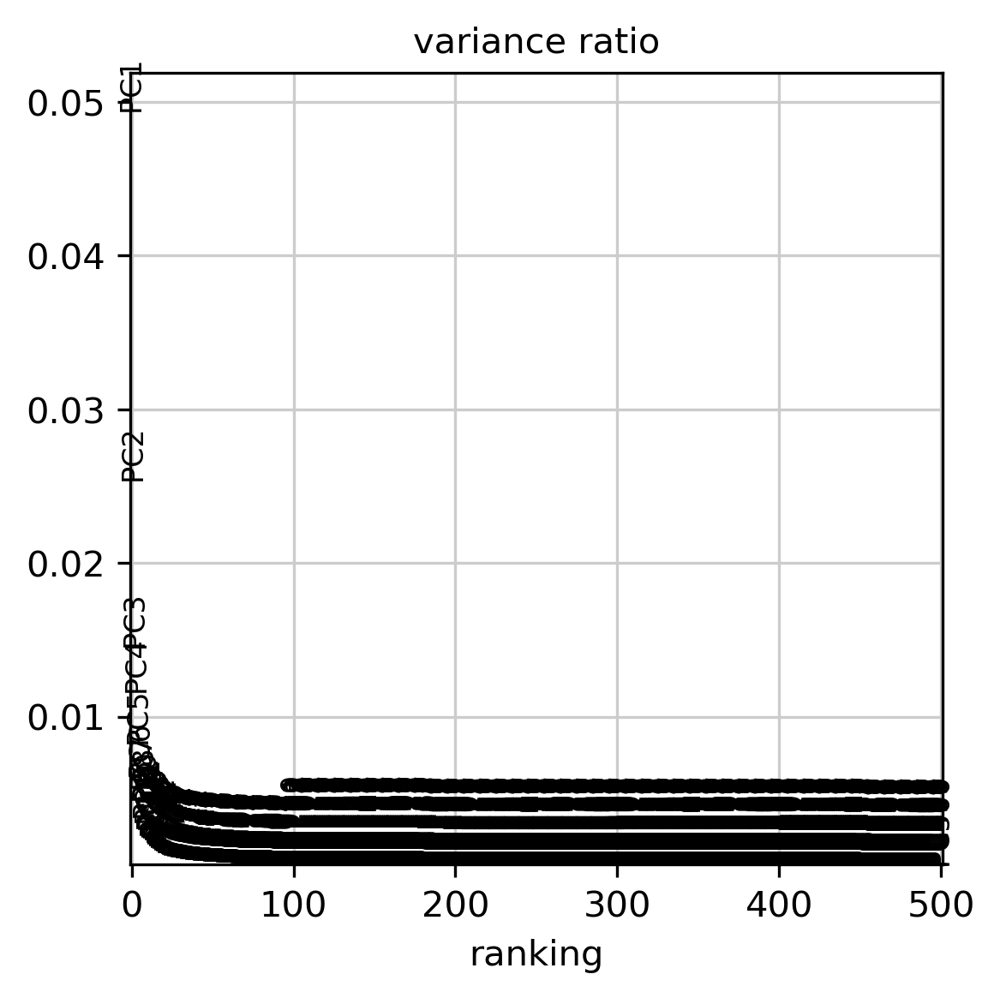

In [210]:
# principal component analysis
sc.tl.pca(adata_hvg, n_comps = 500, svd_solver='arpack')
sc.pl.pca(adata_hvg, color = 'sample_ID')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs= 500, log=False)
adata_hvg.write( f_anndata_hvg_path )

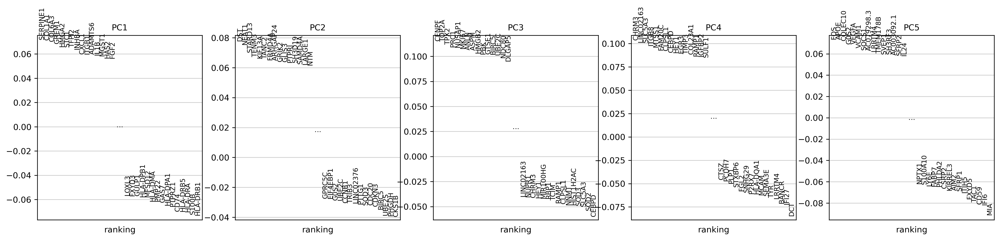

In [211]:
sc.pl.pca_loadings(adata_hvg, components = [1,2,3,4,5])

### 2 Visualization of highly variable genes 

In [212]:
# neighborhood graph of cells (determine optimal number of PCs here)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=50, random_state = 42)
# compute UMAP
sc.tl.umap(adata_hvg, random_state = 42)
# tSNE
sc.tl.tsne(adata_hvg, n_pcs=50, random_state = 42)

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:11)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:01:17)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:04:53)


In [213]:
adata_hvg.write( f_anndata_hvg_path )
adata.write( f_anndata_path )

# Fig. 2A

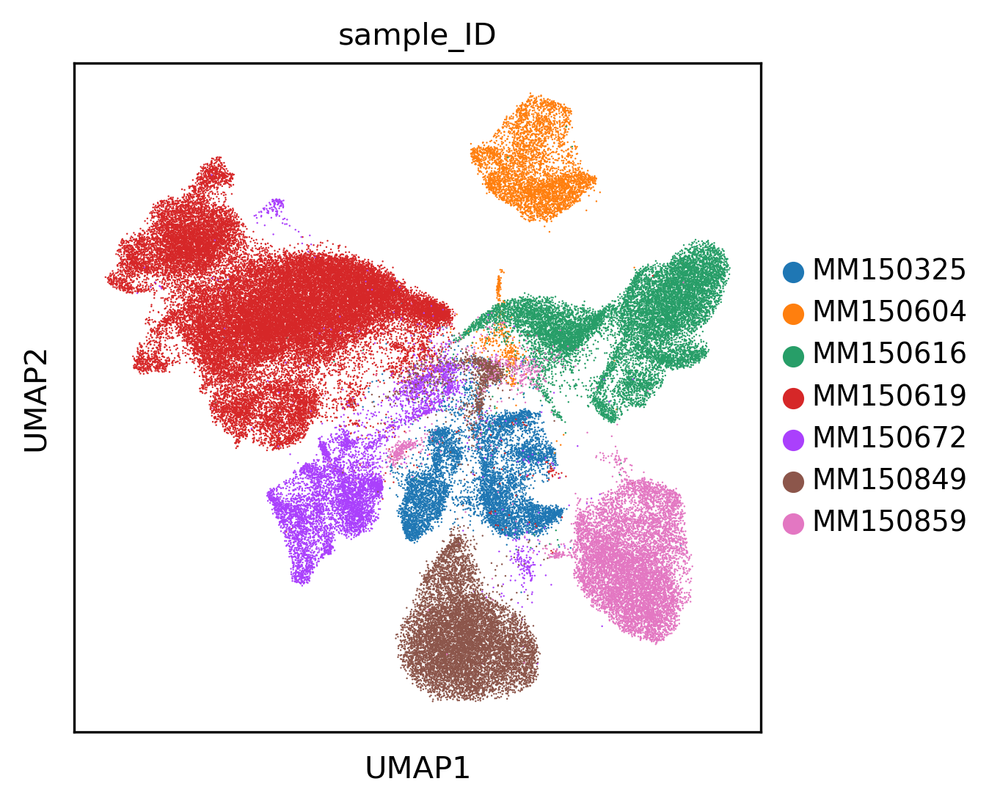

In [214]:
sc.pl.umap(adata_hvg, color = 'sample_ID', projection = '2d')

# Fig. EV2B

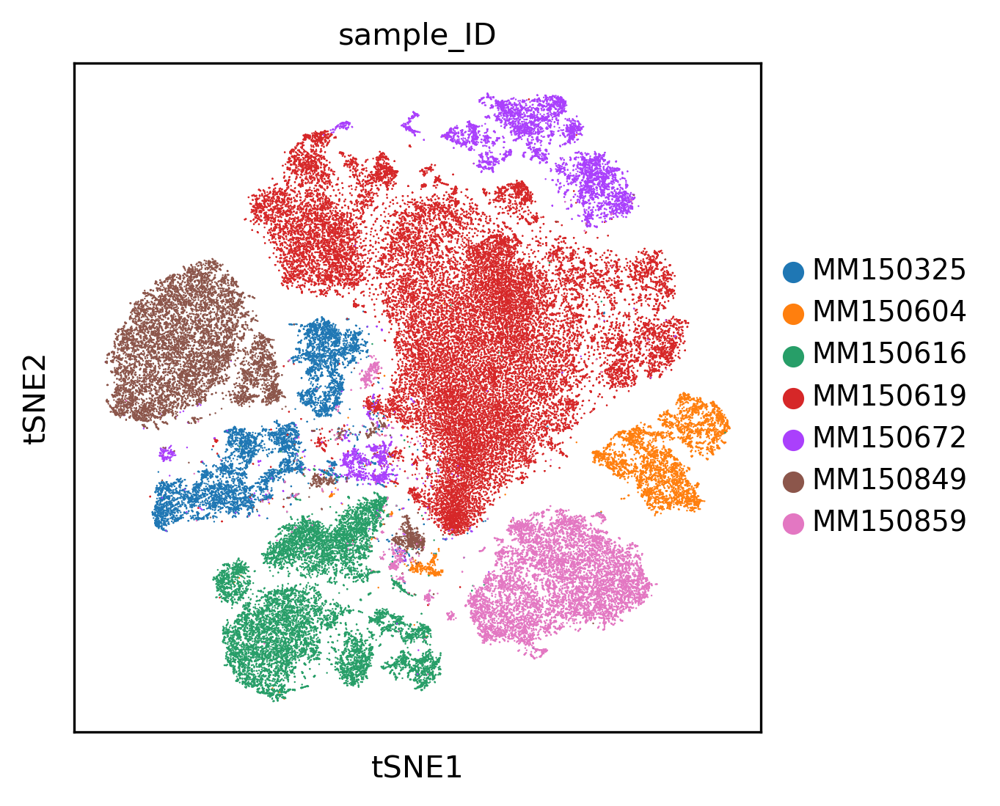

In [215]:
sc.pl.tsne(adata_hvg, color='sample_ID')

In [216]:
# neighborhood graph of cells (determine optimal number of PCs here)
sc.pp.neighbors(adata_325_hvg, n_neighbors=15, n_pcs=50, random_state = 42)
# compute UMAP
sc.tl.umap(adata_325_hvg, random_state = 42)
# tSNE
sc.tl.tsne(adata_325_hvg, n_pcs=50, random_state = 42)

computing neighbors
         Falling back to preprocessing with `sc.pp.pca` and default params.
computing PCA
    with n_comps=50
    finished (0:00:01)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:14)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:12)


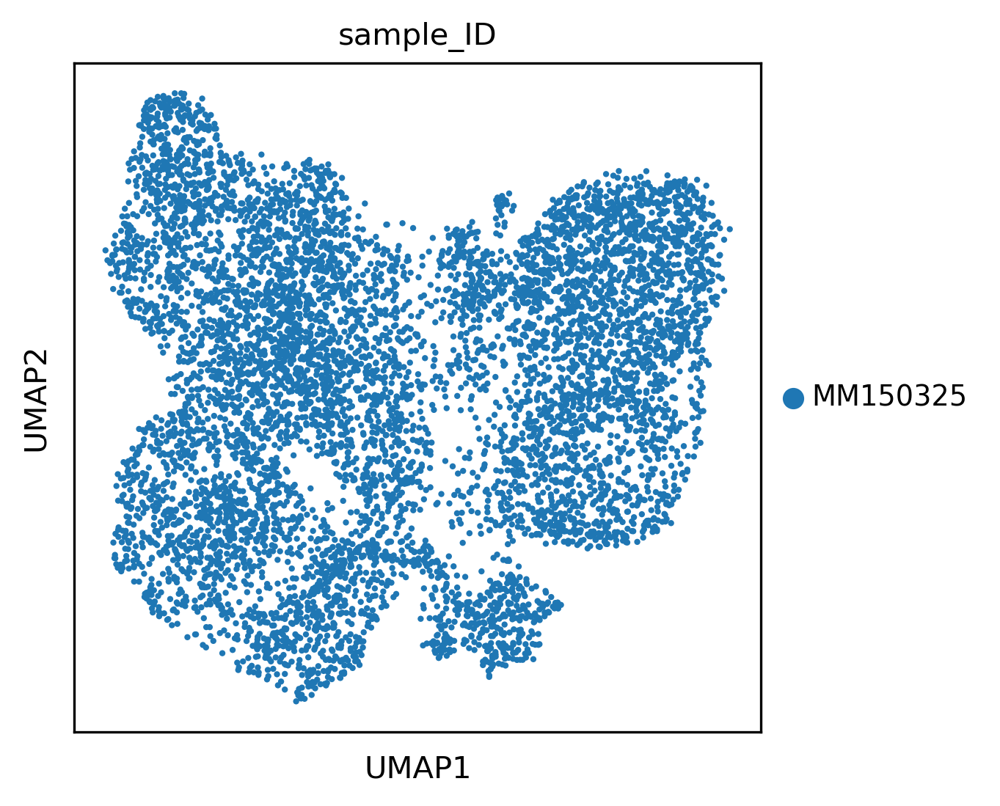

In [217]:
sc.pl.umap(adata_325_hvg, color = 'sample_ID', projection = '2d')

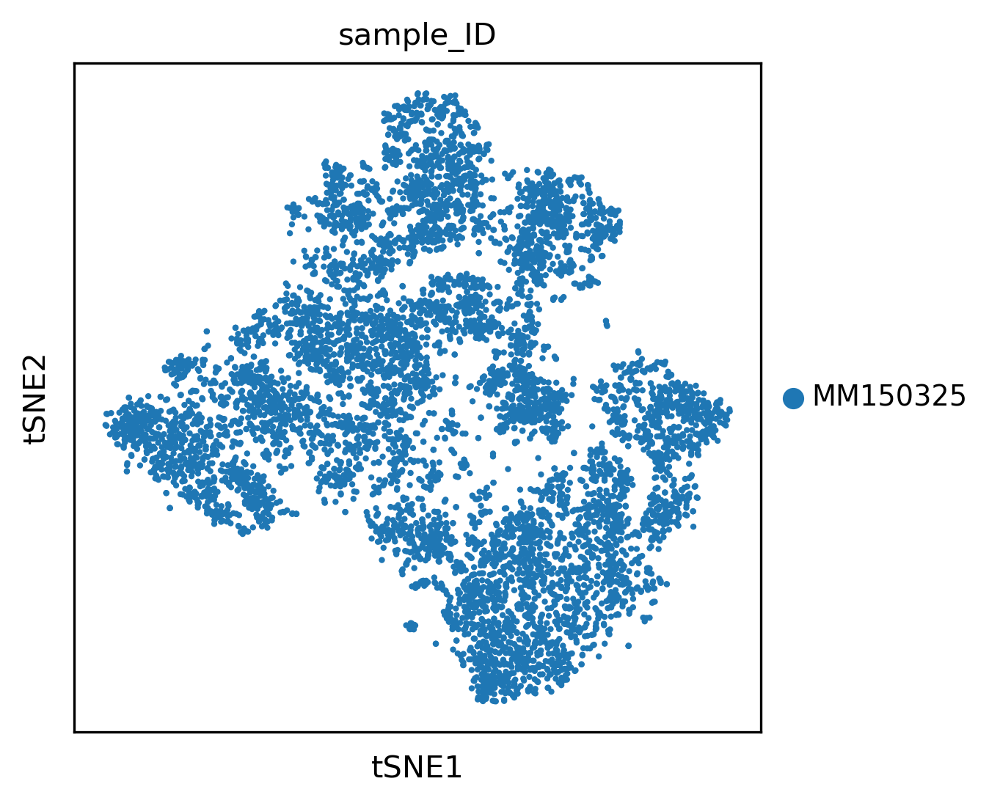

In [218]:
sc.pl.tsne(adata_325_hvg, color='sample_ID')

### 3 Clustering 

In [219]:
# cluster the neighbourhood graph
sc.tl.louvain(adata_hvg,resolution=0.4)

running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 13 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:25)


# Fig. 2B

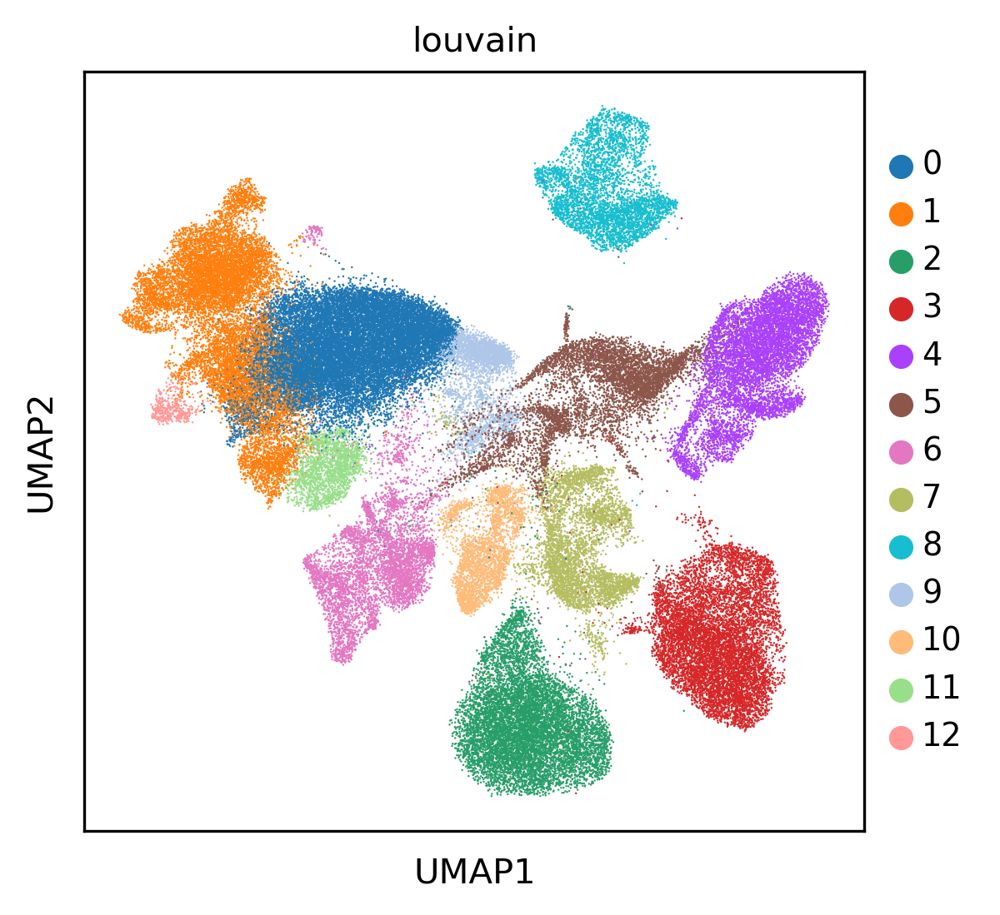

In [220]:
sc.pl.umap(adata_hvg, color=['louvain'] )

# Fig. EV2C

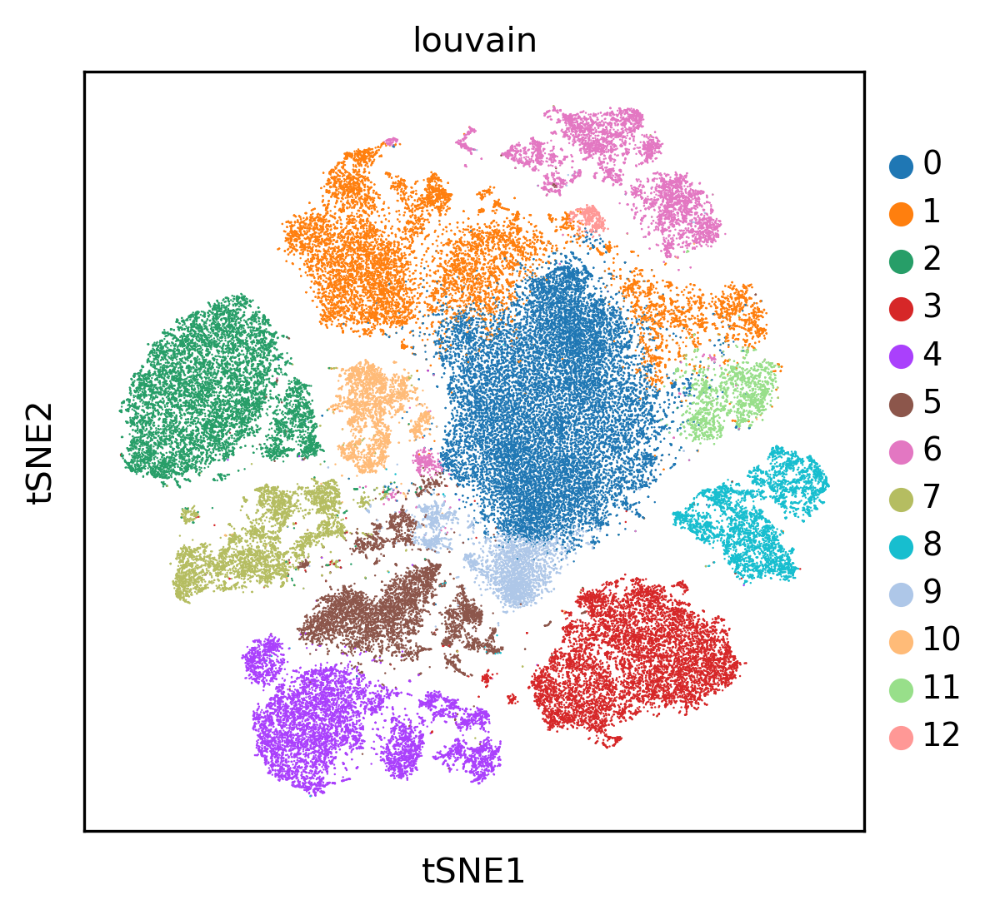

In [221]:
sc.pl.tsne(adata_hvg, color='louvain')

### add original louvain to adata_325_hvg object and plot umap and tsne

In [222]:
adata_325_hvg.obs['louvain'] = adata_hvg.obs[adata_hvg.obs.sample_ID == "MM150325"]["louvain"]

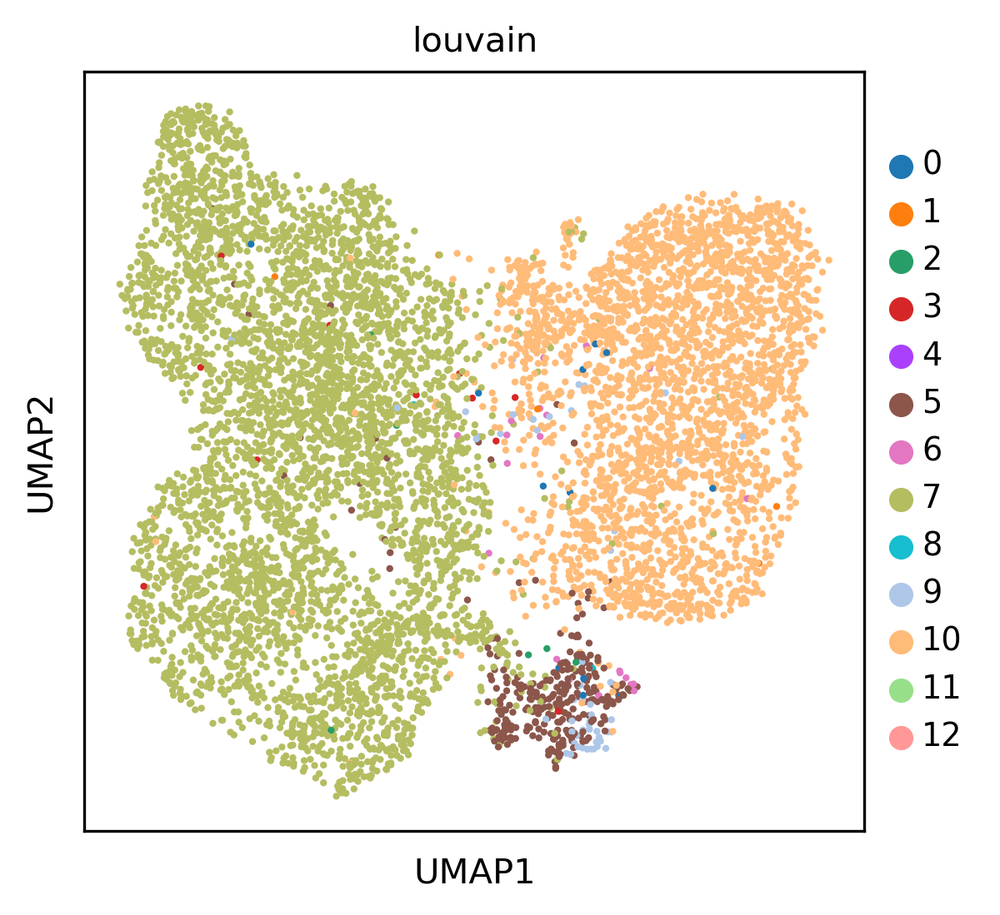

In [223]:
sc.pl.umap(adata_325_hvg, color=['louvain'] )

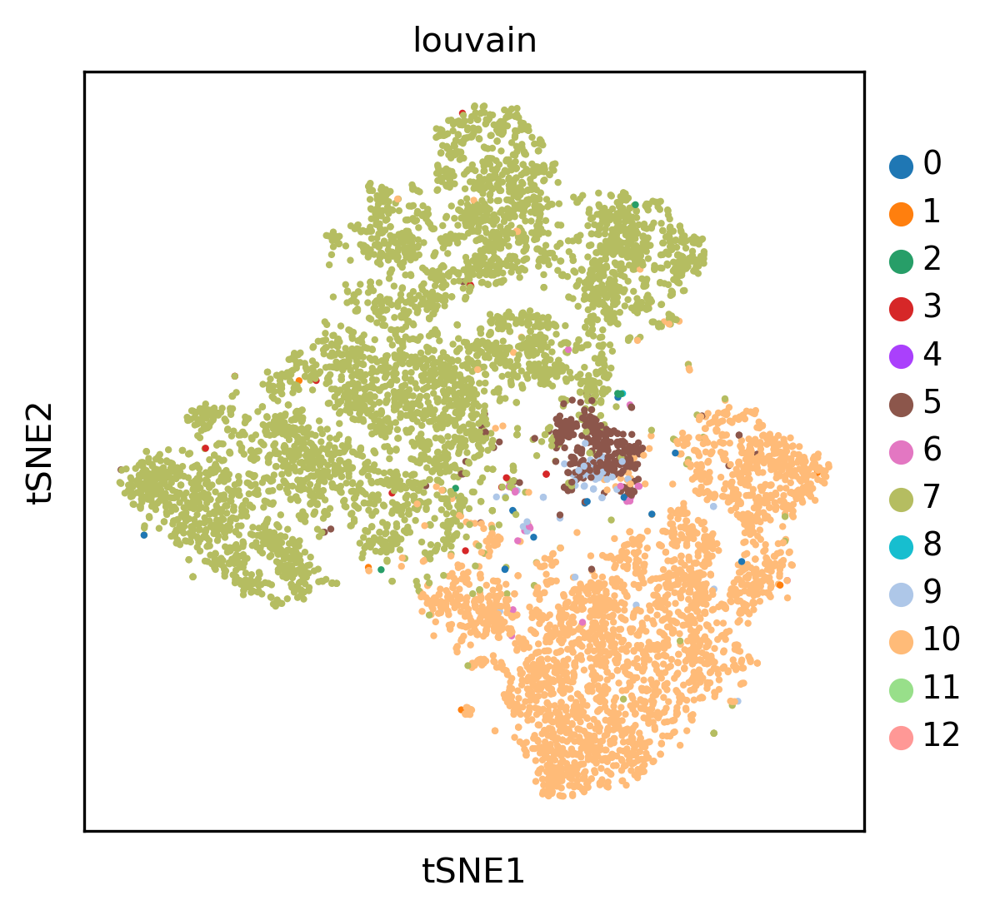

In [224]:
sc.pl.tsne(adata_325_hvg, color='louvain')

### Louvain cluster percentage breakdown

In [225]:
adata_hvg.obs

,sample_ID,scATOMIC_pred,n_genes,percent_mito,n_counts,Treatment,Site,Sensitivity,louvain
AAACCCAAGCTCATAC-1,MM150325,Melanoma,6279,0.016898,28288.0,tx_naive,Breast,Resistant,7
AAACCCAAGTCCCGGT-1,MM150325,Melanoma,5447,0.015108,24623.0,tx_naive,Breast,Resistant,7
AAACCCACAACGACTT-1,MM150325,Melanoma,4999,0.009816,18440.0,tx_naive,Breast,Resistant,10
AAACCCACAATGTCTG-1,MM150325,Melanoma,5730,0.014399,23890.0,tx_naive,Breast,Resistant,10
AAACCCACATAGATGA-1,MM150325,Melanoma,2698,0.000111,8983.0,tx_naive,Breast,Resistant,9
...,...,...,...,...,...,...,...,...,...
TTTGTTGCATACAGCT-7,MM150859,Melanoma,4726,0.024879,16560.0,BRAK/MEKi+CDK4/6i,Brain,Sensitive,3
TTTGTTGCATTGAAAG-7,MM150859,Melanoma,3776,0.045615,11926.0,BRAK/MEKi+CDK4/6i,Brain,Sensitive,3
TTTGTTGGTCGGCACT-7,MM150859,Melanoma,3431,0.041059,9182.0,BRAK/MEKi+CDK4/6i,Brain,Sensitive,3
TTTGTTGGTGGTAACG-7,MM150859,Melanoma,4578,0.021570,20770.0,BRAK/MEKi+CDK4/6i,Brain,Sensitive,3


In [226]:
# counts per (sample_ID, Louvain_clusters_Scanpy)
counts = (
    adata_hvg.obs
    .groupby(["sample_ID", "louvain"])
    .size()
    .reset_index(name="count")
)

# total counts per sample_ID
totals = (
    adata_hvg.obs
    .groupby("sample_ID")
    .size()
    .reset_index(name="total")
)

# merge and compute percentage
result = counts.merge(totals, on="sample_ID")
result["percentage"] = result["count"] / result["total"] * 100

result

,sample_ID,louvain,count,total,percentage
0,MM150325,0,12,7470,0.160643
1,MM150325,1,5,7470,0.066934
2,MM150325,2,6,7470,0.080321
3,MM150325,3,11,7470,0.147256
4,MM150325,4,0,7470,0.000000
...,...,...,...,...,...
86,MM150859,8,0,9451,0.000000
87,MM150859,9,13,9451,0.137552
88,MM150859,10,235,9451,2.486509
89,MM150859,11,0,9451,0.000000


In [227]:
percent_table = (
    pd.crosstab( adata_hvg.obs["sample_ID"],  adata_hvg.obs["louvain"].astype(int), normalize="index") * 100
)

percent_table = percent_table.round(2)

percent_table

louvain,0,1,2,3,4,5,6,7,8,9,10,11,12
sample_ID,,,,,,,,,,,,,
MM150325,0.16,0.07,0.08,0.15,0.00,3.88,0.29,58.92,0.03,0.71,35.72,0.00,0.00
MM150604,0.14,0.02,0.02,0.06,0.18,8.32,0.04,0.06,91.00,0.12,0.02,0.00,0.00
MM150616,0.10,0.01,0.02,0.12,65.86,33.74,0.00,0.09,0.04,0.02,0.01,0.00,0.00
MM150619,50.70,34.50,0.00,0.02,0.00,0.04,0.82,0.33,0.00,6.90,0.06,5.52,1.11
MM150672,0.57,0.50,0.48,0.18,0.09,6.74,80.12,2.43,0.02,8.65,0.12,0.11,0.00
MM150849,0.06,0.01,91.27,0.05,0.02,8.10,0.09,0.31,0.01,0.08,0.02,0.00,0.00
MM150859,0.13,0.02,0.04,93.60,0.04,3.14,0.16,0.24,0.00,0.14,2.49,0.00,0.00


# Fig. EV2A

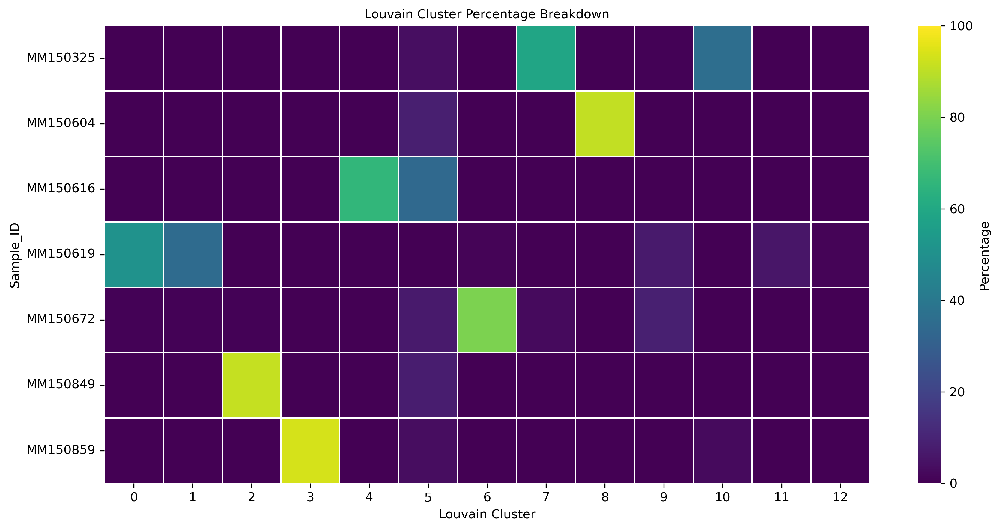

In [228]:
plt.figure(figsize=(12, 6))
sns.heatmap(
    percent_table,
    vmin=0, vmax=100,
    cmap="viridis",
    cbar_kws={"label": "Percentage"},
    linewidths=0.5,
    annot=False, fmt=".2f",
    annot_kws={"size": 8}
)
"""
for t in ax.texts:
    t.set_fontname("Arial")
    t.set_fontsize(8)
"""
plt.xlabel("Louvain Cluster")
plt.ylabel("Sample_ID")
plt.title("Louvain Cluster Percentage Breakdown")
plt.tight_layout()
plt.show()

## Marker genes

# Fig. 2D

### 325 sample, louvain clusters 10 and 7

In [229]:
adata.obs['louvain'] = adata_hvg.obs['louvain']

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:10)


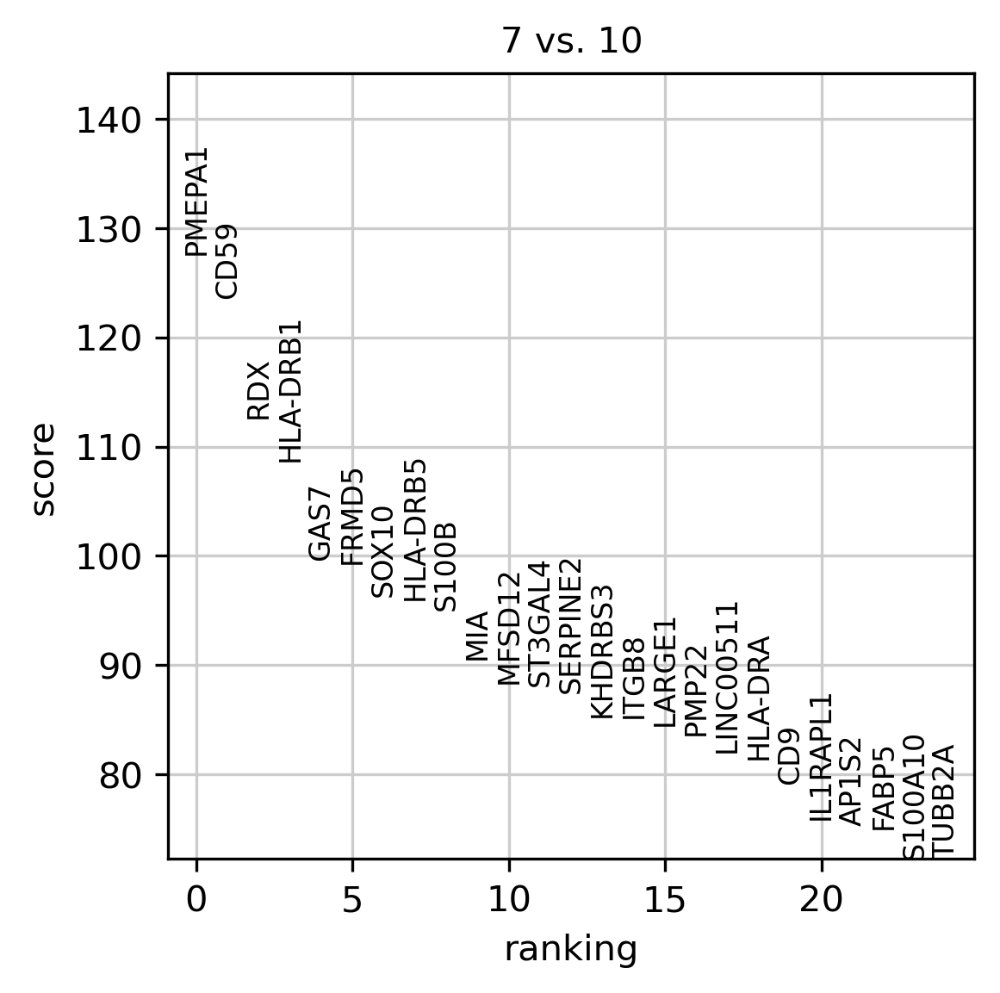

In [230]:
sc.tl.rank_genes_groups(adata, groupby = 'louvain', groups = ["7"], reference = "10", method='t-test', use_raw = False)
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:10)


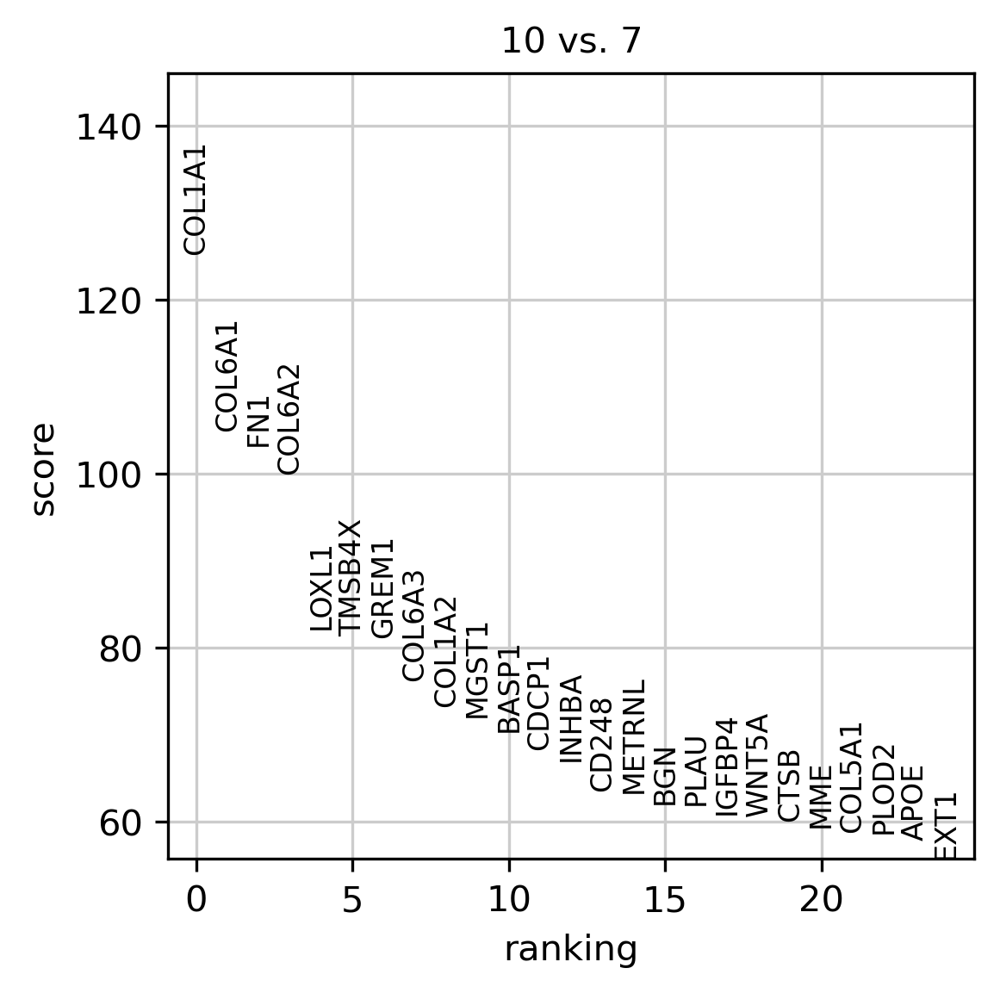

In [231]:
sc.tl.rank_genes_groups(adata, groupby = 'louvain', groups = ["10"], reference = "7", method='t-test', use_raw = False)
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

### Site

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:02:45)


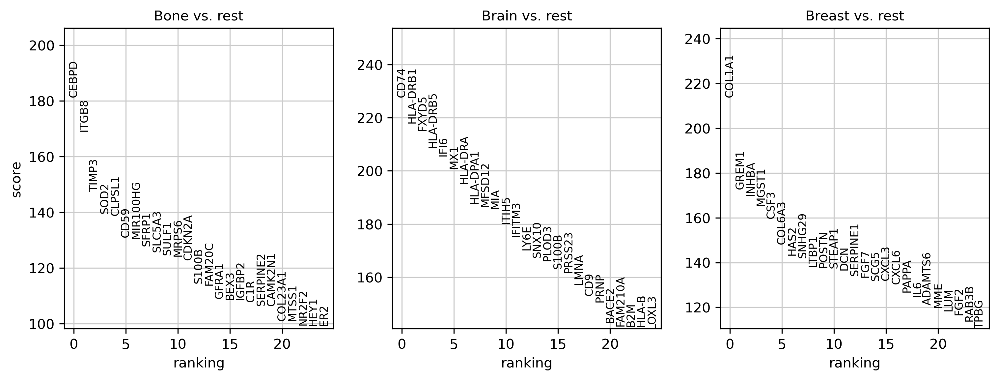

In [232]:
sc.tl.rank_genes_groups(adata, groupby = 'Site', method='t-test', use_raw = False)
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

In [233]:
site_gene_ranks = sc.get.rank_genes_groups_df(adata, group = None)

In [234]:
site_gene_ranks

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,Bone,CEBPD,181.257263,NaN,0.0,0.0
1,Bone,ITGB8,169.161011,NaN,0.0,0.0
2,Bone,TIMP3,147.411270,NaN,0.0,0.0
3,Bone,SOD2,139.686813,NaN,0.0,0.0
4,Bone,CLPSL1,138.790878,NaN,0.0,0.0
...,...,...,...,...,...,...
93472,Breast,ITGB8,-171.086044,NaN,0.0,0.0
93473,Breast,TIMP3,-173.599533,NaN,0.0,0.0
93474,Breast,CD59,-187.320496,NaN,0.0,0.0
93475,Breast,MIA,-203.160721,NaN,0.0,0.0


In [235]:
site_gene_ranks.to_csv("MEL_Brain_vs_Rest_gene_ranks.csv")

# Fig. 2E

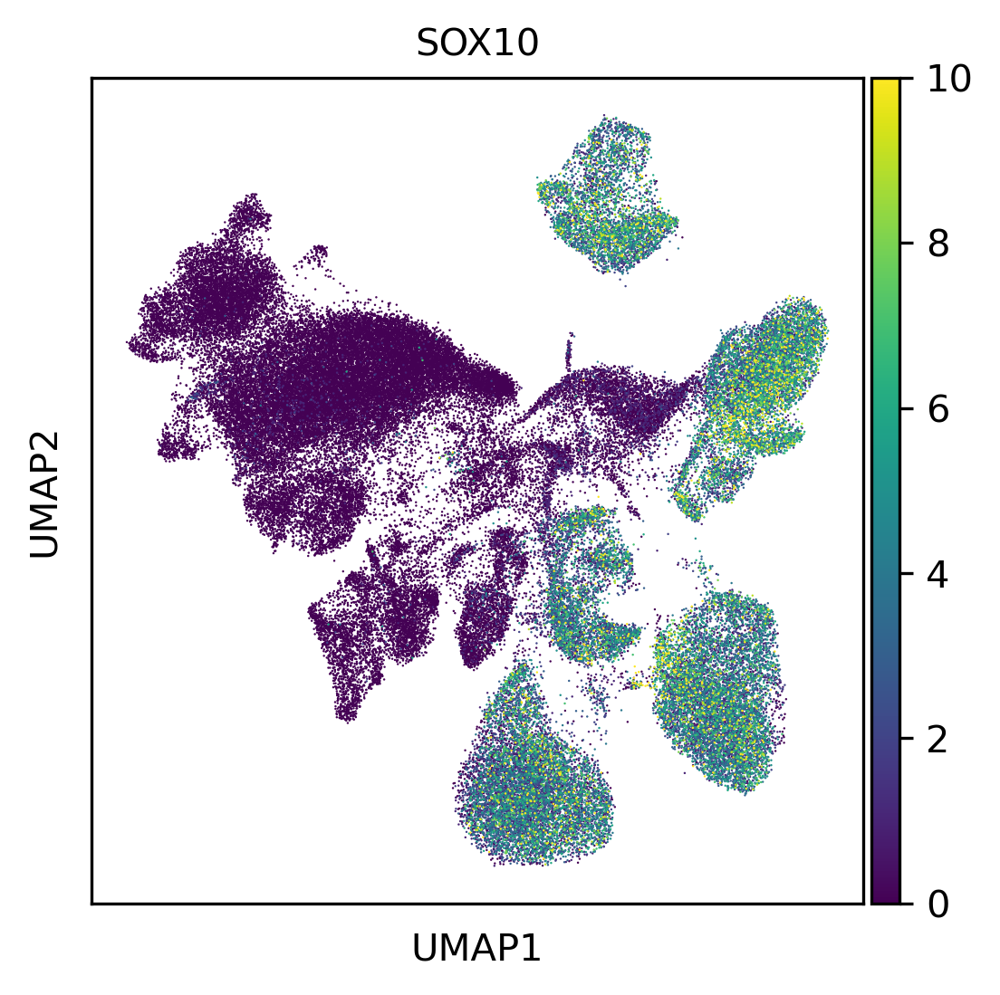

In [236]:
sc.pl.umap(adata_hvg, color=['SOX10'], vmax=10)

## Lineage/Trajectory Analysis 

In [244]:
sc.tl.paga(adata_hvg, groups='sample_ID')

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:01)


--> added 'pos', the PAGA positions (adata.uns['paga'])


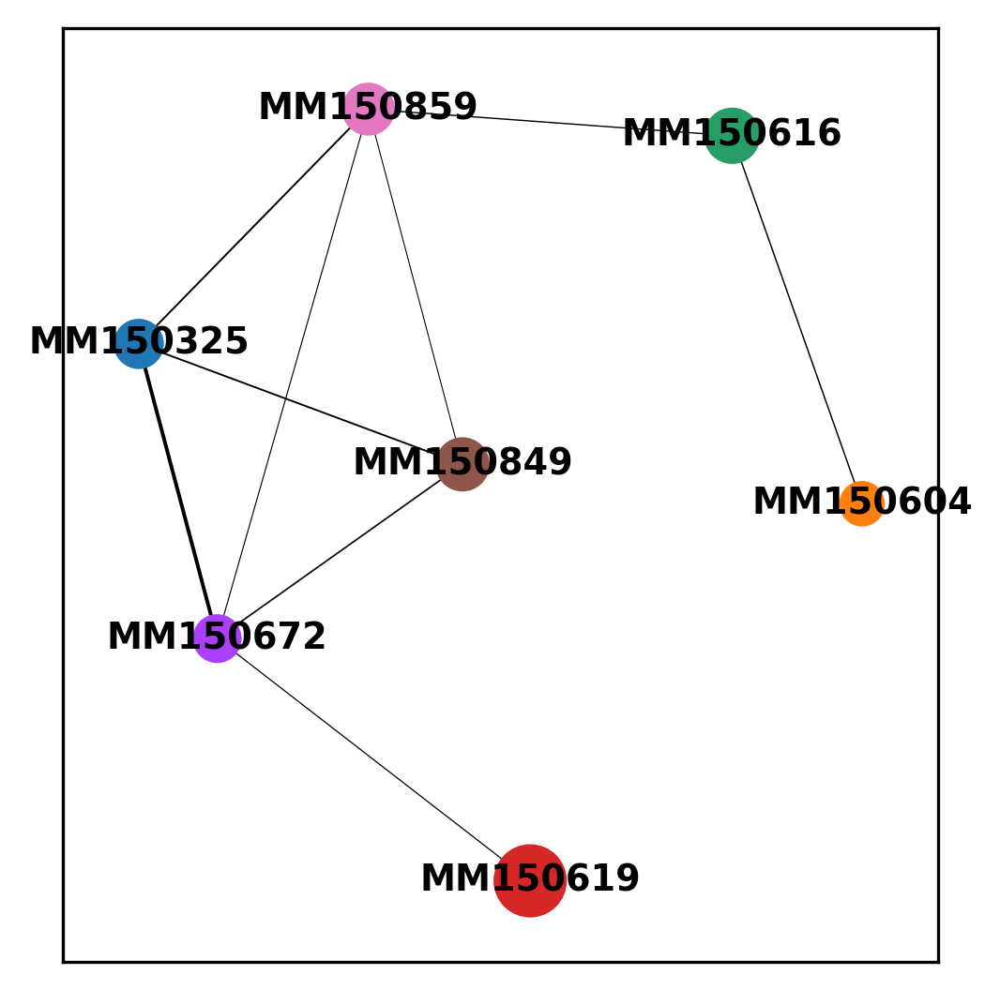

In [245]:
sc.pl.paga(adata_hvg, 
           threshold = 0.03, 
           color=['sample_ID'])

# Fig. 2C (left panel)

--> added 'pos', the PAGA positions (adata.uns['paga'])


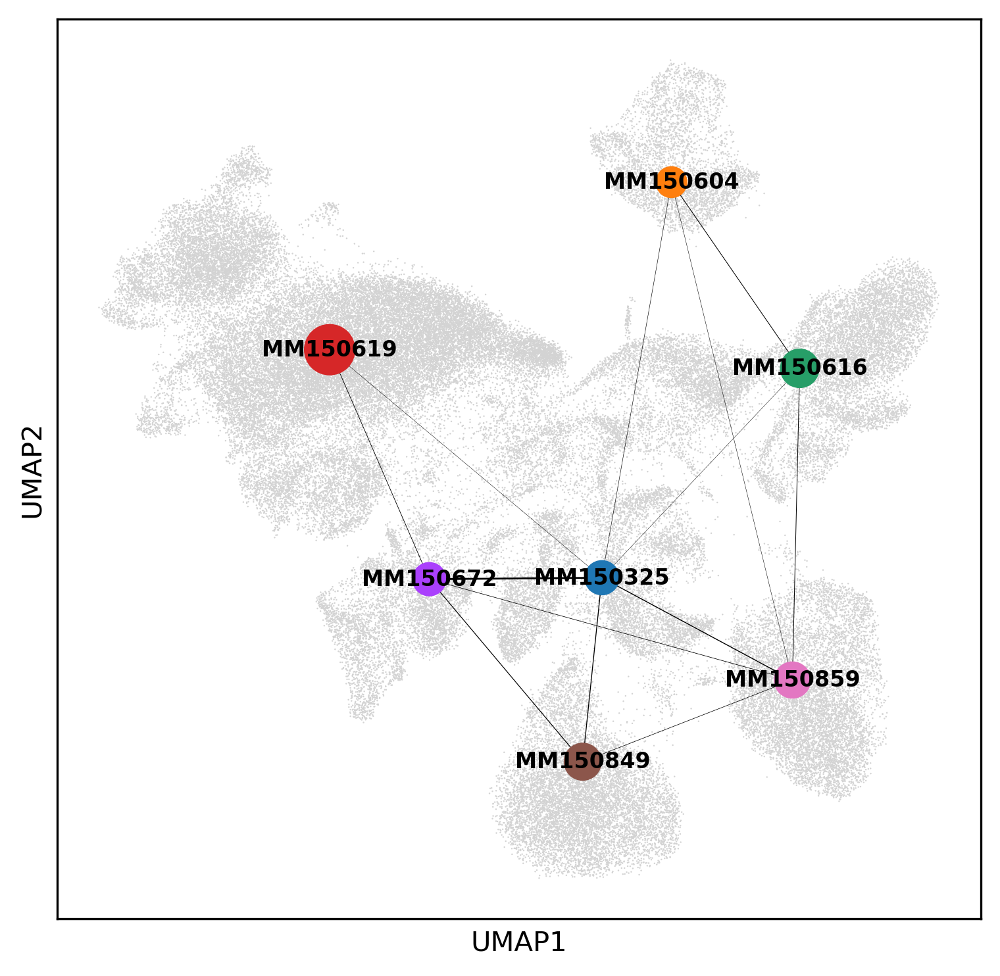

In [246]:
# Define PAGA positions based on the UMAP layout -
# for each cluster we use the mean of the UMAP positions from the cells in that cluster
pos=pd.DataFrame(adata_hvg.obsm['X_umap'],index=adata_hvg.obs_names)
pos['group']=adata_hvg.obs[adata_hvg.uns['paga']['groups']]
pos=pos.groupby('group').mean()

with plt.rc_context({"figure.figsize": (6, 6)}):
    # Plot UMAP in the background
    ax=sc.pl.umap(adata_hvg,show=False)
    # Plot PAGA ontop of the UMAP
    sc.pl.paga(adata_hvg, color='sample_ID',threshold=0.02,
               node_size_scale=1, edge_width_scale=0.7,
               pos=pos.values,
               fontsize = 8,
               random_state=0, ax=ax)

In [247]:
sc.tl.paga(adata_hvg, groups='louvain')

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:02)


--> added 'pos', the PAGA positions (adata.uns['paga'])


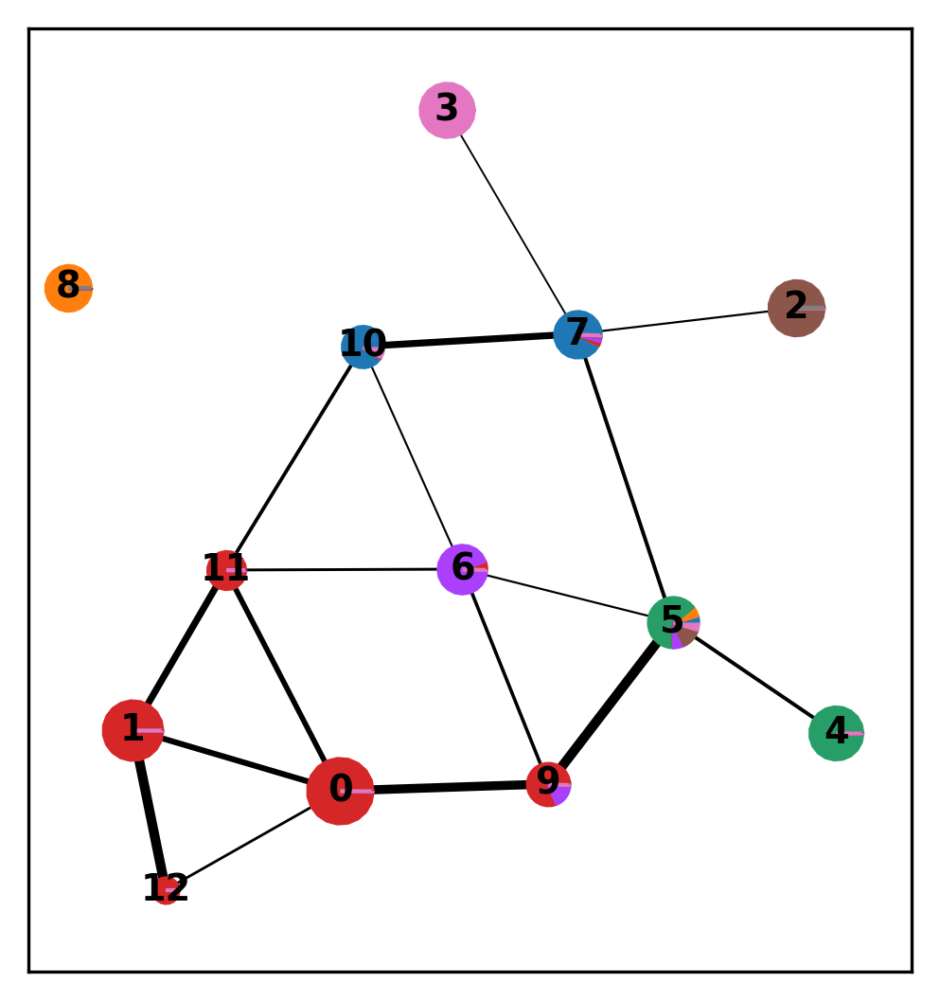

In [248]:
sc.pl.paga(adata_hvg, 
           threshold = 0.05, 
           color=['sample_ID'])

# Fig. 2C (right panel)

--> added 'pos', the PAGA positions (adata.uns['paga'])


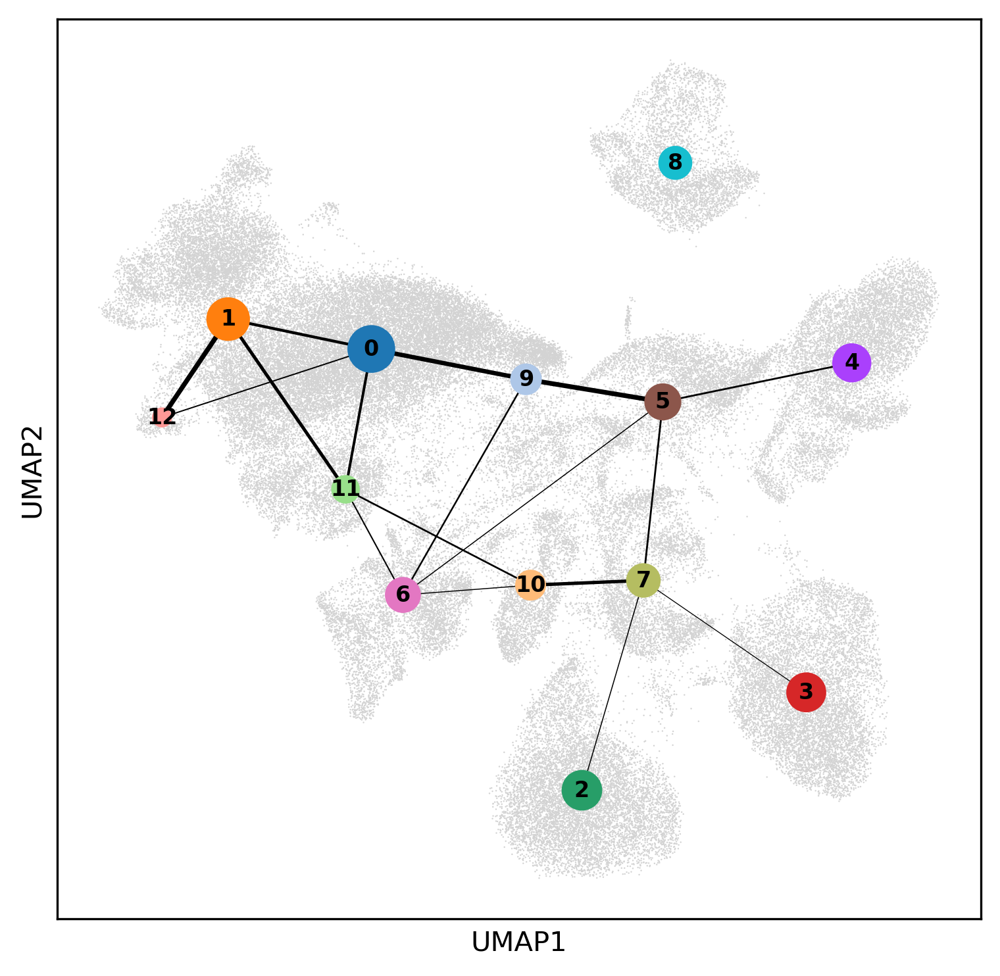

In [249]:
# Define PAGA positions based on the UMAP layout -
# for each cluster we use the mean of the UMAP positions from the cells in that cluster
pos=pd.DataFrame(adata_hvg.obsm['X_umap'],index=adata_hvg.obs_names)
pos['group']=adata_hvg.obs[adata_hvg.uns['paga']['groups']]
pos=pos.groupby('group').mean()

with plt.rc_context({"figure.figsize": (6, 6)}):
    # Plot UMAP in the background
    ax=sc.pl.umap(adata_hvg,show=False)
    # Plot PAGA ontop of the UMAP
    sc.pl.paga(adata_hvg, color='louvain',threshold=0.05,
               node_size_scale=1, edge_width_scale=0.7,
               pos=pos.values,
               fontsize = 8,
               random_state=0, ax=ax)

# Fig. 3G

--> added 'pos', the PAGA positions (adata.uns['paga'])


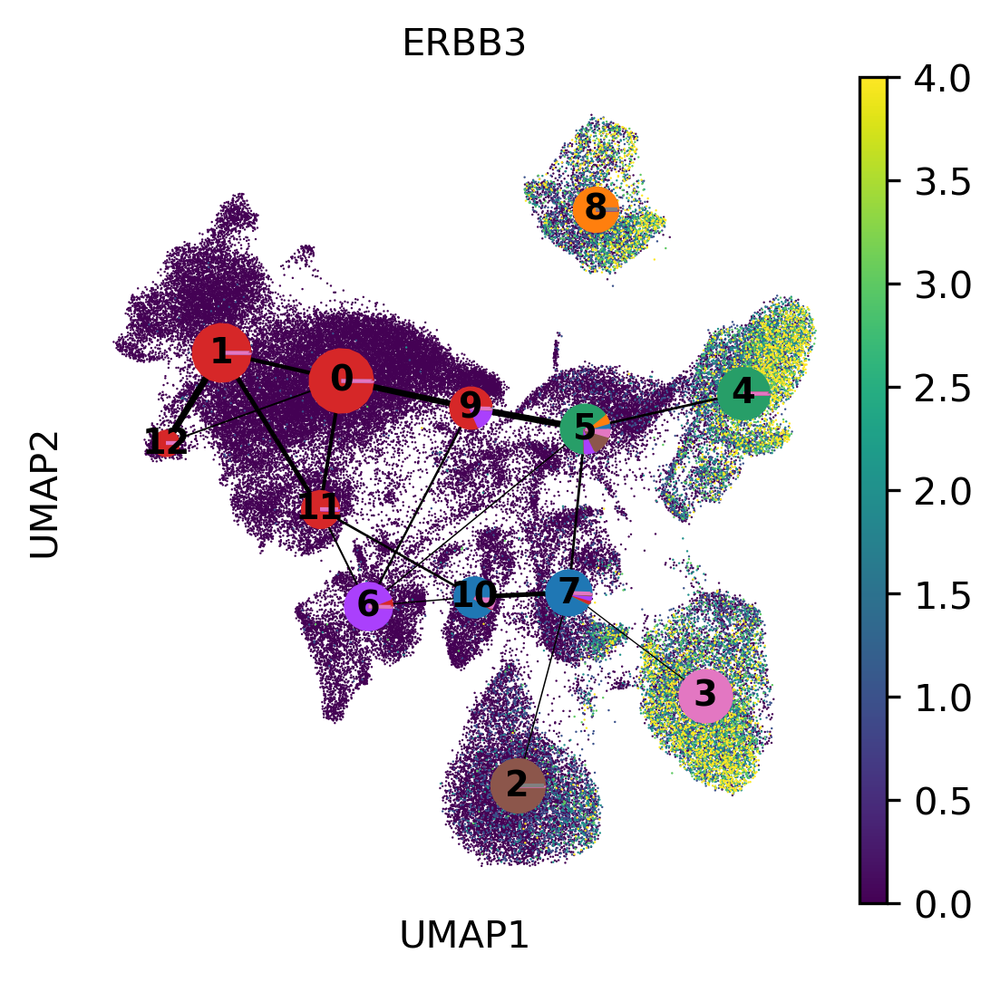

In [250]:
# Define PAGA positions based on the UMAP layout -
# for each cluster we use the mean of the UMAP positions from the cells in that cluster
pos=pd.DataFrame(adata_hvg.obsm['X_umap'],index=adata_hvg.obs_names)
pos['group']=adata_hvg.obs[adata_hvg.uns['paga']['groups']]
pos=pos.groupby('group').mean()


# Plot UMAP in the background
ax=sc.pl.umap(adata_hvg, color='ERBB3', vmin=0, vmax=4, show=False)
# Plot PAGA ontop of the UMAP
sc.pl.paga(adata_hvg, color='sample_ID',threshold=0.05,
           node_size_scale=1, edge_width_scale=0.7,
           pos=pos.values,
           random_state=0, ax=ax, frameon = False)

# Fig. 3H

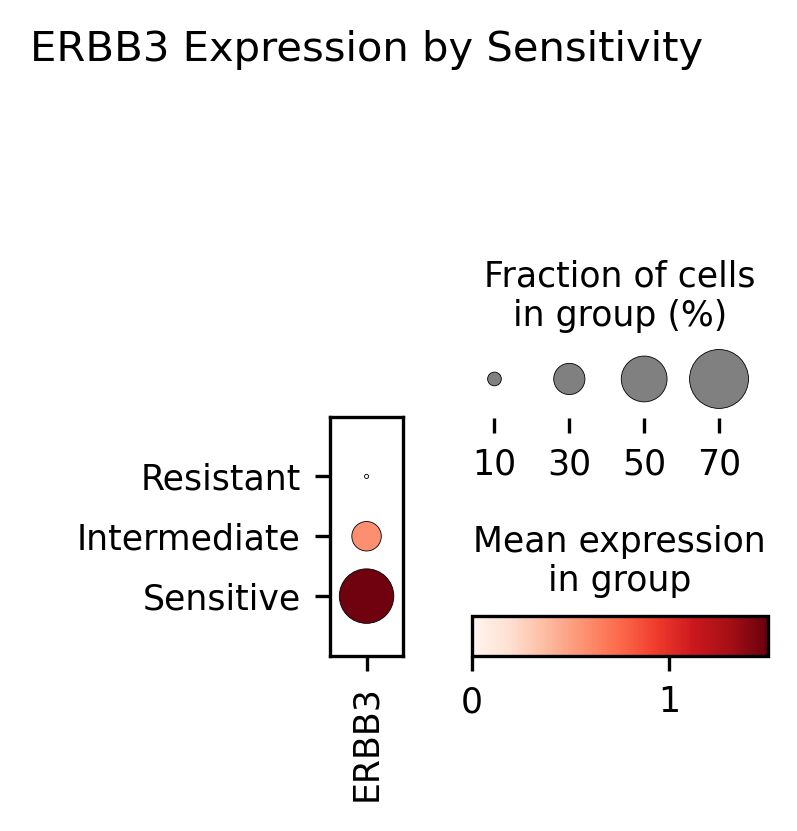

In [251]:
# Sensitivity
sc.pl.dotplot(adata_hvg, 
              var_names = "ERBB3",
              #gene_symbols = "gene_ids",
              groupby = 'Sensitivity',
              categories_order = ['Resistant', "Intermediate", "Sensitive"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'ERBB3 Expression by Sensitivity')

# Fig. 4A (left panel)

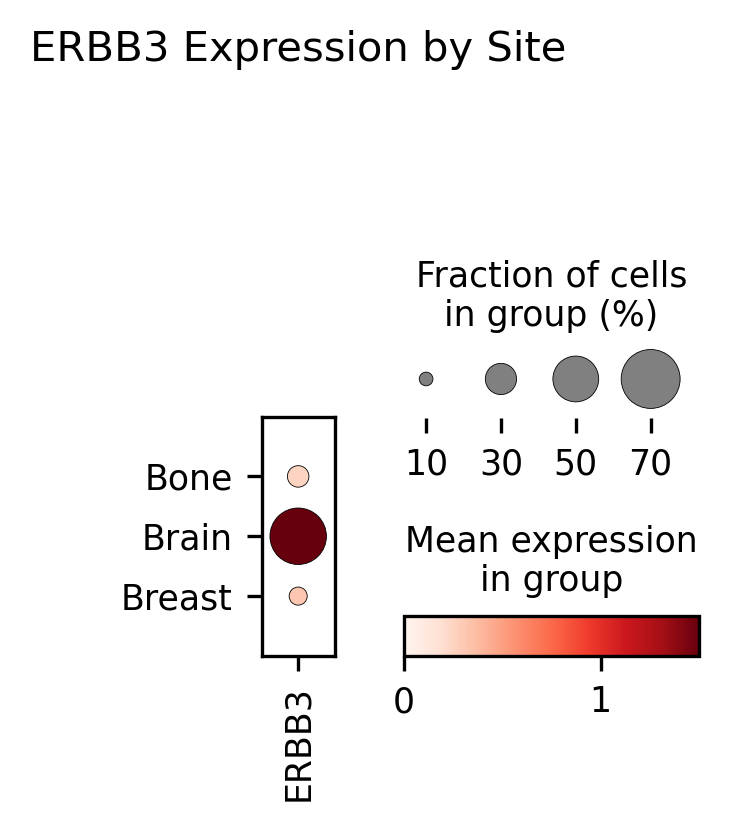

In [252]:
# Site
sc.pl.dotplot(adata_hvg, 
              var_names = "ERBB3",
              #gene_symbols = "gene_ids",
              groupby = 'Site',
              categories_order = ['Bone', "Brain", "Breast"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'ERBB3 Expression by Site')

# Fig. 4A (right panel)

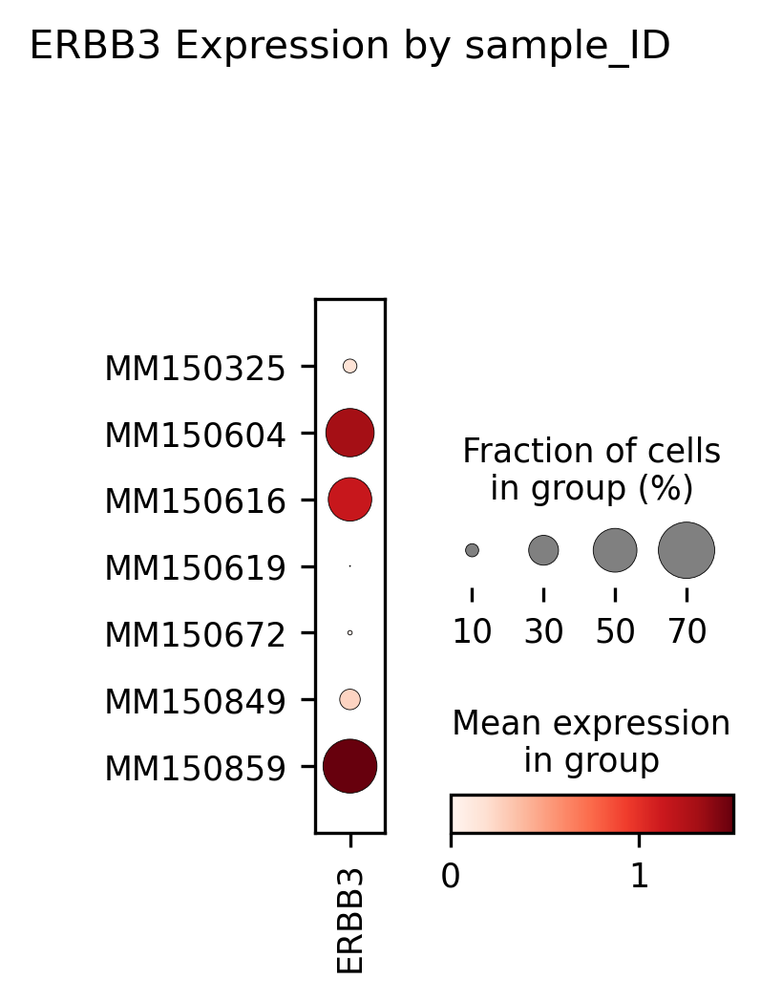

In [253]:
# Site
sc.pl.dotplot(adata_hvg, 
              var_names = "ERBB3",
              #gene_symbols = "gene_ids",
              groupby = 'sample_ID',
              categories_order = ['MM150325', "MM150604", "MM150616", "MM150619", "MM150672", "MM150849", "MM150859"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'ERBB3 Expression by sample_ID')

# Fig. EV4A

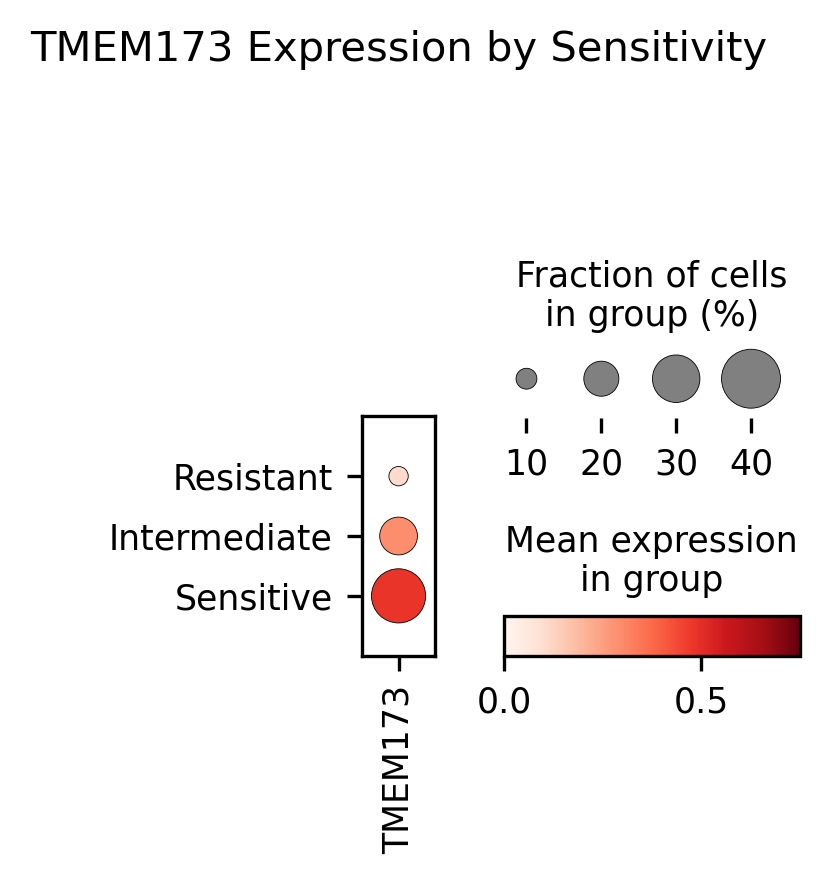

In [254]:
# Sensitivity
sc.pl.dotplot(adata_hvg, 
              var_names = "TMEM173",
              #gene_symbols = "gene_ids",
              groupby = 'Sensitivity',
              categories_order = ['Resistant', "Intermediate", "Sensitive"],
              #log = True,
              vmin = 0,
              vmax = 0.75,
              dendrogram = False,
              title = f'TMEM173 Expression by Sensitivity')

# Fig. EV4B

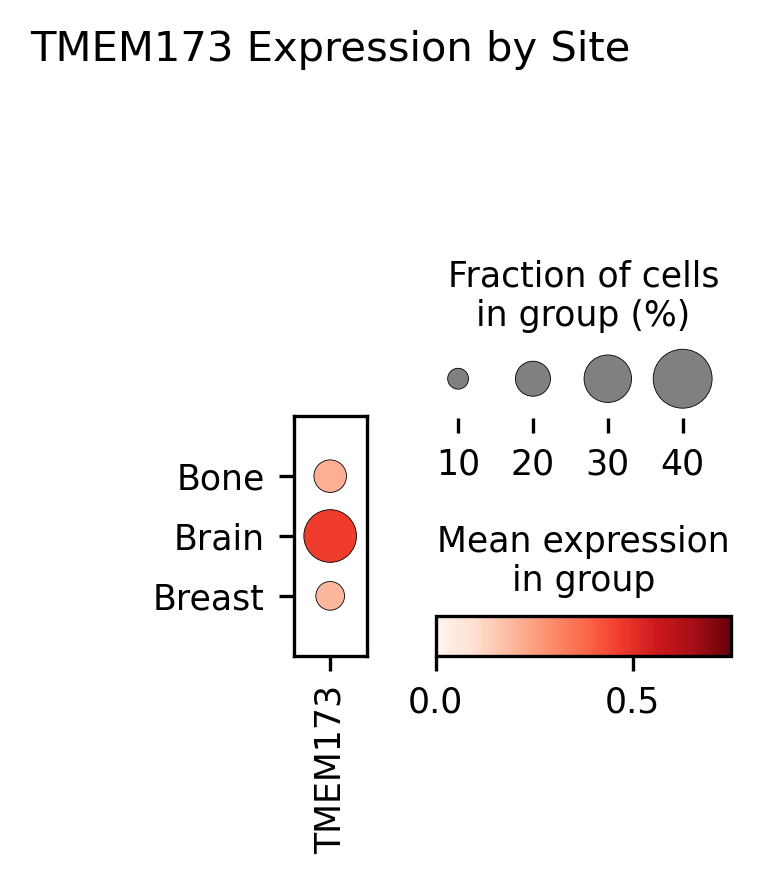

In [255]:
# Site
sc.pl.dotplot(adata_hvg, 
              var_names = "TMEM173",
              #gene_symbols = "gene_ids",
              groupby = 'Site',
              categories_order = ['Bone', "Brain", "Breast"],
              #log = True,
              vmin = 0,
              vmax = 0.75,
              dendrogram = False,
              title = f'TMEM173 Expression by Site')

# Fig. EV5A

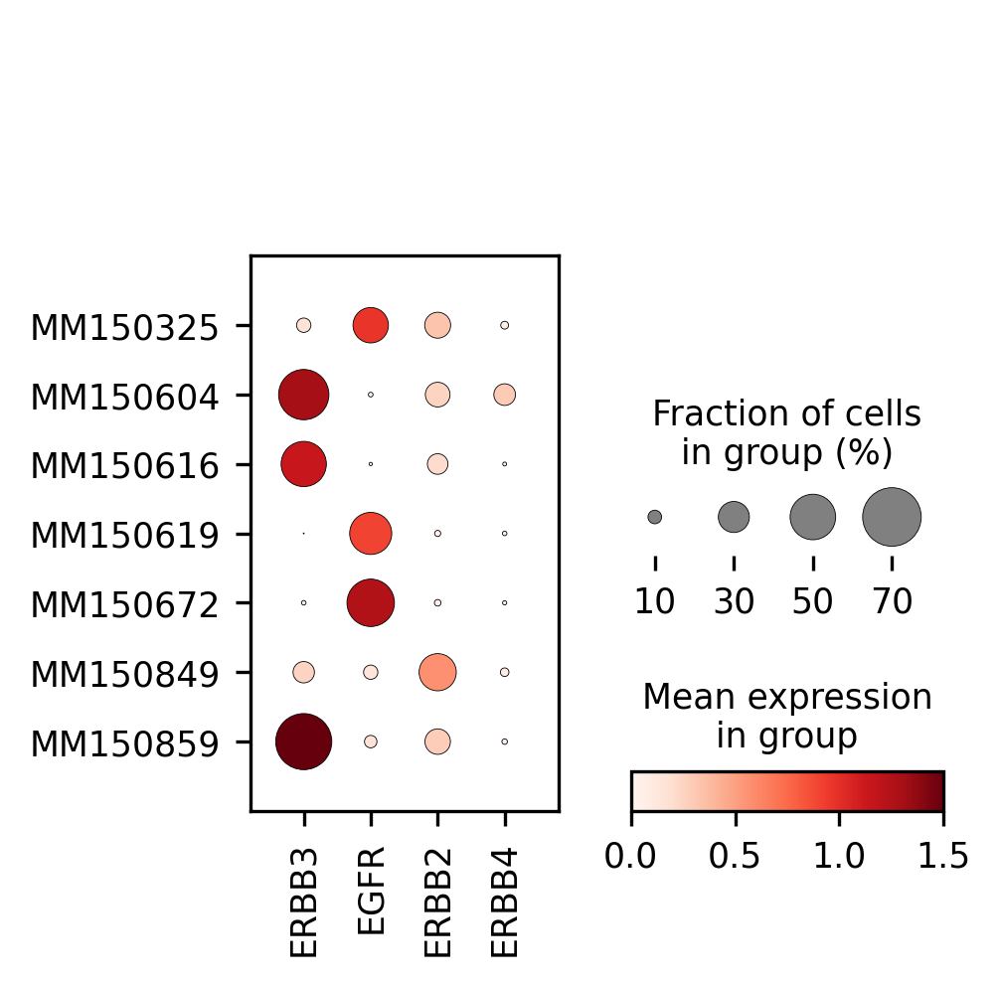

In [256]:
# sample_ID
sc.pl.dotplot(adata_hvg, 
              var_names = ["ERBB3", "EGFR", "ERBB2", "ERBB4"],
              #gene_symbols = "gene_ids",
              groupby = 'sample_ID',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False)

# Fig. EV5Ea

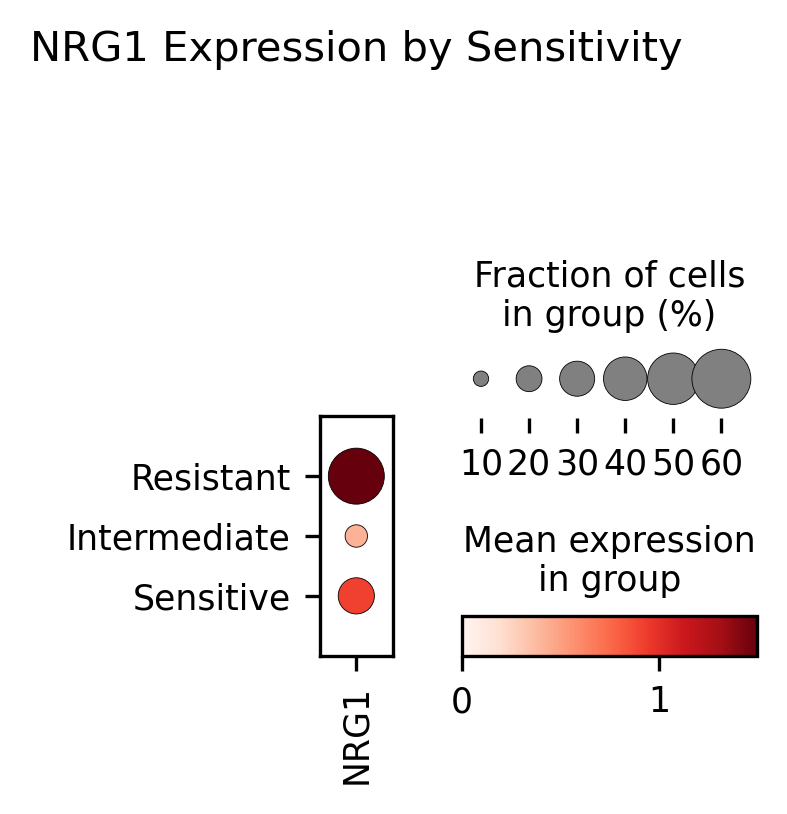

In [257]:
# Sensitivity
sc.pl.dotplot(adata_hvg, 
              var_names = "NRG1",
              #gene_symbols = "gene_ids",
              groupby = 'Sensitivity',
              categories_order = ['Resistant', "Intermediate", "Sensitive"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'NRG1 Expression by Sensitivity')

# Fig. EV5Eb

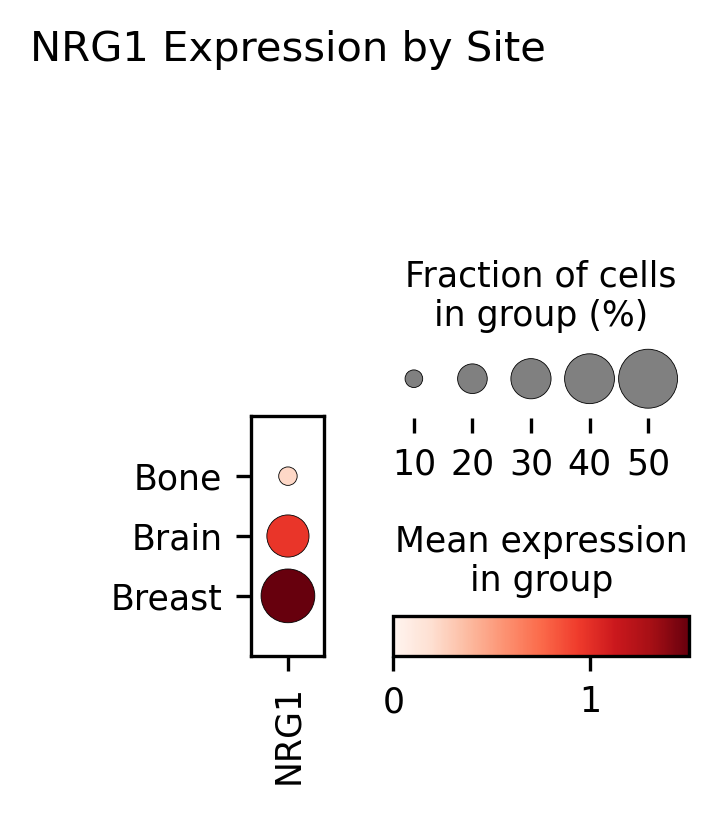

In [258]:
# Site
sc.pl.dotplot(adata_hvg, 
              var_names = "NRG1",
              #gene_symbols = "gene_ids",
              groupby = 'Site',
              categories_order = ['Bone', "Brain", "Breast"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'NRG1 Expression by Site')

# Fig. EV5Ec

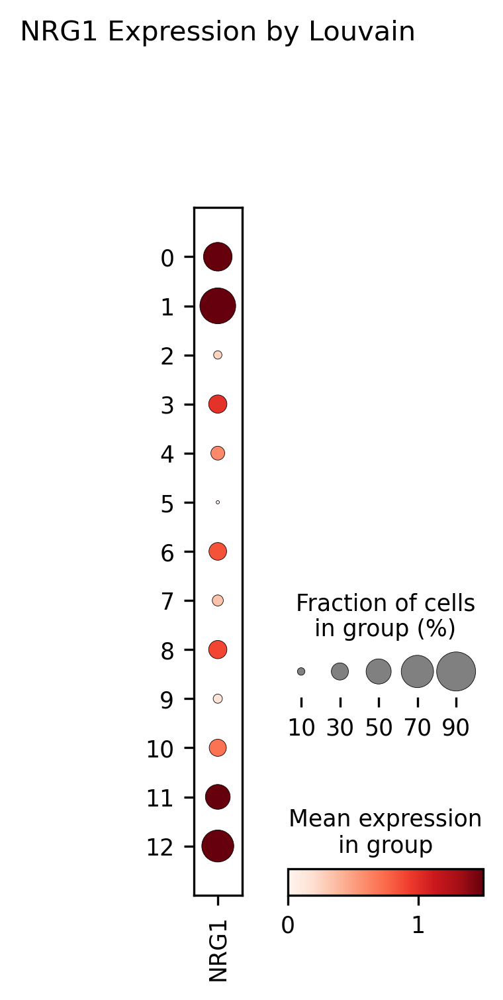

In [259]:
# Louvain
sc.pl.dotplot(adata_hvg, 
              var_names = "NRG1",
              #gene_symbols = "gene_ids",
              groupby = 'louvain',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'NRG1 Expression by Louvain')

# Fig. EV5Ed

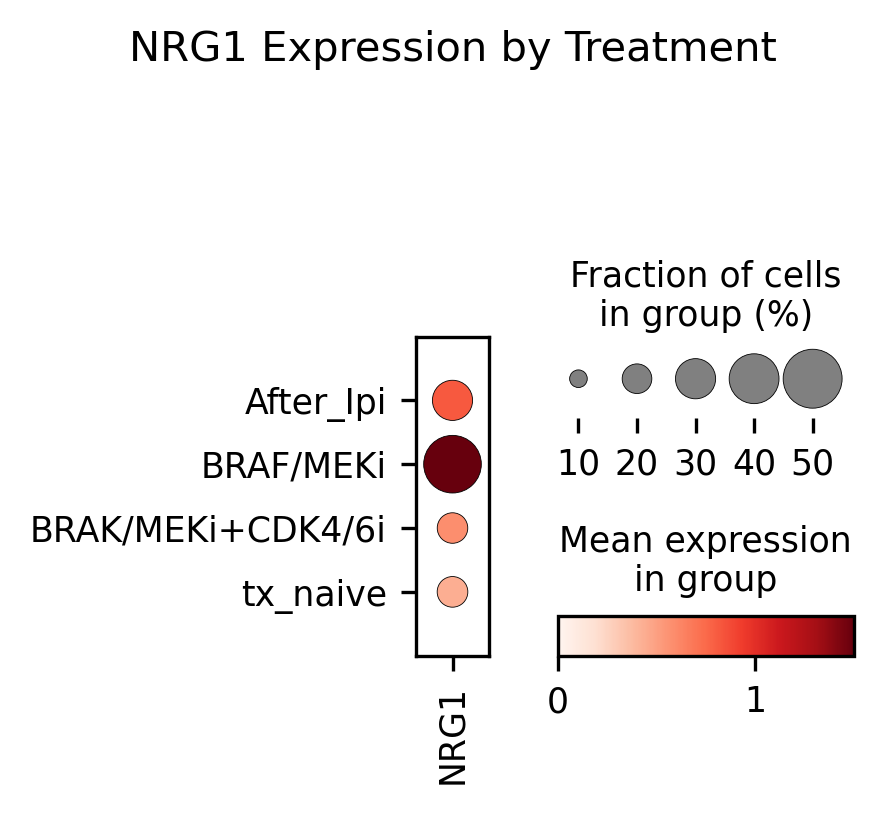

In [260]:
# Treatment
sc.pl.dotplot(adata_hvg, 
              var_names = "NRG1",
              #gene_symbols = "gene_ids",
              groupby = 'Treatment',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'NRG1 Expression by Treatment')

# Fig. EV5Ee

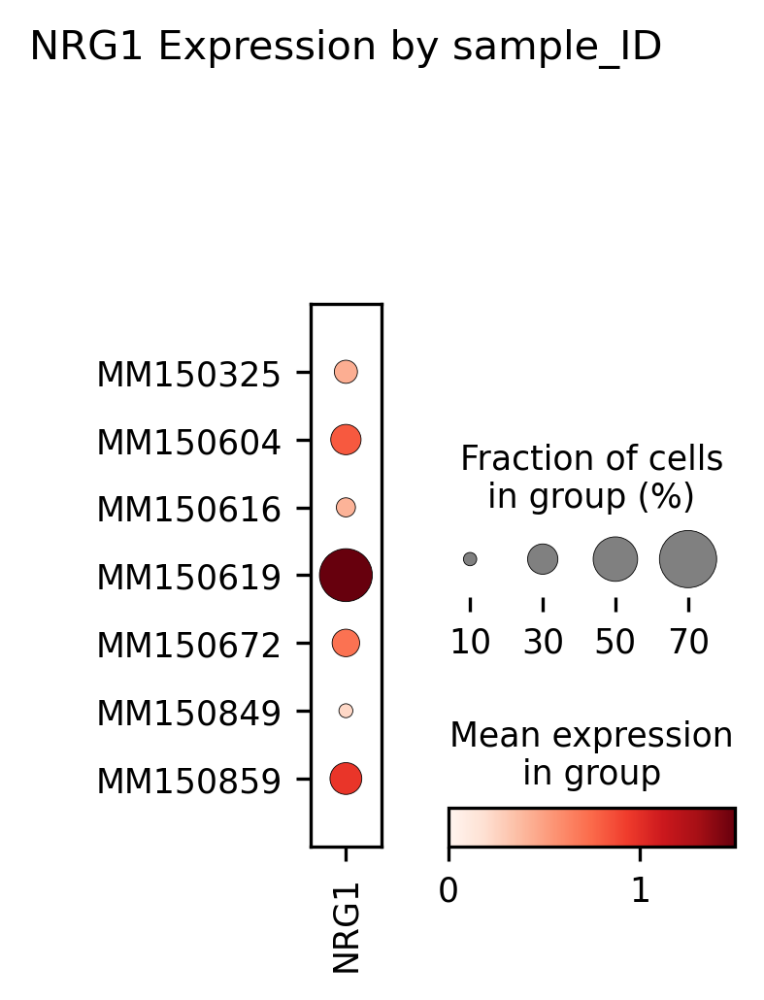

In [261]:
# Treatment
sc.pl.dotplot(adata_hvg, 
              var_names = "NRG1",
              #gene_symbols = "gene_ids",
              groupby = 'sample_ID',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'NRG1 Expression by sample_ID')

## Gene Set Scoring (ADD AUTHOR NAMES AS PREFIX TO SIGS)

### Tsoi

In [262]:
tsoi_signatures = GeneSignature.from_gmt('gmts/Tsoi_MelanomeCellStateSignatures_ENSG.gmt', field_separator='\t', gene_separator='\t')
len(tsoi_signatures)

7

In [263]:
gene_ids_dict = adata.var.gene_ids.to_dict()
ensg_ids_dict = {v: k for k, v in gene_ids_dict.items()}

In [264]:
tsoi_names = []
for signature_num in range(len(tsoi_signatures)):
    temp_name = f"Tsoi_{tsoi_signatures[signature_num].name}"
    tsoi_names.append(temp_name)
    
    temp_sig = list(tsoi_signatures[signature_num].gene2weight)
    ensg_ids_dict_subset = dict((k, ensg_ids_dict[k]) for k in temp_sig if k in ensg_ids_dict)
    ensg_ids_dict_subset_list = list(ensg_ids_dict_subset.values())
    
    sc.tl.score_genes(adata, ensg_ids_dict_subset_list, ctrl_size=50, gene_pool=None, 
                      n_bins=25, score_name=temp_name, random_state=0, copy=False, use_raw=None)
    
    #adata.var[tsoi_signatures[signature_num].name] = adata.obs[tsoi_signatures[signature_num].name]

computing score 'Tsoi_Undifferentiated'
    finished: added
    'Tsoi_Undifferentiated', score of gene set (adata.obs).
    945 total control genes are used. (0:00:05)
computing score 'Tsoi_Undifferentiated.Neural.crest.like'
    finished: added
    'Tsoi_Undifferentiated.Neural.crest.like', score of gene set (adata.obs).
    652 total control genes are used. (0:00:05)
computing score 'Tsoi_Neural.crest.like'
    finished: added
    'Tsoi_Neural.crest.like', score of gene set (adata.obs).
    604 total control genes are used. (0:00:05)
computing score 'Tsoi_Neural.crest.like.Transitory'
    finished: added
    'Tsoi_Neural.crest.like.Transitory', score of gene set (adata.obs).
    549 total control genes are used. (0:00:05)
computing score 'Tsoi_Transitory'
    finished: added
    'Tsoi_Transitory', score of gene set (adata.obs).
    799 total control genes are used. (0:00:05)
computing score 'Tsoi_Transitory.Melanocytic'
    finished: added
    'Tsoi_Transitory.Melanocytic', score of 

In [265]:
# add tsoi scores to adata_hvg
for tsoi in tsoi_names:
    adata_hvg.obs[tsoi] = adata.obs[tsoi]

In [266]:
adata_hvg

AnnData object with n_obs × n_vars = 88689 × 2718
    obs: 'sample_ID', 'scATOMIC_pred', 'n_genes', 'percent_mito', 'n_counts', 'Treatment', 'Site', 'Sensitivity', 'louvain', 'Tsoi_Undifferentiated', 'Tsoi_Undifferentiated.Neural.crest.like', 'Tsoi_Neural.crest.like', 'Tsoi_Neural.crest.like.Transitory', 'Tsoi_Transitory', 'Tsoi_Transitory.Melanocytic', 'Tsoi_Melanocytic'
    var: 'gene_ids', 'feature_types', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'sample_ID_colors', 'neighbors', 'umap', 'tsne', 'louvain', 'louvain_colors', 'paga', 'sample_ID_sizes', 'louvain_sizes'
    obsm: 'X_pca', 'X_umap', 'X_tsne'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

# Fig. 2F

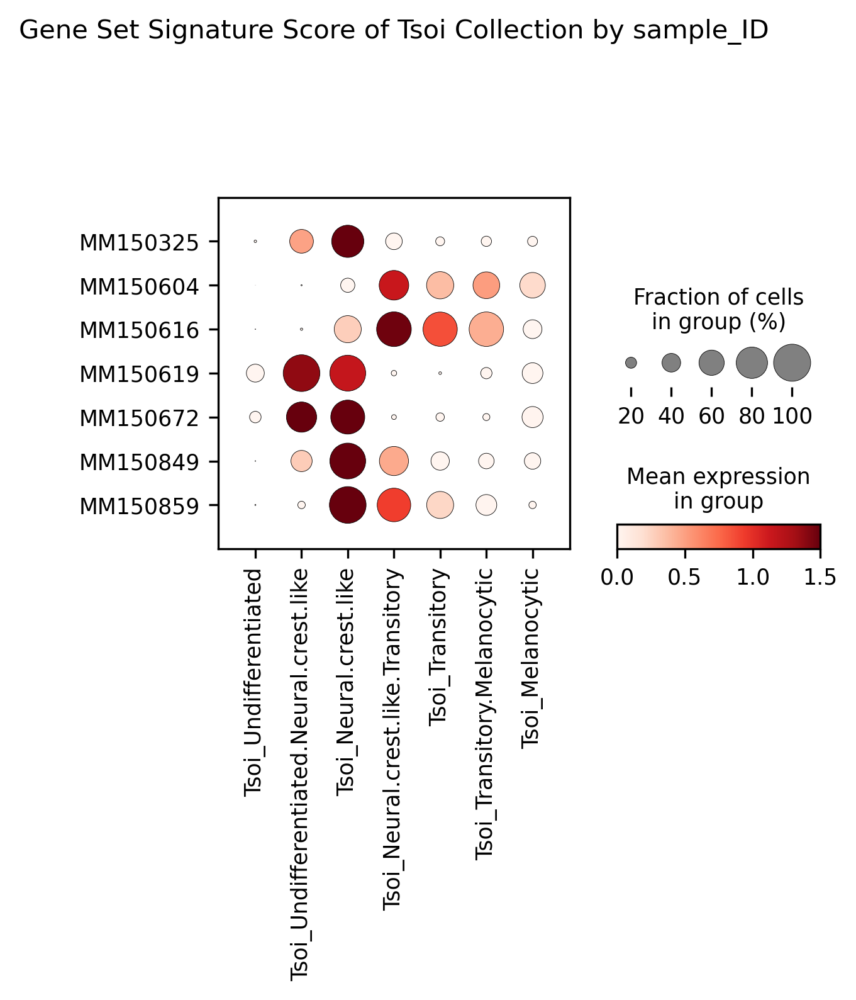

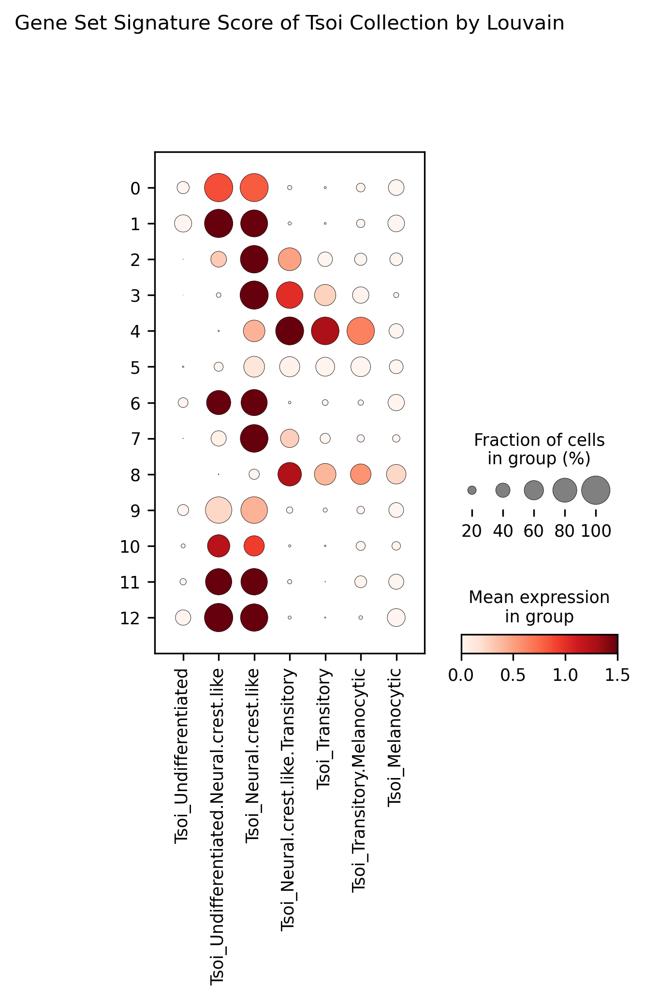

In [267]:
# Sample IDs
sc.pl.dotplot(adata_hvg, 
              var_names = tsoi_names,
              #gene_symbols = "gene_ids",
              groupby = 'sample_ID',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'Gene Set Signature Score of Tsoi Collection by sample_ID')

# Louvain
sc.pl.dotplot(adata_hvg, 
              var_names = tsoi_names,
              #gene_symbols = "gene_ids",
              groupby = 'louvain',
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'Gene Set Signature Score of Tsoi Collection by Louvain')

# Fig. 3B

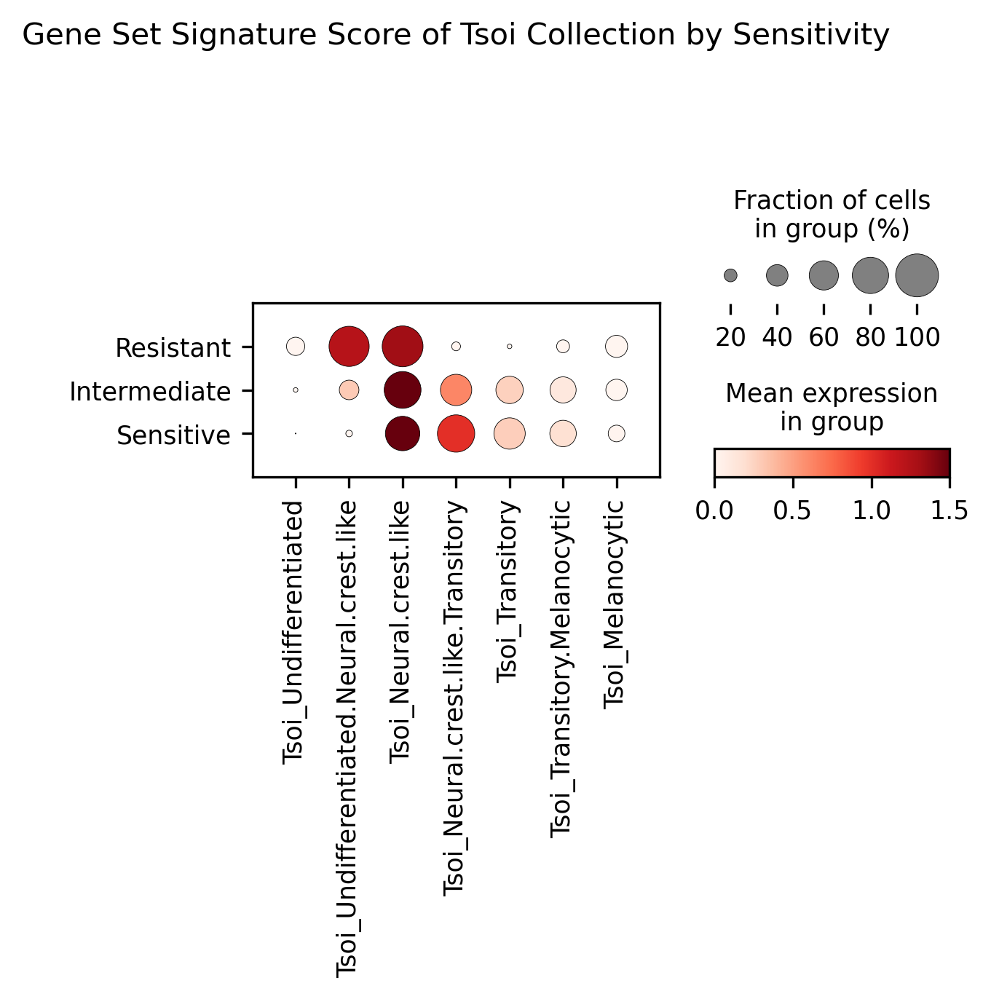

In [268]:
# Sensitivity
sc.pl.dotplot(adata_hvg, 
              var_names = tsoi_names,
              #gene_symbols = "gene_ids",
              groupby = 'Sensitivity',
              categories_order = ['Resistant', "Intermediate", "Sensitive"],
              #log = True,
              vmin = 0,
              vmax = 1.5,
              dendrogram = False,
              title = f'Gene Set Signature Score of Tsoi Collection by Sensitivity')

# Fig. EV3

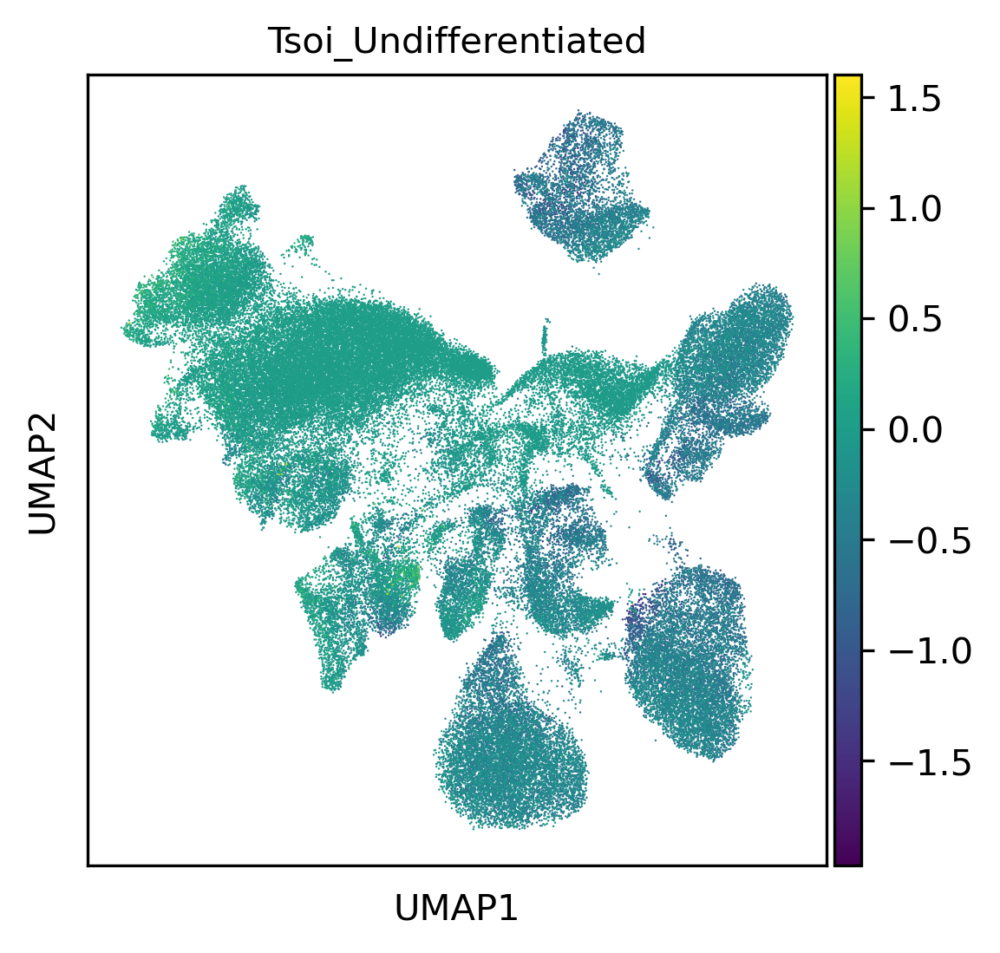

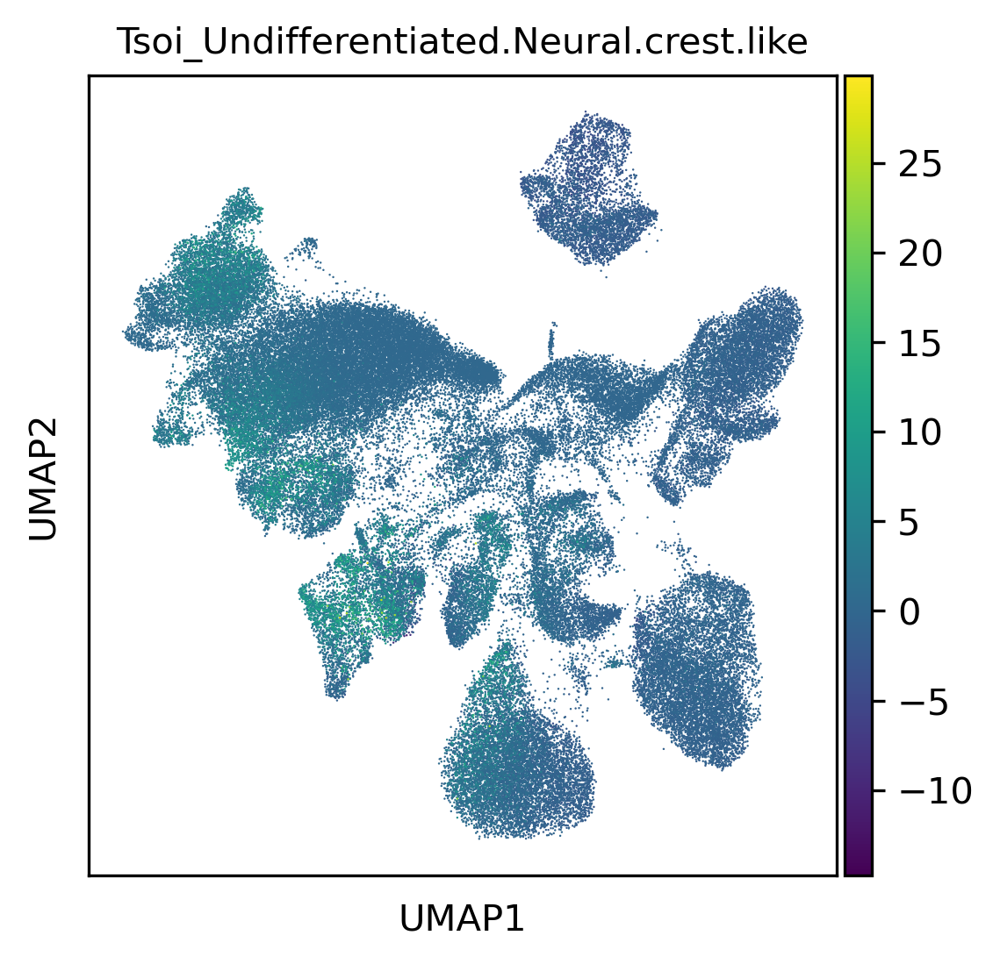

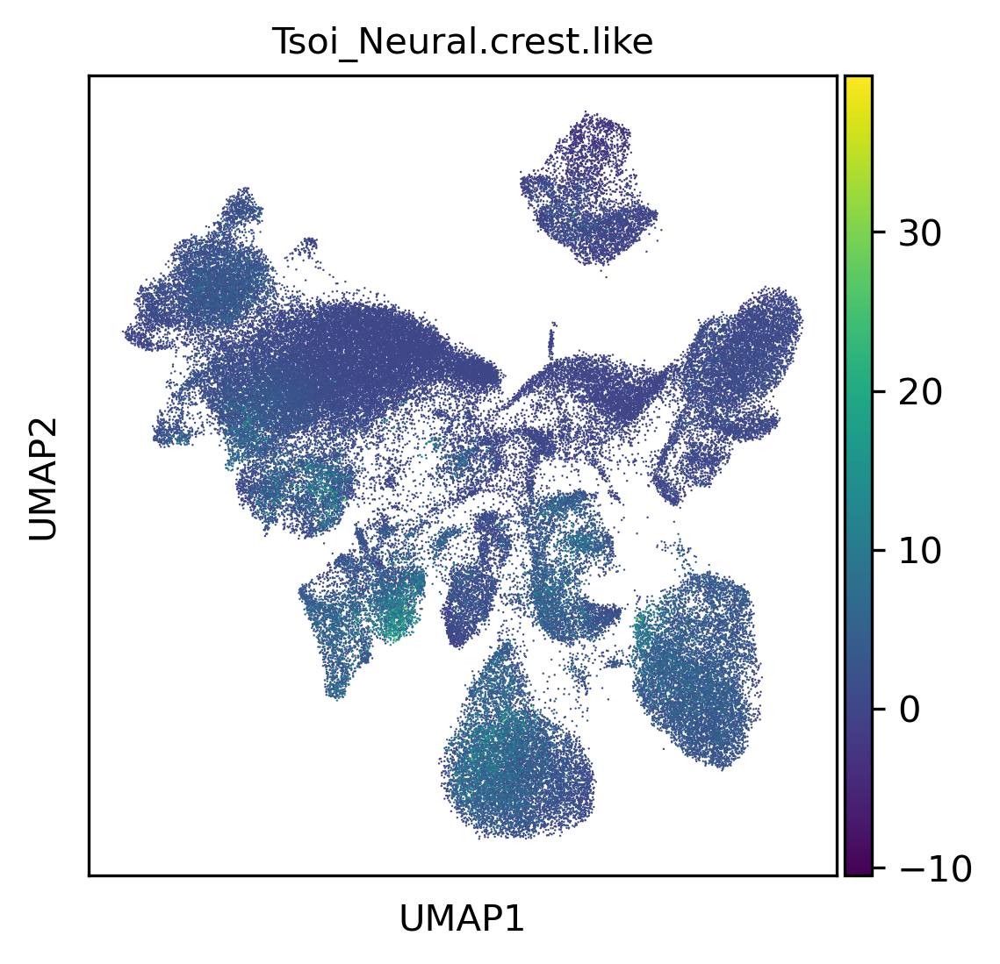

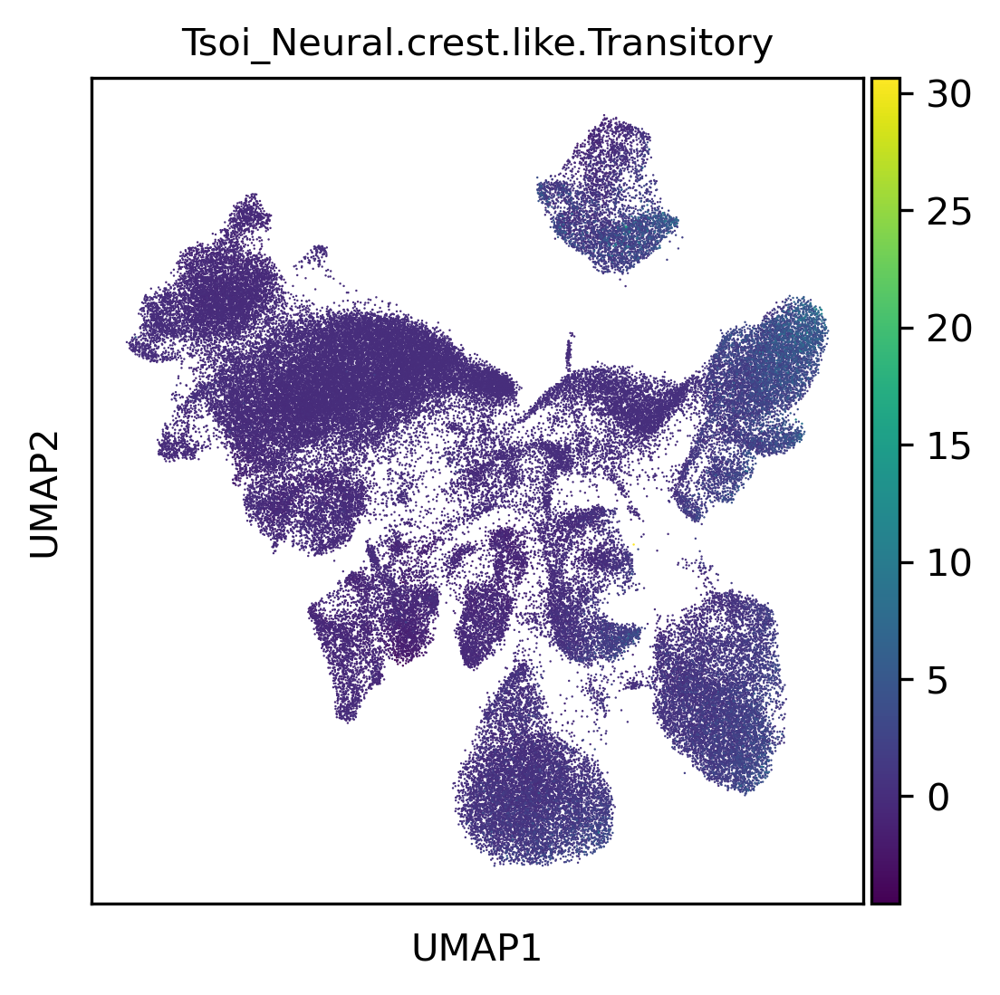

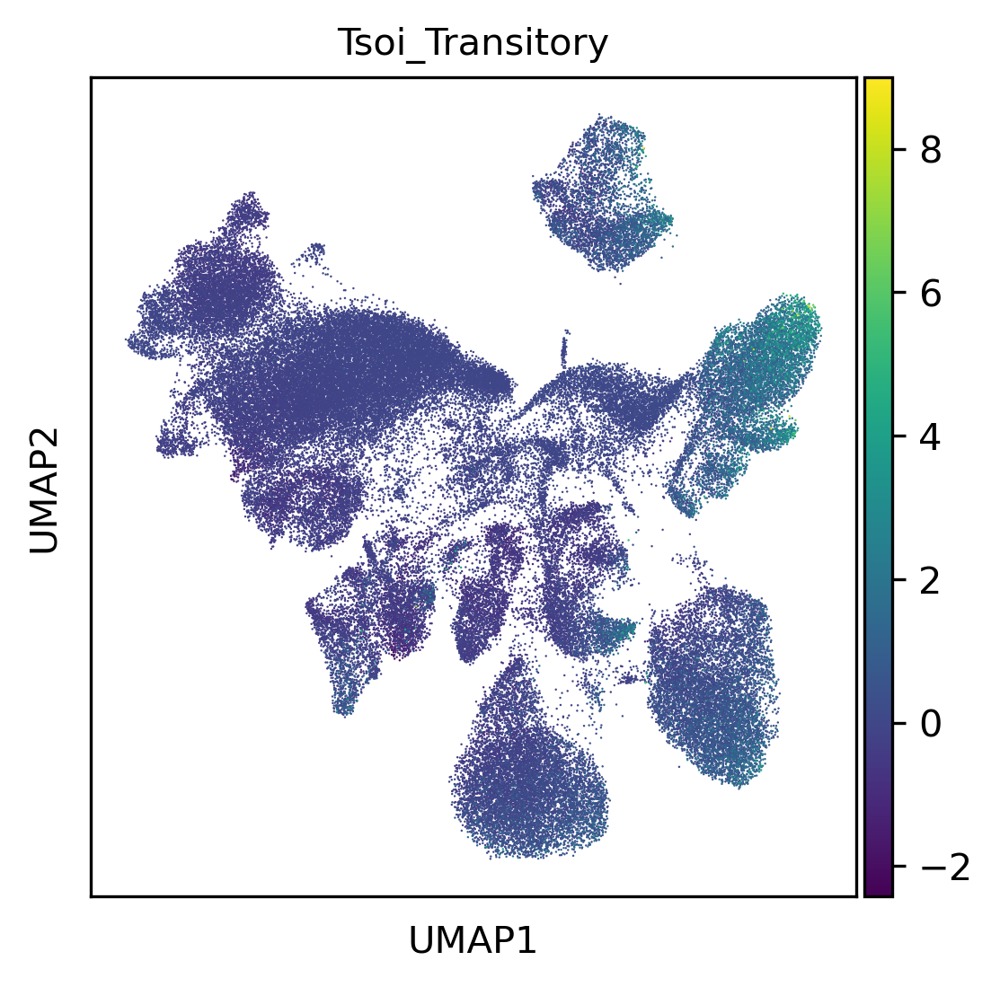

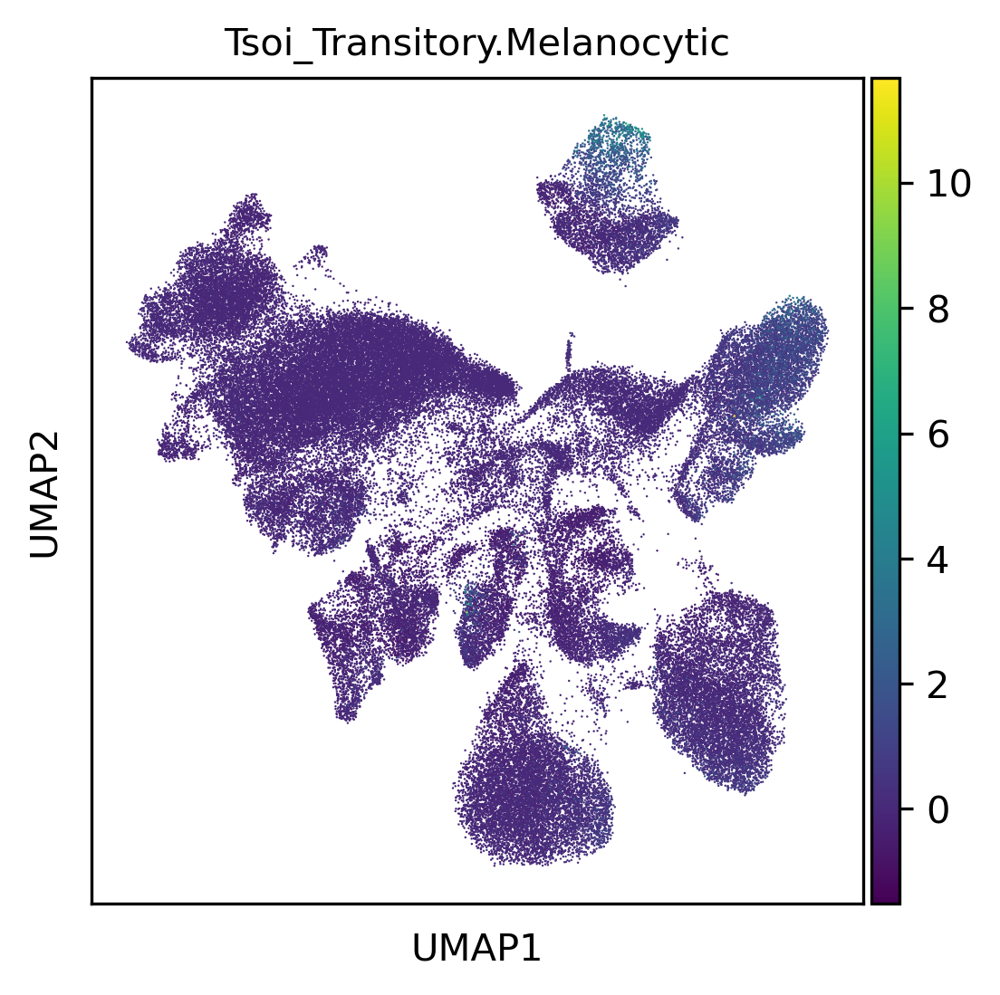

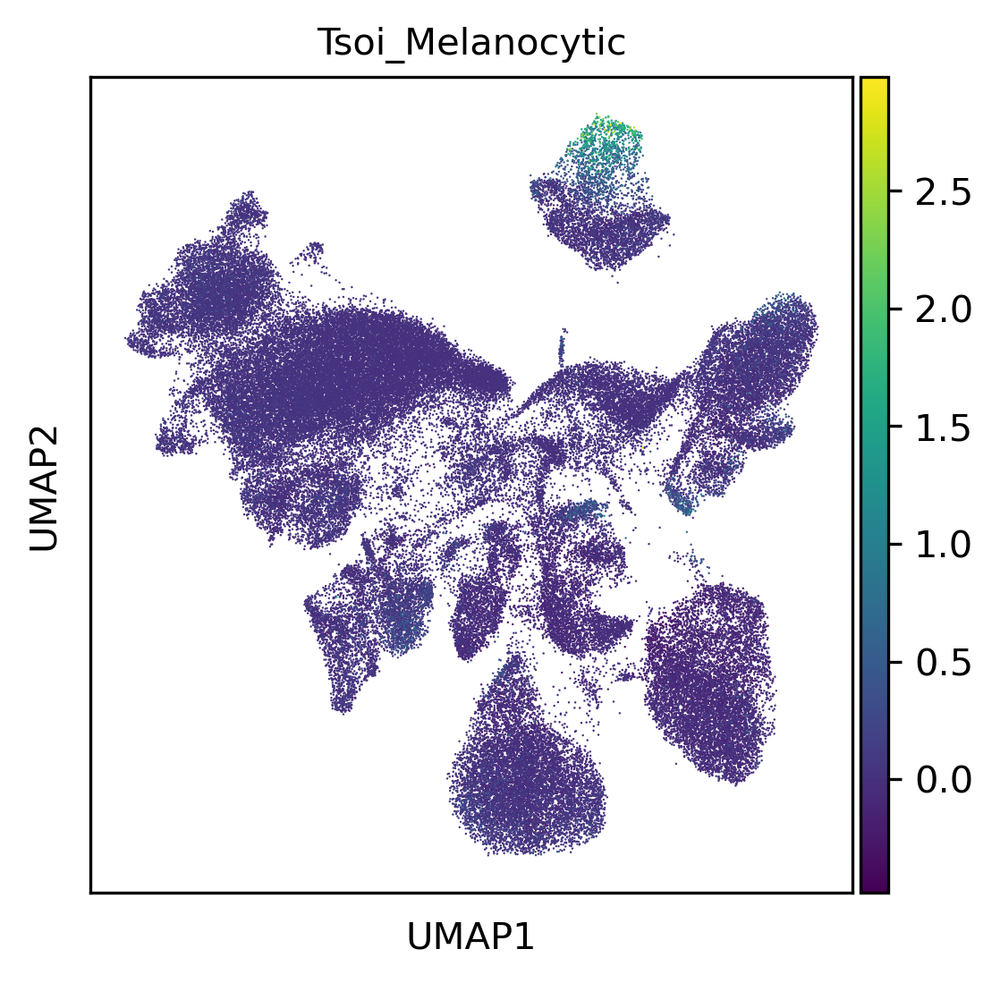

In [269]:
for tsoi in tsoi_names:
    sc.pl.umap(adata_hvg, color=[tsoi])

### Wouters

In [270]:
wouters_signatures = GeneSignature.from_gmt('gmts/Wouters_melanoma.gmt', field_separator='\t', gene_separator='\t')
len(wouters_signatures)

3

In [271]:
wouters_names = []
for signature_num in range(len(wouters_signatures)):
    temp_name = f"Wouters_{wouters_signatures[signature_num].name}"
    wouters_names.append(temp_name)
    
    temp_sig = list(wouters_signatures[signature_num].gene2weight)
    
    sc.tl.score_genes(adata, temp_sig, ctrl_size=50, gene_pool=None, 
                      n_bins=25, score_name=temp_name, random_state=0, copy=False, use_raw=None)
    
    #adata.var[wouters_signatures[signature_num].name] = adata.obs[wouters_signatures[signature_num].name]

computing score 'Wouters_Intermediate cell state'
    finished: added
    'Wouters_Intermediate cell state', score of gene set (adata.obs).
    1045 total control genes are used. (0:00:05)
computing score 'Wouters_Mesenchymal-like cell state'
    finished: added
    'Wouters_Mesenchymal-like cell state', score of gene set (adata.obs).
    1137 total control genes are used. (0:00:06)
computing score 'Wouters_Melanocytic cell state'


    finished: added
    'Wouters_Melanocytic cell state', score of gene set (adata.obs).
    1154 total control genes are used. (0:00:05)


In [272]:
# add wouters scores to adata_hvg
for wouter in wouters_names:
    adata_hvg.obs[wouter] = adata.obs[wouter]

# Fig. EV3

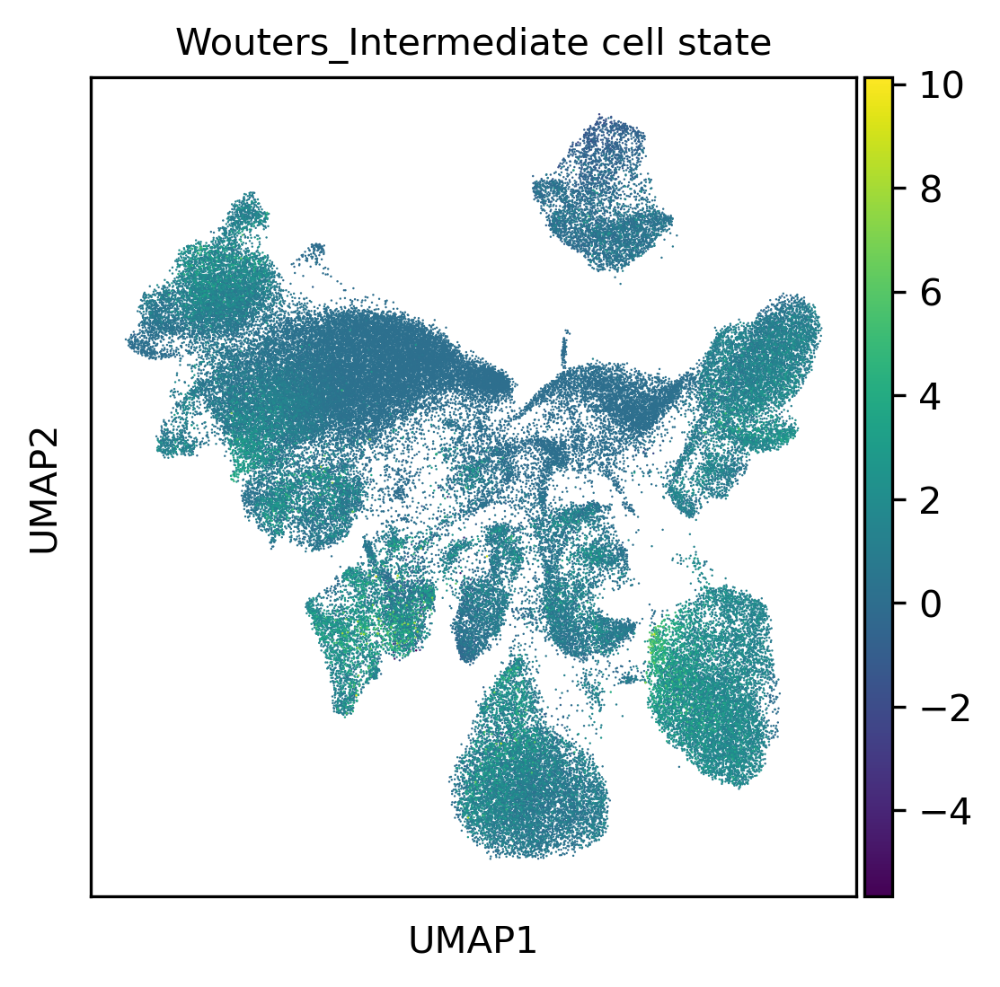

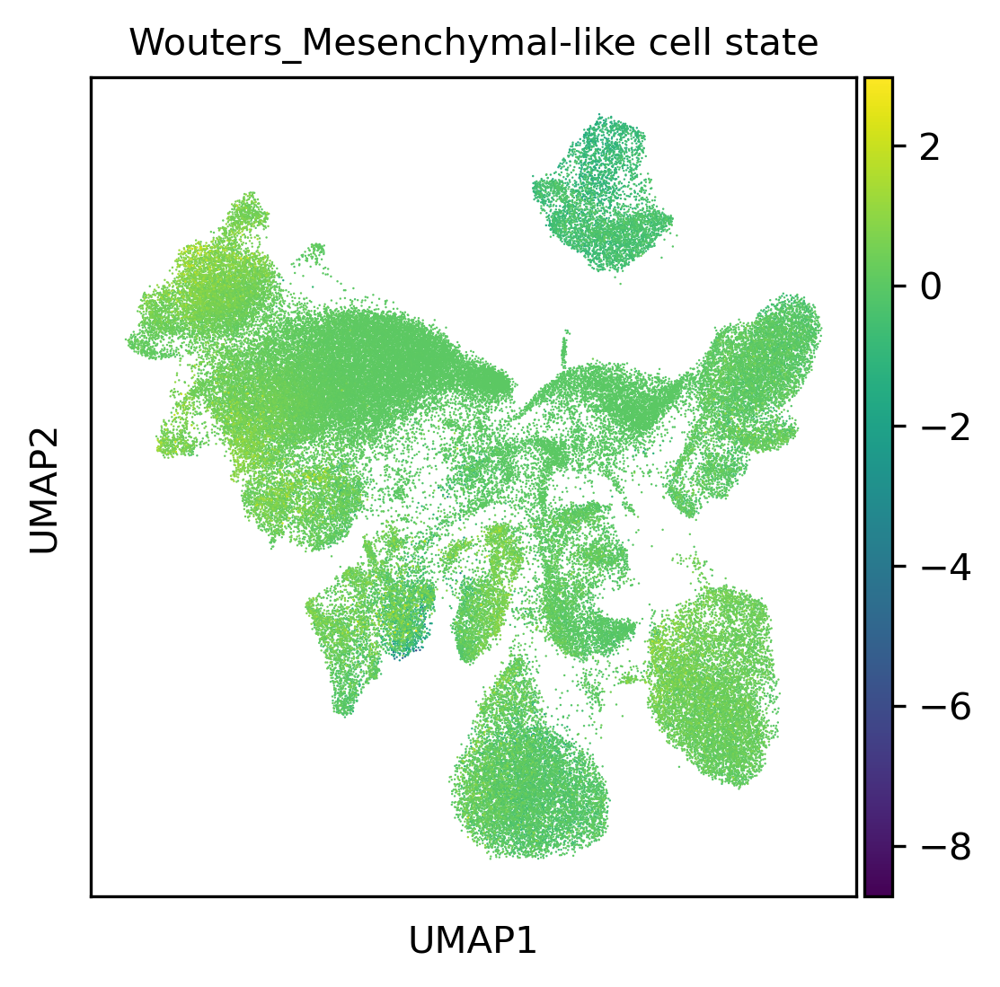

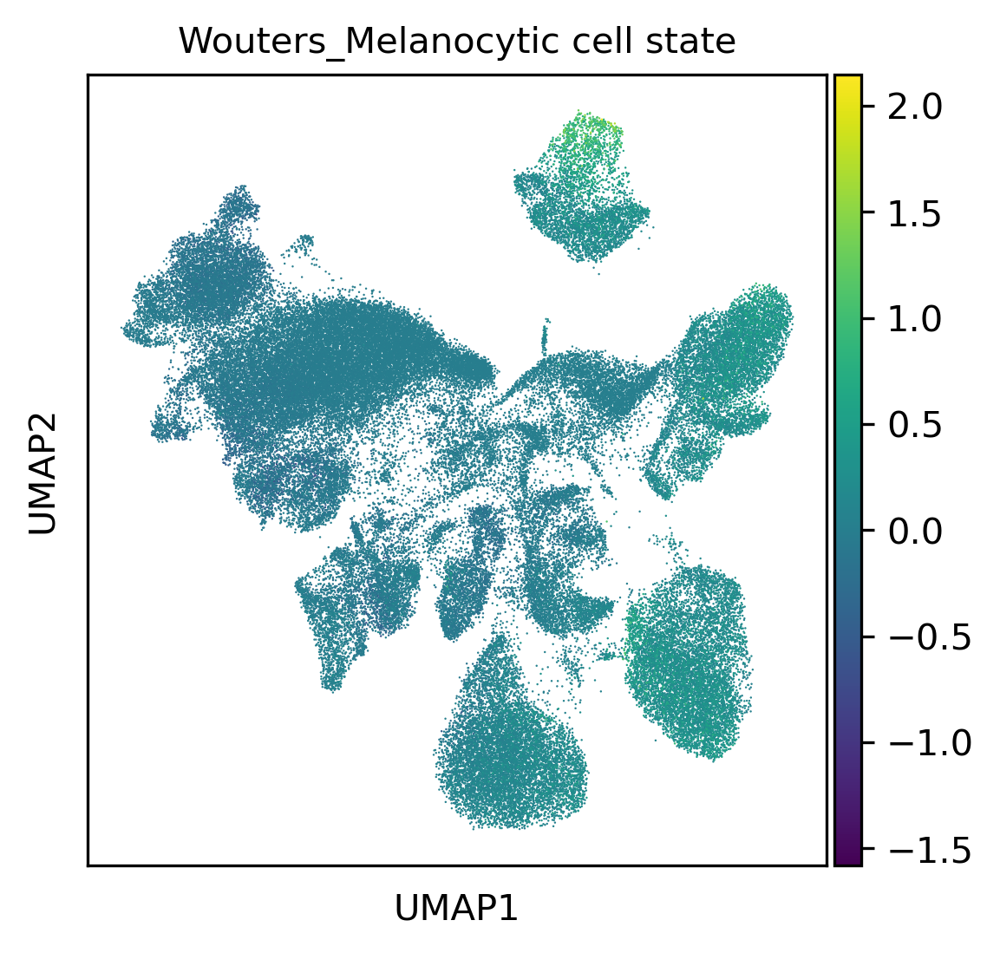

In [273]:
for wouter in wouters_names:
    sc.pl.umap(adata_hvg, color=[wouter])

### Rambow

In [274]:
rambow_signatures = GeneSignature.from_gmt('gmts/Rambow_8_signatures.gmt', field_separator='\t', gene_separator='\t')
len(rambow_signatures)

8

In [275]:
rambow_names = []
for signature_num in range(len(rambow_signatures)):
    temp_name=f"Rambow_{rambow_signatures[signature_num].name}"
    rambow_names.append(temp_name)
    
    temp_sig = list(rambow_signatures[signature_num].gene2weight)
    
    sc.tl.score_genes(adata, temp_sig, ctrl_size=50, gene_pool=None, 
                      n_bins=25, score_name=temp_name, random_state=0, copy=False, use_raw=None)
    
    #adata.var[rambow_signatures[signature_num].name] = adata.obs[rambow_signatures[signature_num].name]

computing score 'Rambow_Hypometabolic'
    finished: added
    'Rambow_Hypometabolic', score of gene set (adata.obs).
    448 total control genes are used. (0:00:05)
computing score 'Rambow_Immune'
    finished: added
    'Rambow_Immune', score of gene set (adata.obs).
    500 total control genes are used. (0:00:05)
computing score 'Rambow_Invasion'
    finished: added
    'Rambow_Invasion', score of gene set (adata.obs).
    597 total control genes are used. (0:00:05)
computing score 'Rambow_MITF'
    finished: added
    'Rambow_MITF', score of gene set (adata.obs).
    947 total control genes are used. (0:00:05)
computing score 'Rambow_mitosis'
    finished: added
    'Rambow_mitosis', score of gene set (adata.obs).
    599 total control genes are used. (0:00:05)
computing score 'Rambow_MSC'
    finished: added
    'Rambow_MSC', score of gene set (adata.obs).
    550 total control genes are used. (0:00:05)
computing score 'Rambow_Neuro'
    finished: added
    'Rambow_Neuro', score o

In [276]:
# add rambow scores to adata_hvg
for rambow in rambow_names:
    adata_hvg.obs[rambow] = adata.obs[rambow]

# Fig. EV3

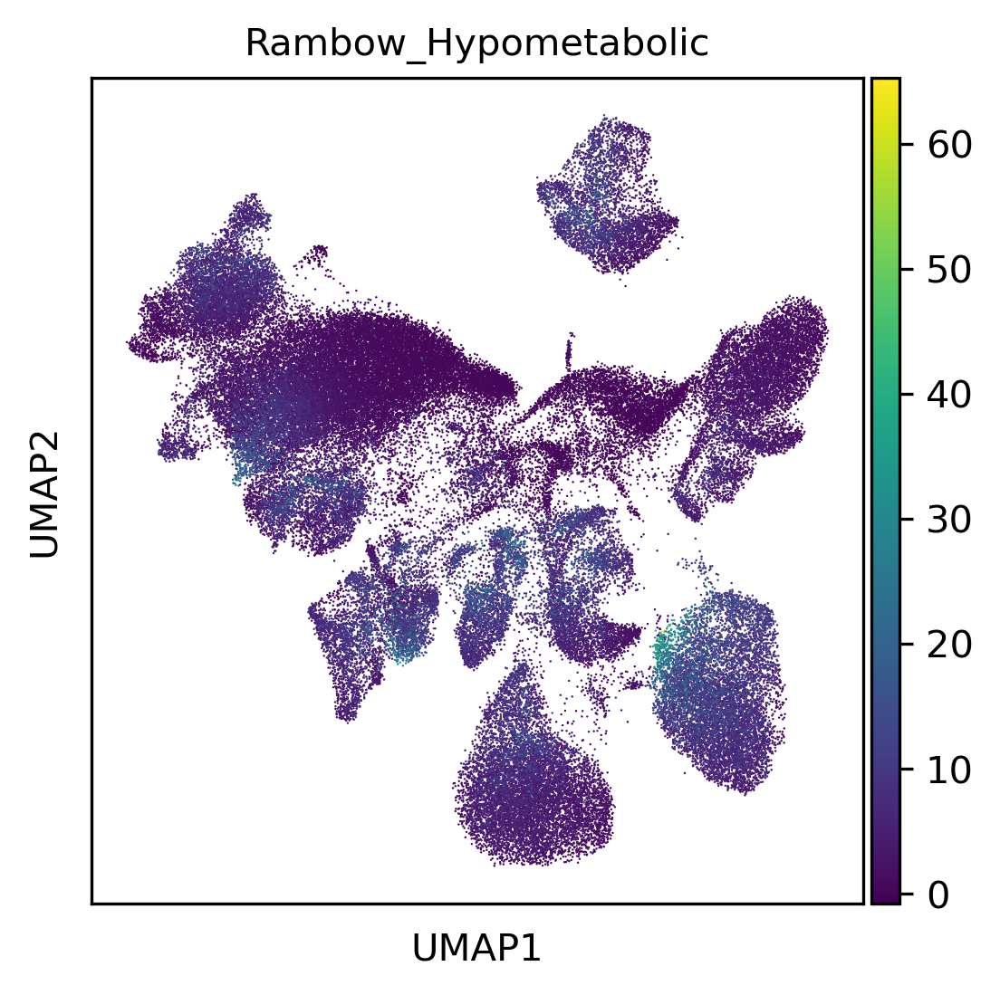

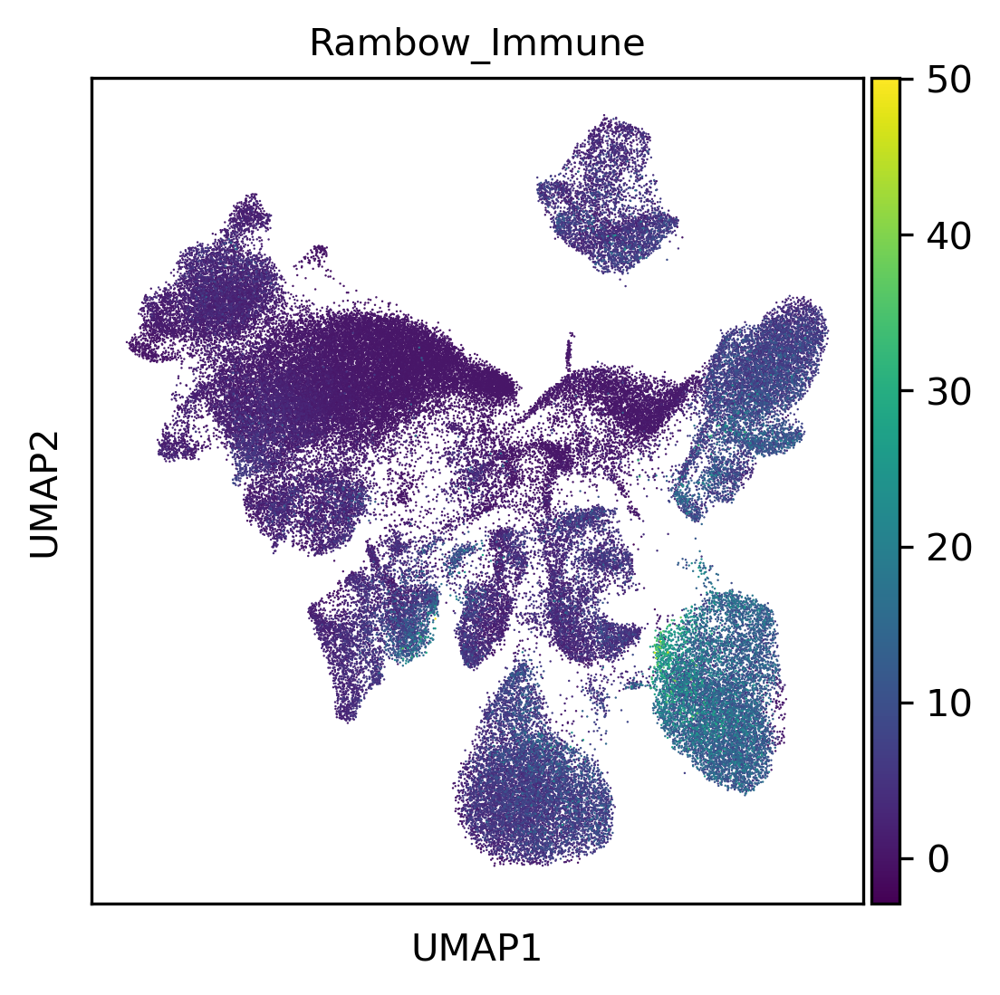

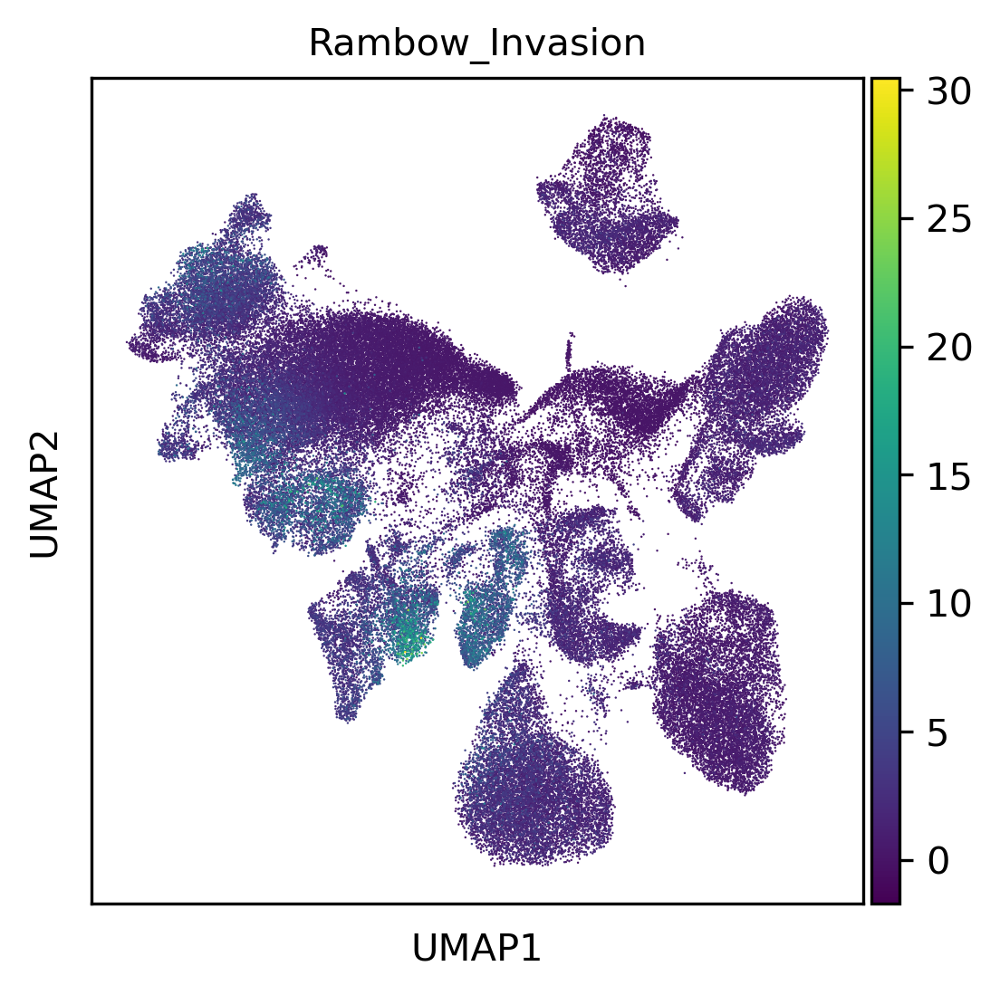

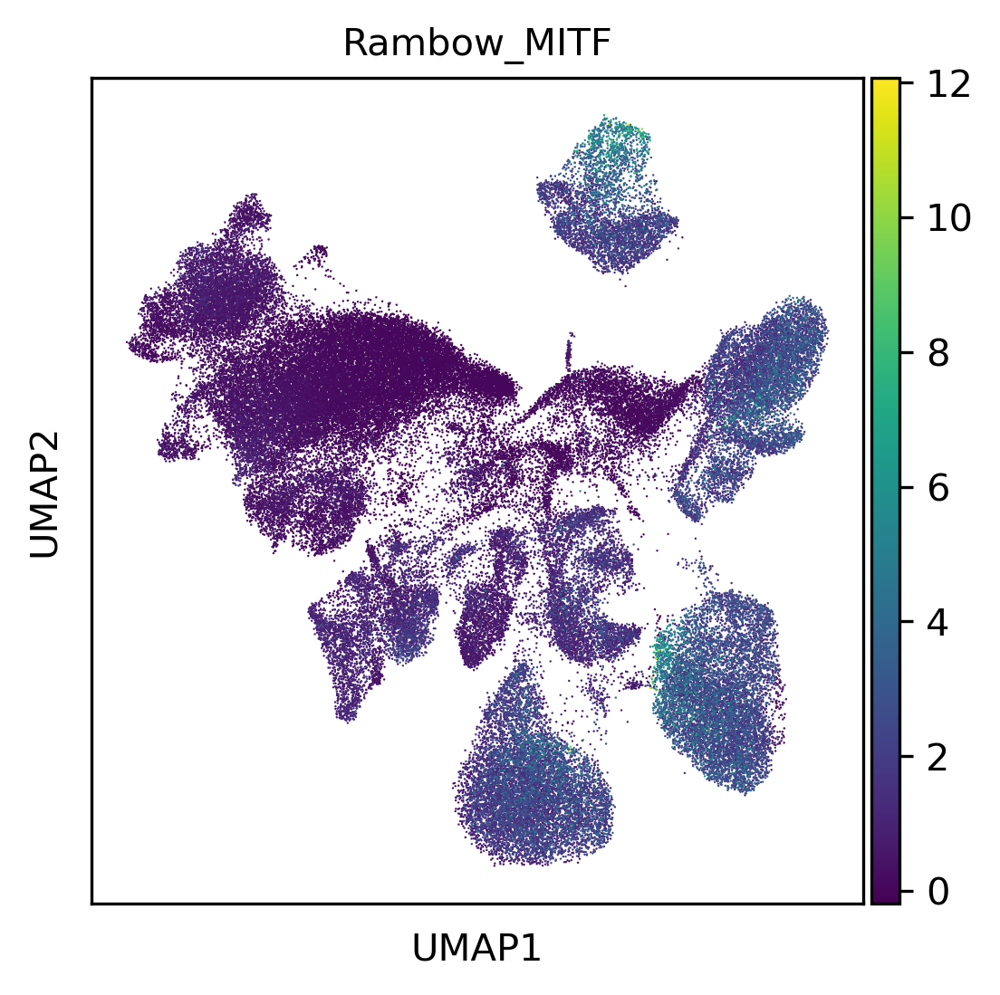

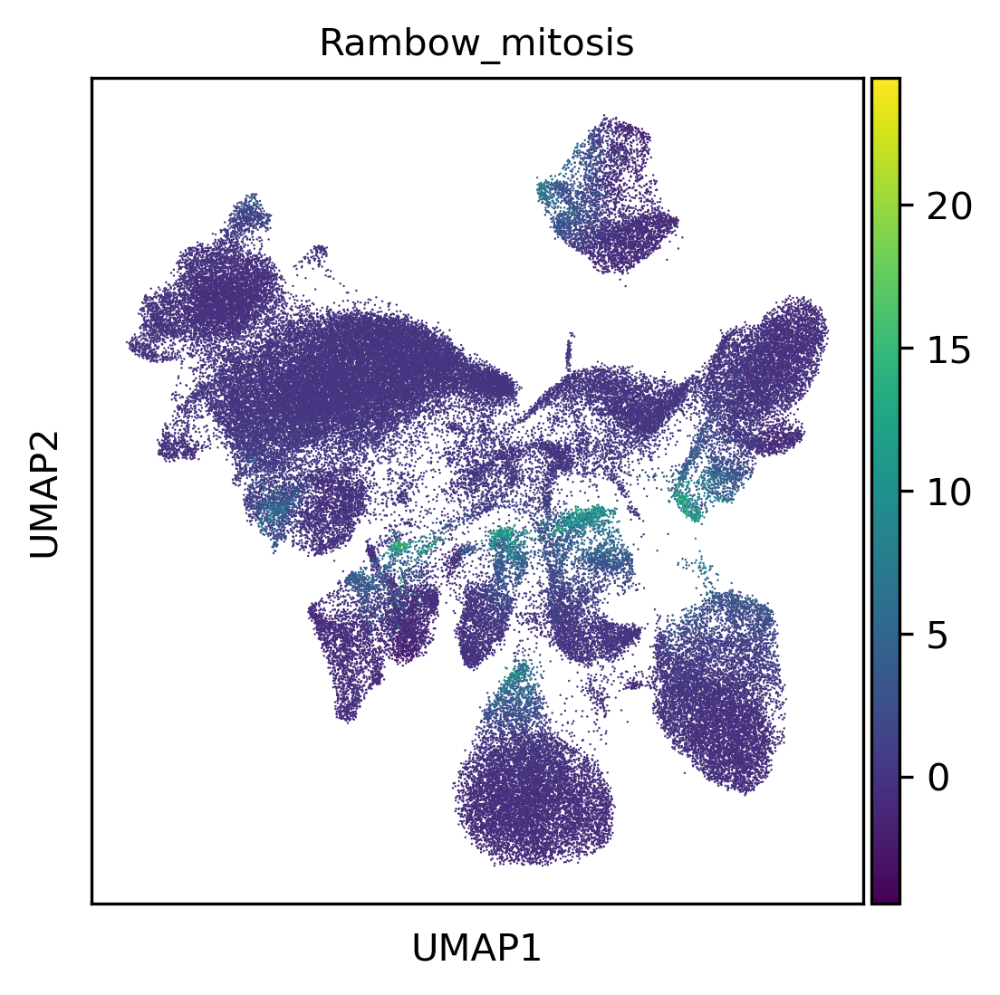

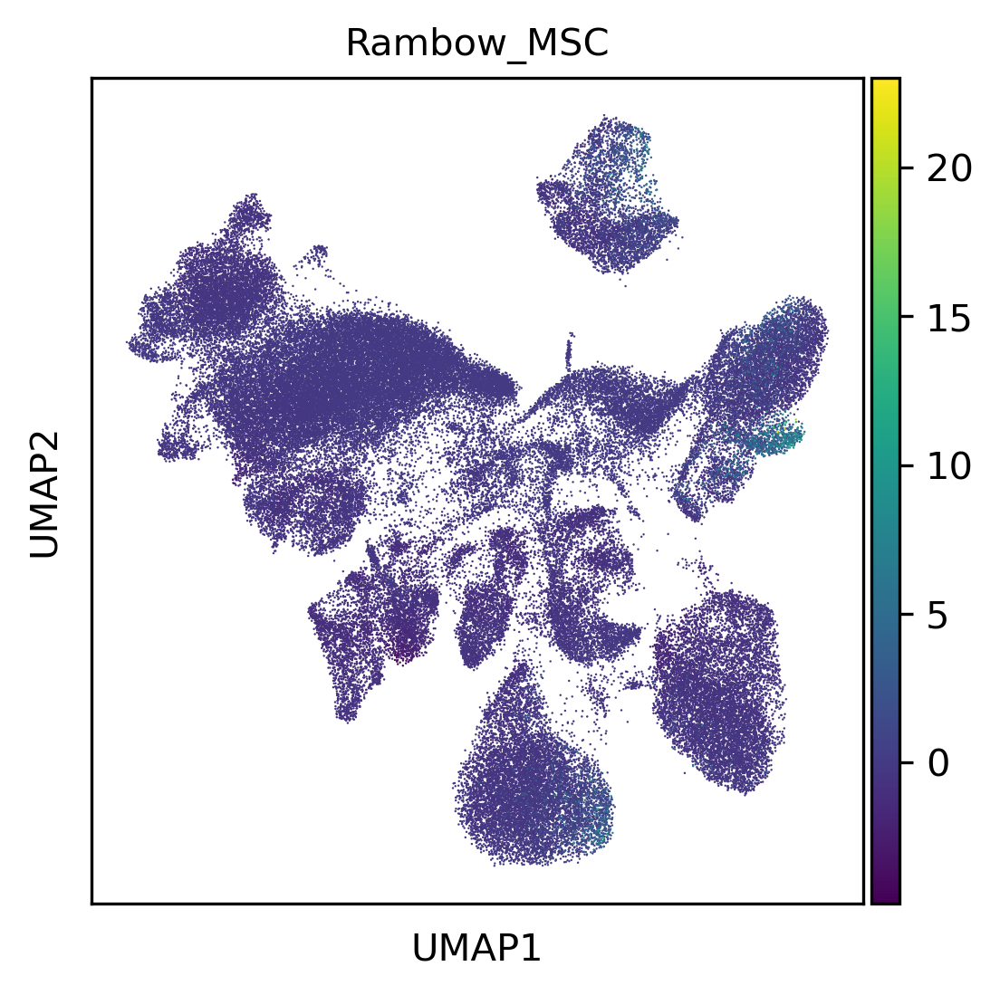

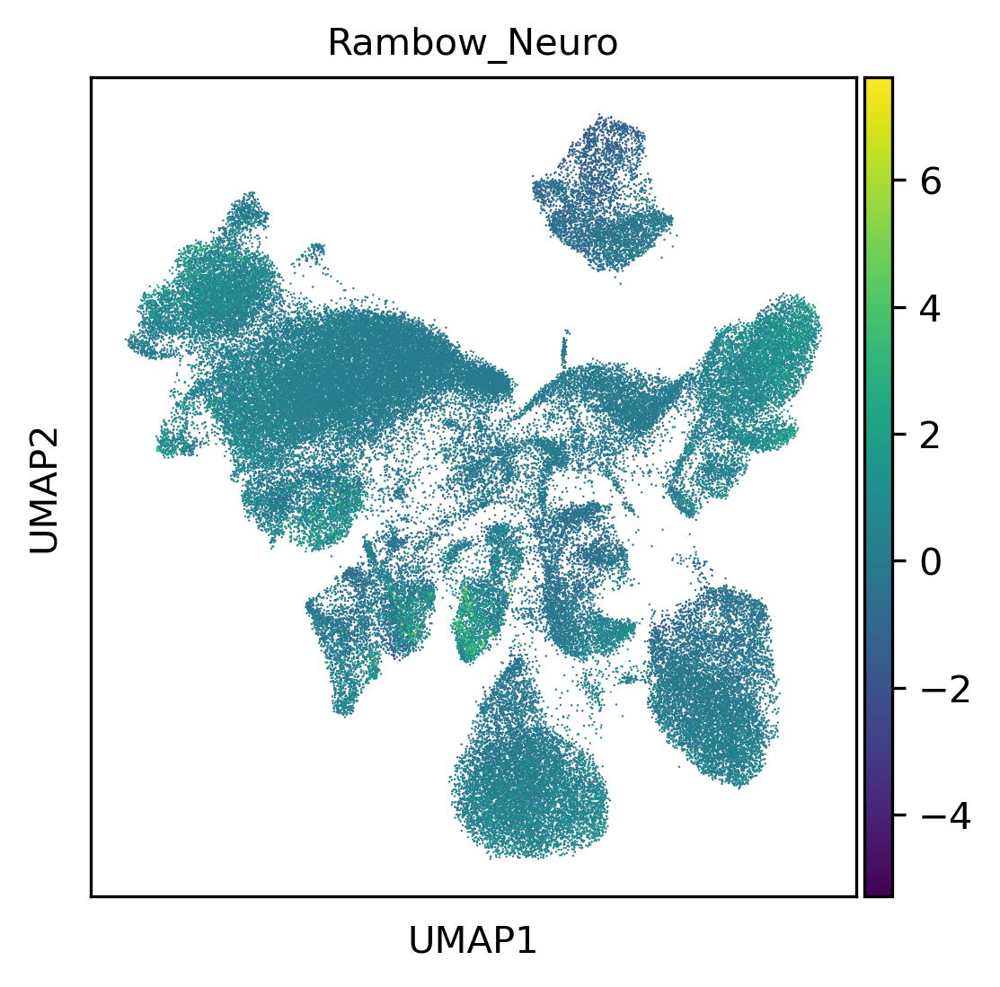

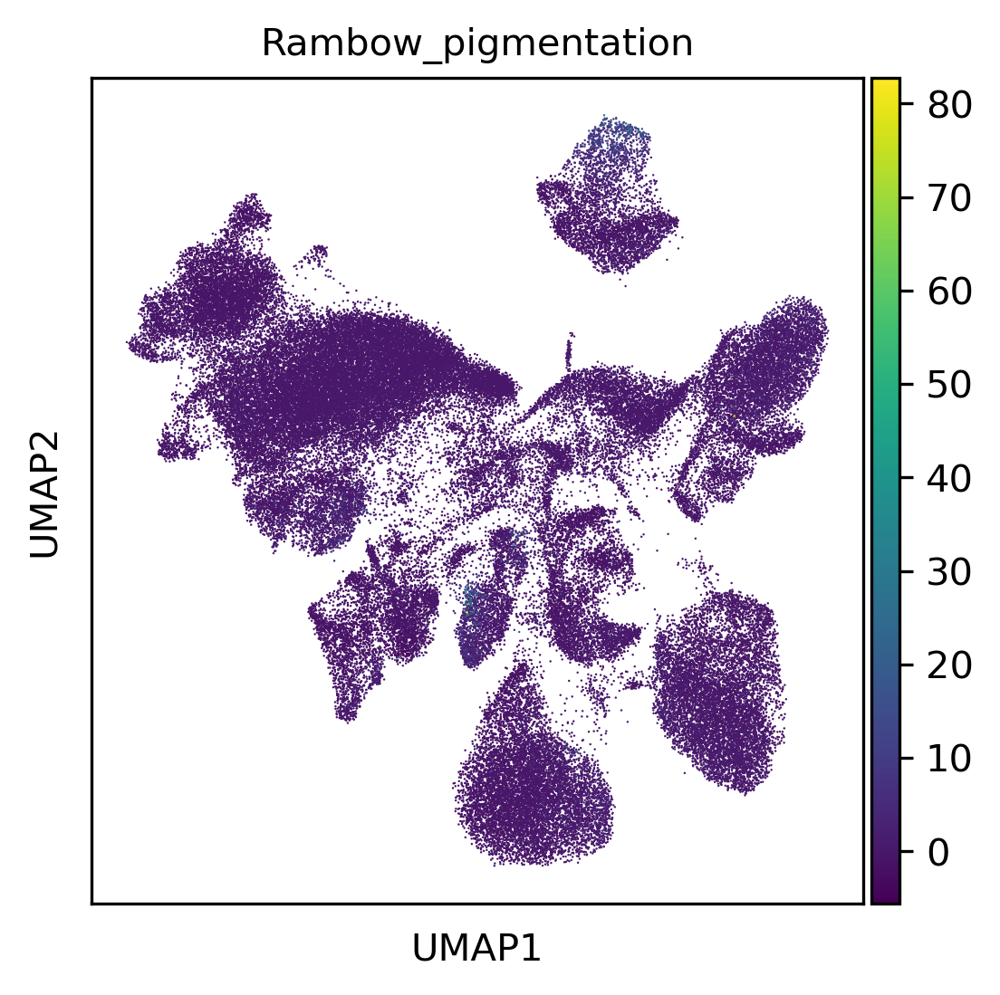

In [277]:
for rambow in rambow_names:
    sc.pl.umap(adata_hvg, color=[rambow])

### Pozniak

In [278]:
pozniak_signatures = GeneSignature.from_gmt('gmts/Pozniak_top100.gmt', field_separator='\t', gene_separator='\t')
len(pozniak_signatures)

11

In [279]:
pozniak_names = []
for signature_num in range(len(pozniak_signatures)):
    temp_name=f"Pozniak_{pozniak_signatures[signature_num].name}"
    pozniak_names.append(temp_name)
    
    temp_sig = list(pozniak_signatures[signature_num].gene2weight)
    
    sc.tl.score_genes(adata, temp_sig, ctrl_size=50, gene_pool=None, 
                      n_bins=25, score_name=temp_name, random_state=0, copy=False, use_raw=None)
    
    #adata.var[rambow_signatures[signature_num].name] = adata.obs[rambow_signatures[signature_num].name]

computing score 'Pozniak_Neural_Crest_like_top100'
    finished: added
    'Pozniak_Neural_Crest_like_top100', score of gene set (adata.obs).
    495 total control genes are used. (0:00:05)
computing score 'Pozniak_Interferon_alpha_beta_response_top100'
    finished: added
    'Pozniak_Interferon_alpha_beta_response_top100', score of gene set (adata.obs).
    898 total control genes are used. (0:00:05)
computing score 'Pozniak_Melanocytic_top100'
    finished: added
    'Pozniak_Melanocytic_top100', score of gene set (adata.obs).
    52 total control genes are used. (0:00:05)
computing score 'Pozniak_Mesenchymal_like_top100'
    finished: added
    'Pozniak_Mesenchymal_like_top100', score of gene set (adata.obs).
    402 total control genes are used. (0:00:05)
computing score 'Pozniak_Mitochondrial_low_quality_top100'
    finished: added
    'Pozniak_Mitochondrial_low_quality_top100', score of gene set (adata.obs).
    756 total control genes are used. (0:00:05)
computing score 'Poznia

In [280]:
# add pozniak scores to adata_hvg
for pozniak in pozniak_names:
    adata_hvg.obs[pozniak] = adata.obs[pozniak]

# Fig. EV3

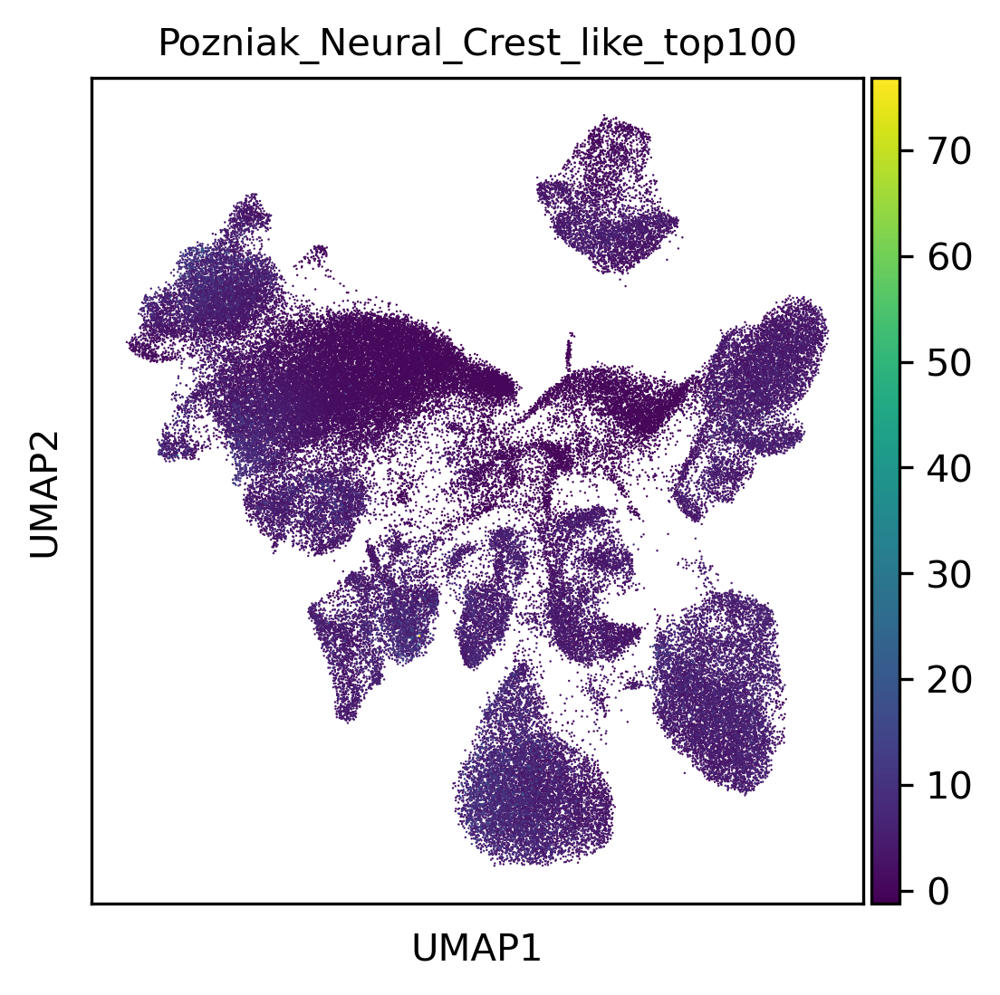

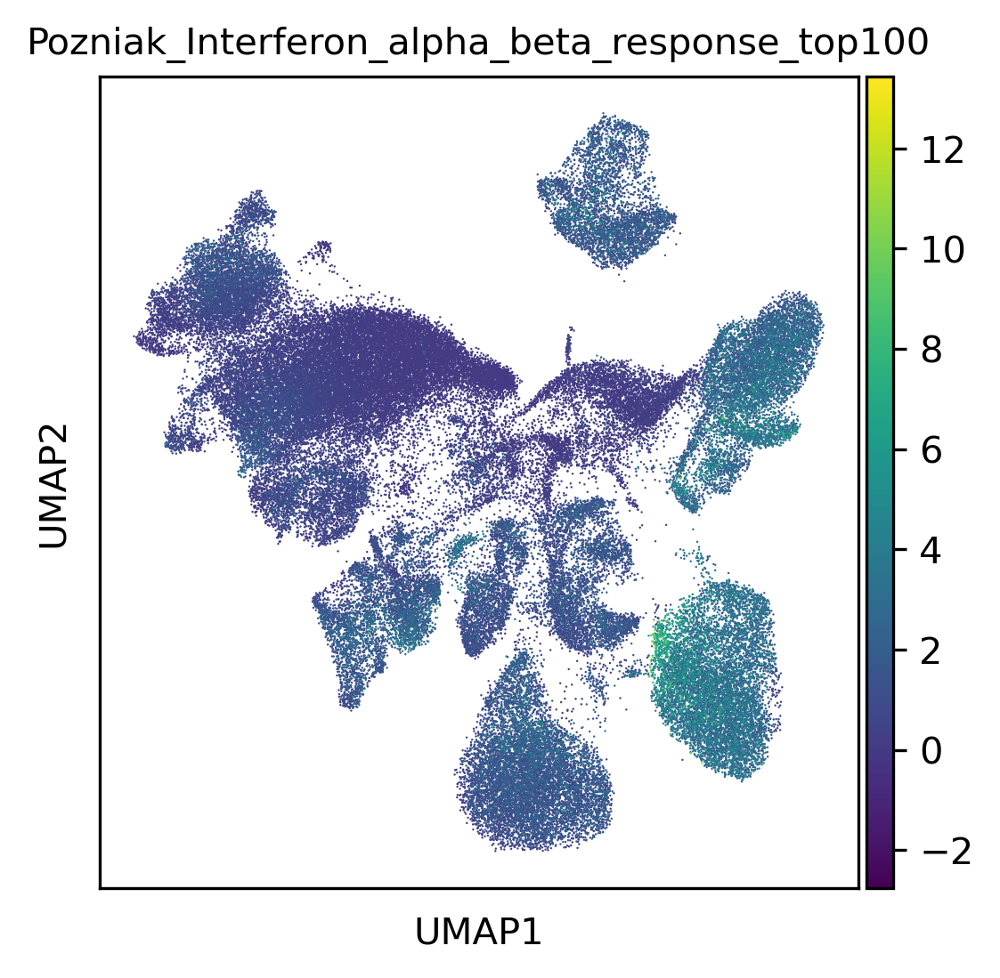

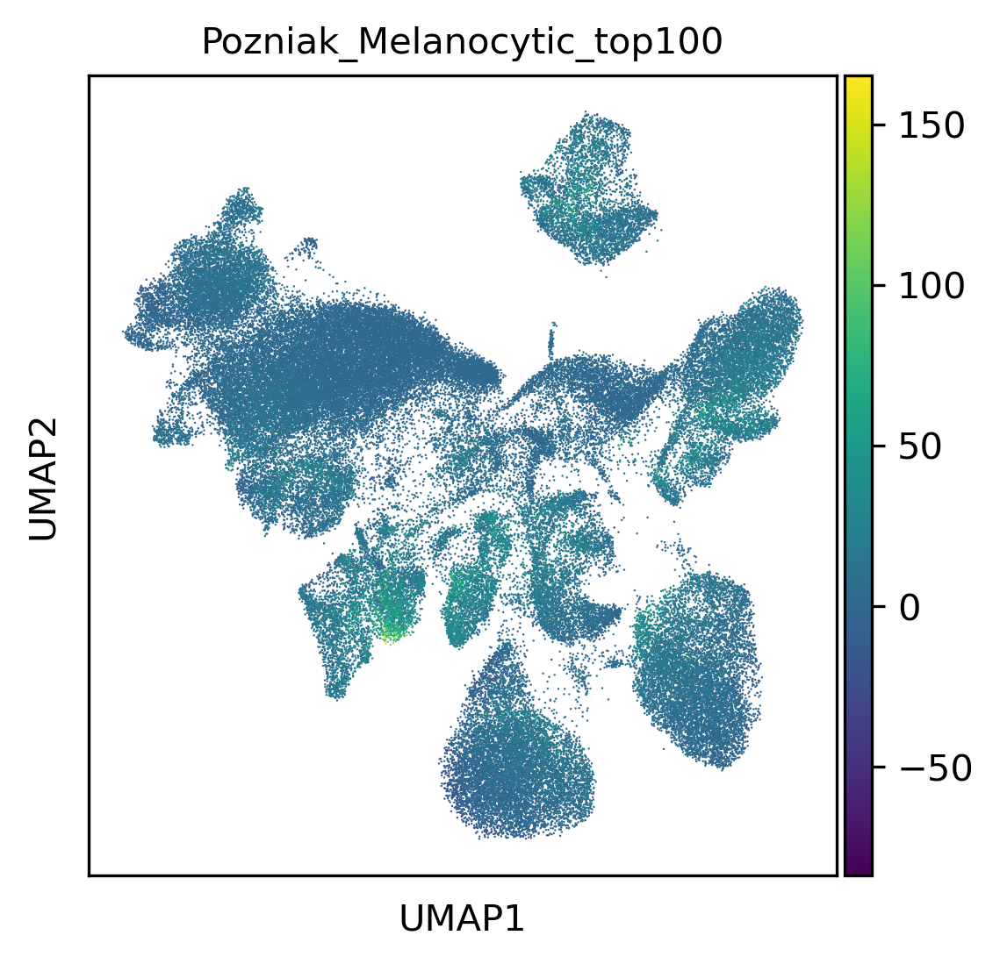

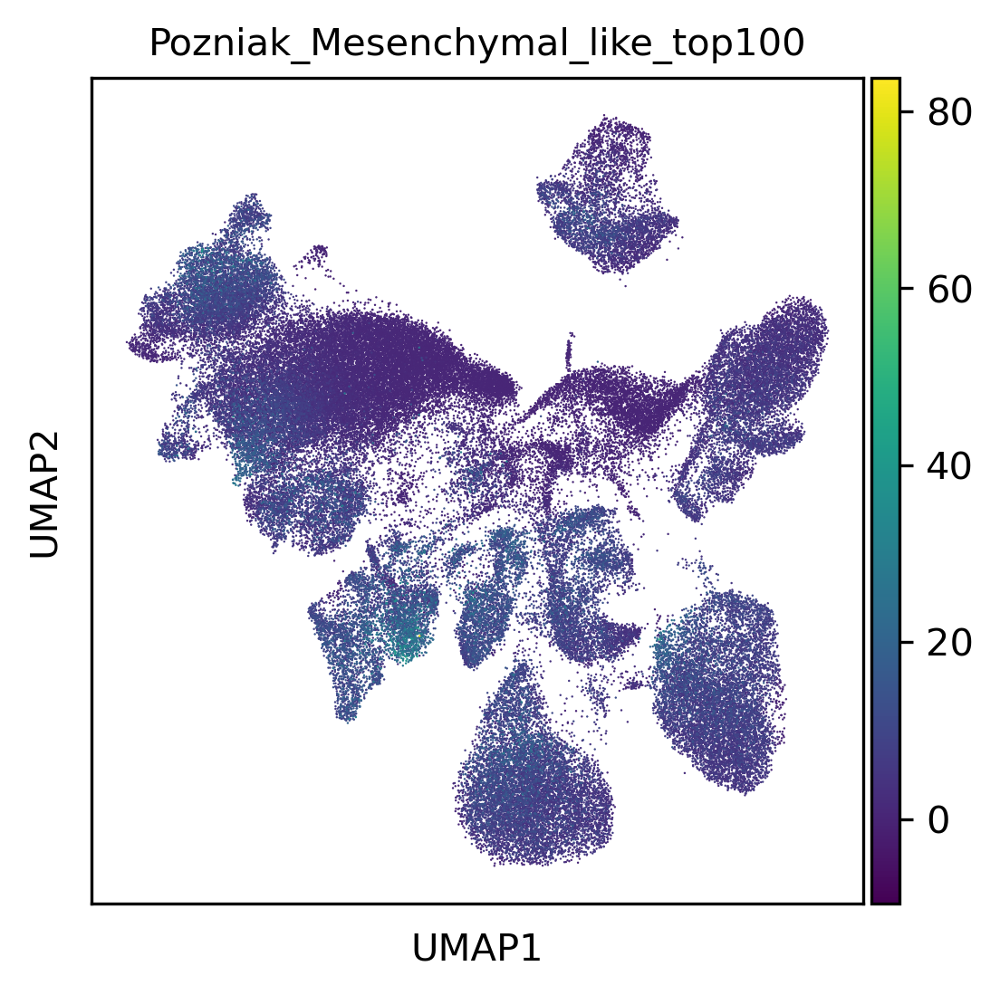

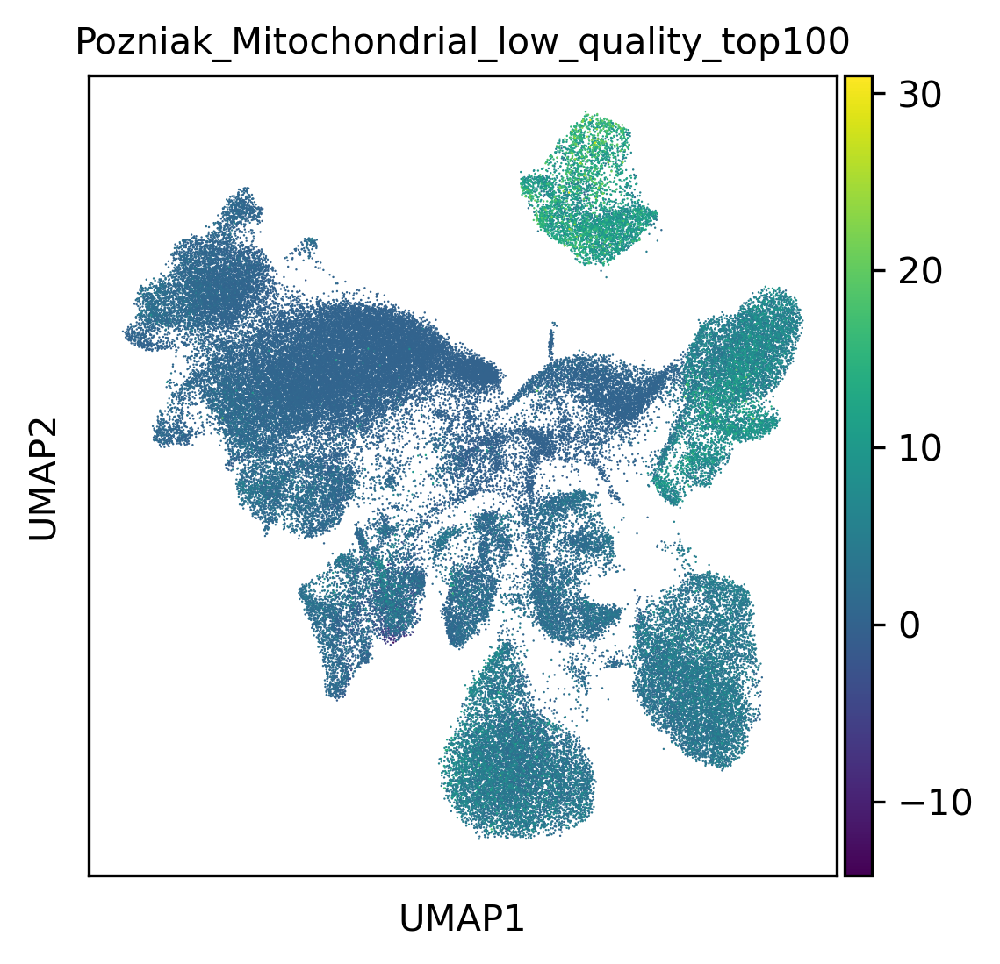

...

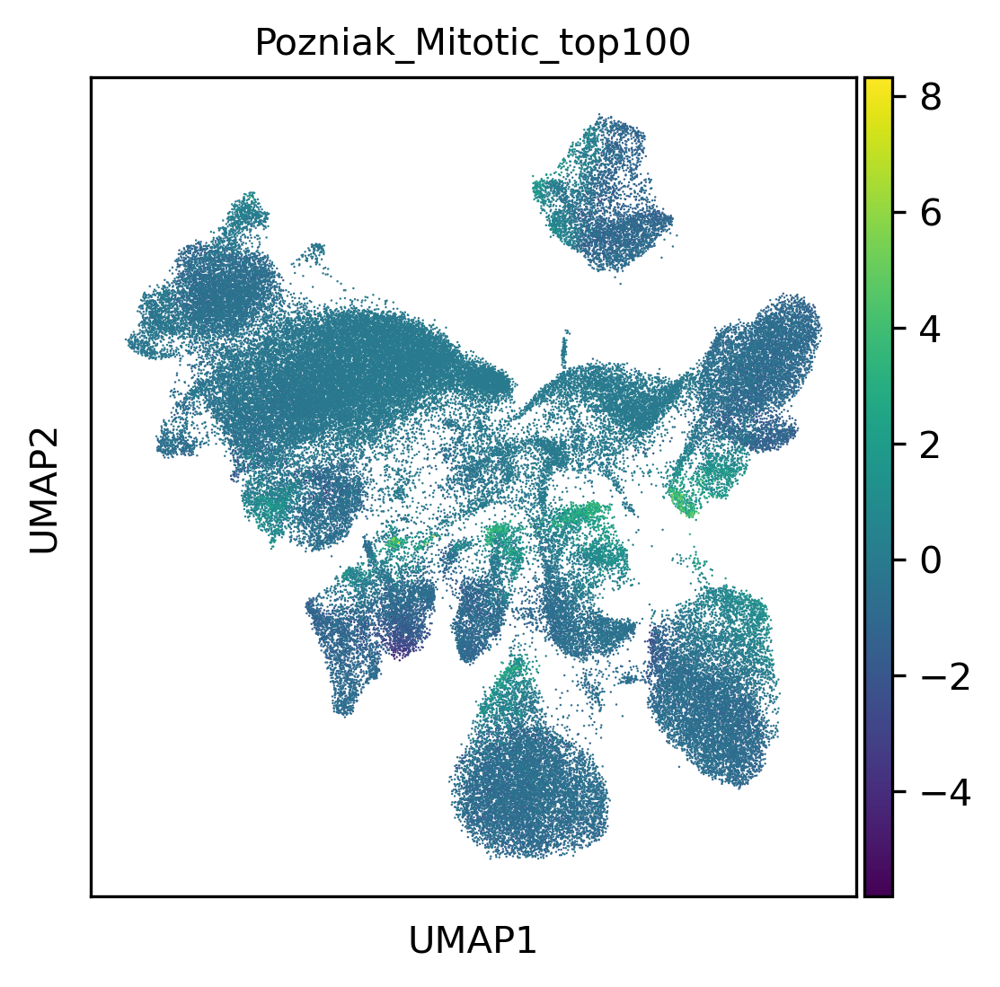

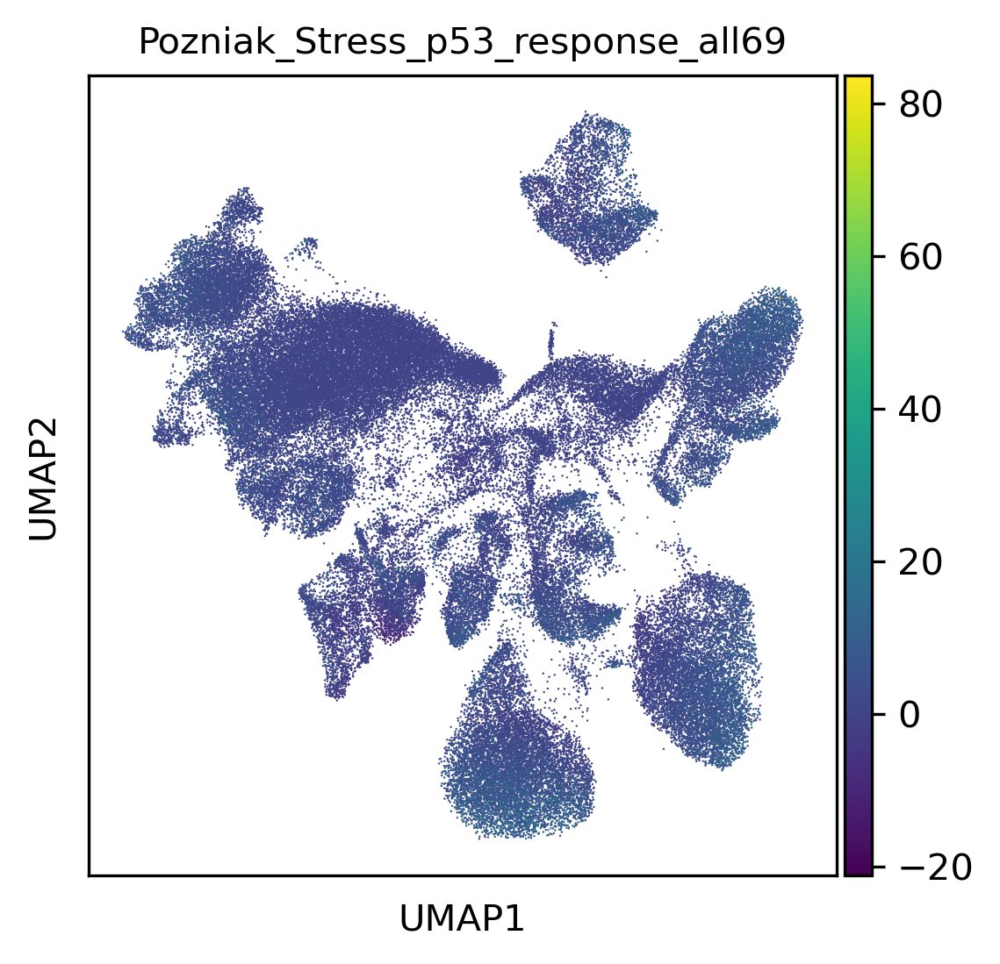

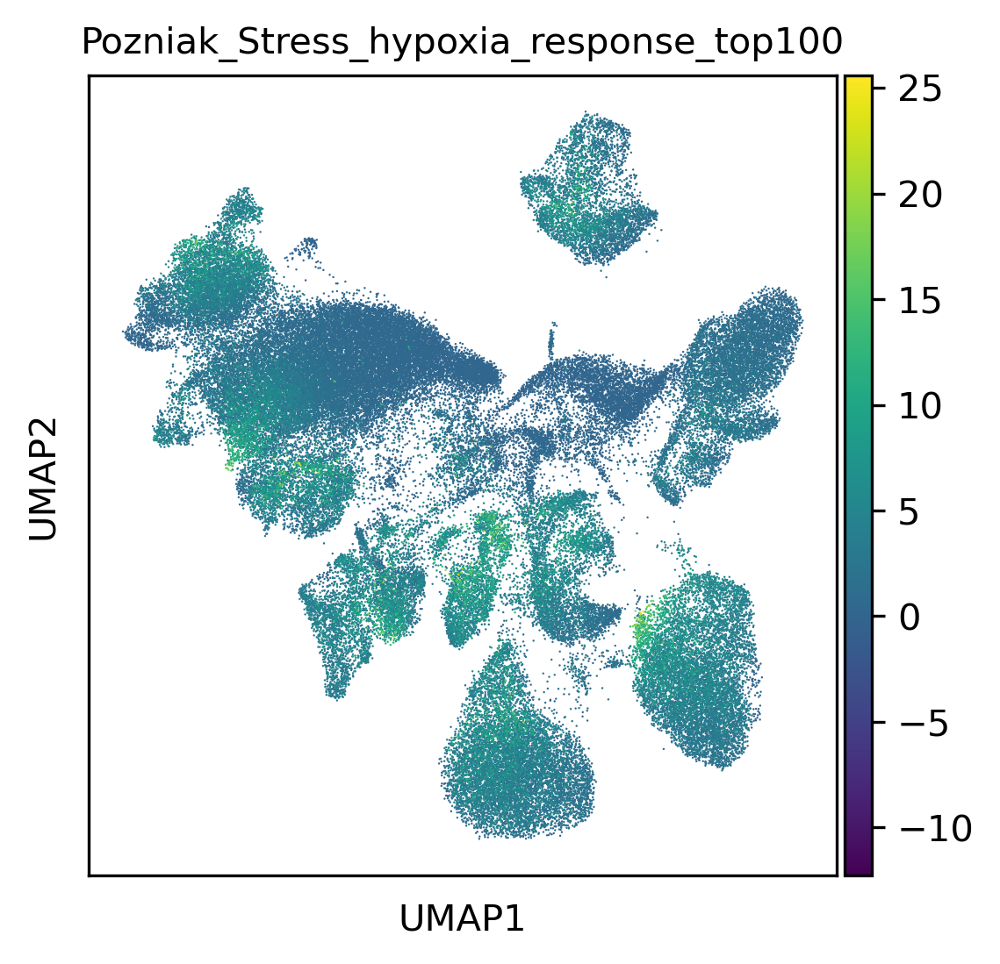

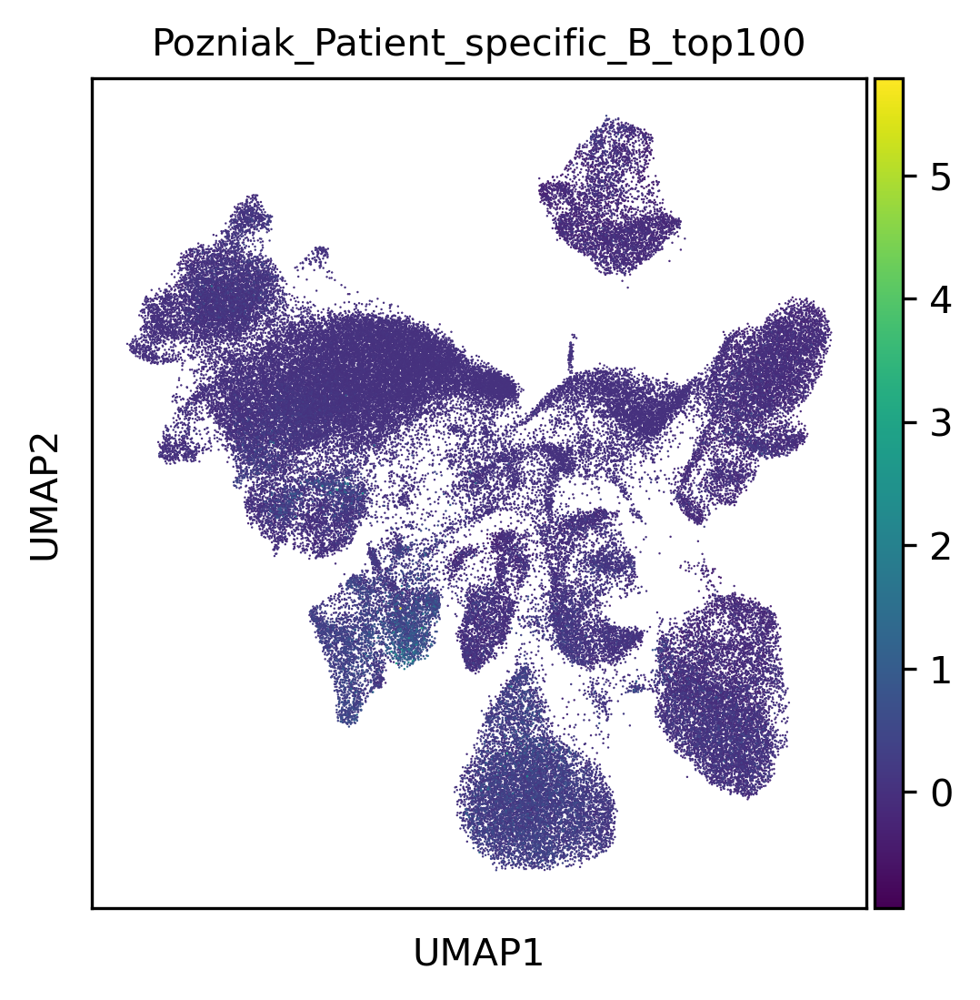

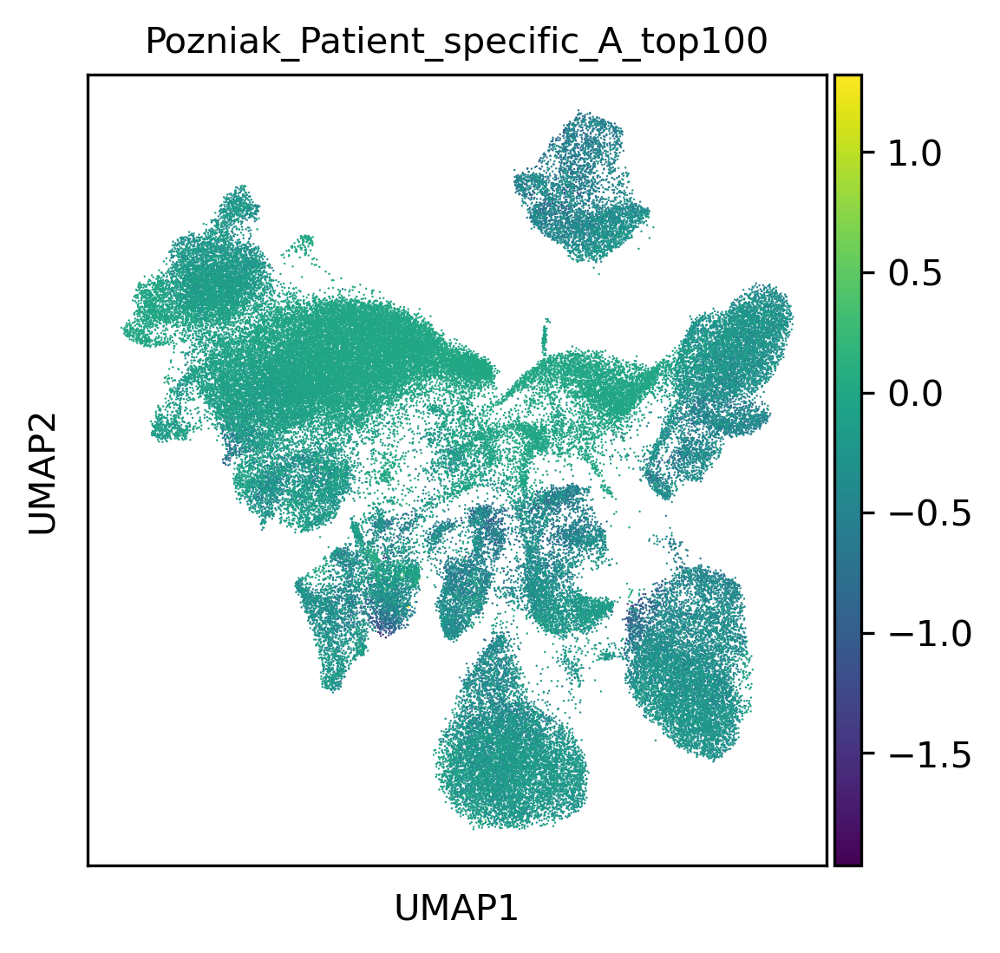

In [281]:
for pozniak in pozniak_names:
    sc.pl.umap(adata_hvg, color=[pozniak])